# P3: Retrieval Granularity: Does Chunk Shape Determine Answer Quality?

**Author:** Rania Hatrouhou, SCIPER = 342084  
**Track:** P3: Retrieval Granularity  
**Course:** CS-552 Modern NLP, Spring 2026  
**Team:** MNLP212: Rania Hatrouhou · Leïla Benjelloun · Sacha Frankhauser · Sherine Adrou Bakkali

## Overview

This notebook investigates: **does the shape of a text chunk, not just whether the right
passage was retrieved, determine whether the generator can produce a correct answer?**

We compare five chunking strategies across the full NQ Open validation split (n = 2,610)
on a shared RAG baseline: `facebook/contriever-msmarco` + FAISS + `mistralai/Mistral-7B-Instruct-v0.2`.
Every pipeline component is held constant; only the chunking strategy changes.

**Table of Contents**
- [My Individual Contribution](#sec0-contrib)
- [Section 0: Environment Setup](#sec0)
- [Section 1: Motivation & Milestone 2 Insights](#sec1)
- [Section 2: Chunking Strategies Explained](#sec2)
- [Section 3: Main Results at Scale (n = 2,610)](#sec3)
- [Section 4: The Core: EM|Hit, Isolating Generation Failures](#sec4)
  - [Section 4.1: Prediction Verbosity, A Third Failure Mode](#sec5-verbosity)
  - [Section 4.2: Abstention Rate, The Refusal Failure Mode](#sec4-2)
- [Section 5: Retrieval vs. Generation Decomposition (Scatter)](#sec5)
- [Section 6: The Controlled Sentence Ablation: Shared FAISS Index, Different Context](#sec6)
  - [Section 6.1: Paragraph Degeneration in Small-to-Big](#sec6-1-degeneration) 
  - [Section 6.2: Embedding Precision Analysis](#sec6-2-embedding)
- [Section 7: Qualitative Case Studies](#sec7)
- [Section 8: Failure Taxonomy](#sec8)
- [Section 9: Performance Breakdown by Question Type](#sec9)
  - [Section 9.1: When Semantics Wins, Unique Strategy Advantages](#sec3-sem)
- [Section 10: Hybrid Router Analysis](#sec10)
  - [Section 10.1: Oracle Upper Bound & Strategy Agreement](#sec10-oracle)
- [Section 11: Chunk Length Distributions](#sec11)
- [Section 12: Conclusion](#sec12)


<a id='sec0-contrib'></a>
## My Individual Contribution

### What I built

**Five chunking strategies.** In any RAG pipeline, two decisions are made independently:
**(1) what text gets embedded and searched** (the retrieval unit) and
**(2) what text the LLM actually reads to produce an answer** (the generation unit).
Most systems use the same chunk for both. The strategies below explore the effect
of varying that choice.

| Strategy | What gets searched against the query | What the LLM reads to answer | Problem it solves |
|----------|--------------------------------------|------------------------------|-------------------|
| **Fixed** | A 256-word block of text | That same block | Baseline: simple and complete, but the block may contain irrelevant surrounding text |
| **Semantic** | A span of sentences on the same topic | That same span | Avoids cutting mid-topic by splitting wherever the subject changes (detected via embedding similarity) |
| **Small-to-Big** | A single sentence (precise) | The full paragraph the sentence came from (rich) | Searches precisely but reads with context : retrieval and reading are *decoupled* |
| **Sentence-Only** | A single sentence | That same sentence | Maximum search precision, but the LLM gets very little context to work with |
| **Sentence-Window** | A single sentence | That sentence plus the one before and after | A middle ground: precise search, minimal but local reading context |

**Shared-index builder** (`build_sentence_variants.py`): Small-to-Big,
Sentence-Only, and Sentence-Window all share the **exact same 10.9M-vector FAISS
binary** (copied verbatim, not re-encoded). Only the lookup table (`chunks.pkl`)
differs. This turns the three into a **controlled ablation**: identical retrieval
scores and rankings, different generation context; any EM difference is a pure
generation effect, not a retrieval effect.

**P3 pipeline** (`pipeline_p3.py`): Pluggable runner that swaps only the
chunker while keeping the retriever, generator, and evaluator identical to the
shared team baseline. This ensures every comparison is a single-variable experiment.

**Hybrid router** (`pipeline_p3_hybrid.py`): Selects a chunking strategy
per query at inference time. Two routing signals evaluated:
- **Rule-based**: maps question type (`who` / `when` / `what` / …) to the
  best-performing strategy on a held-out derivation split
- **Score-based**: routes to whichever strategy's FAISS index returns the
  highest top-1 cosine similarity for the incoming query

### Key methodological contribution: EM|Hit decomposition

Standard RAG evaluation reports aggregate Exact Match, which conflates two independent
failure modes. I introduced the **EM|Hit** metric (Exact Match conditioned on retrieval
success) to separate them:

- **EM|Hit**: generation quality: did the generator extract the answer from the chunks?
- **Hit Rate**: retrieval coverage: did the correct answer appear in any retrieved chunk?
- **Generation Loss**: (n_hit − em_hit) / n: fraction of ALL queries where the answer
  was present but the generator still failed

This decomposition reveals that chunk shape is primarily a **generation lever**, not a
retrieval lever, the central finding of this notebook.


<a id='sec0'></a>
## Section 0: Environment Setup

In [1]:
import json
import os
import sys
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from pathlib import Path
from collections import defaultdict
from scipy.stats import spearmanr

# Repository paths 
REPO_ROOT    = Path('..').resolve()
P3_DIR       = REPO_ROOT / 'code' / 'p3_retrieval_granularity'
CHUNKERS_DIR = P3_DIR / 'chunkers'
BASELINE_DIR = REPO_ROOT / 'code' / 'baseline'

for d in [str(P3_DIR), str(CHUNKERS_DIR), str(BASELINE_DIR)]:
    if d not in sys.path:
        sys.path.insert(0, d)

# Results: committed to the GitHub repo 
# All inference was pre-run on the RCP cluster; outputs are in results/.
RESULTS_DIR = REPO_ROOT / 'results'
assert RESULTS_DIR.exists(), (
    f"results/ not found at {RESULTS_DIR}. "
    "Make sure you are running from the repo root or notebooks/ directory."
)

# FAISS indices: cluster-only, not in the repo (32 GB each) 
# INDEX_DIR is set only when the pre-built indices are present on the mounted
# cluster scratch. In all other environments (including grading) INDEX_DIR=None
# and cells that use it display pre-verified results instead of crashing.
_faiss_root = Path('/scratch/faiss_index')
INDEX_DIR   = _faiss_root     if (_faiss_root / 'p3_small_to_big' / 'faiss.index').exists() else None

# HuggingFace cache 
# Models and datasets are loaded from public HuggingFace repositories.
# Cache is placed on cluster scratch when available for faster repeat loads.
HF_HOME = Path('/scratch/hf_cache') if Path('/scratch').exists()           else Path.home() / '.cache' / 'huggingface'
os.makedirs(HF_HOME, exist_ok=True)

os.environ['HF_HOME']            = str(HF_HOME)
os.environ['HF_DATASETS_CACHE']  = str(HF_HOME / 'datasets')
os.environ['TRANSFORMERS_CACHE'] = str(HF_HOME / 'transformers')

# Plotting defaults 
plt.rcParams.update({
    'figure.dpi': 130,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

STRATEGIES   = ['fixed', 'semantic', 'small_to_big', 'sentence_only', 'sentence_window']
SHORT_LABELS = {
    'fixed': 'Fixed', 'semantic': 'Semantic', 'small_to_big': 'Small-to-Big',
    'sentence_only': 'Sent-Only', 'sentence_window': 'Sent-Window',
}
COLORS = {
    'fixed': '#4C72B0', 'semantic': '#DD8452', 'small_to_big': '#55A868',
    'sentence_only': '#C44E52', 'sentence_window': '#8172B2',
}

print('Setup complete.')
print(f'  REPO_ROOT    : {REPO_ROOT}')
print(f'  RESULTS_DIR  : {RESULTS_DIR}  (exists={RESULTS_DIR.exists()})')
print(f'  INDEX_DIR    : {INDEX_DIR}  ({"available" if INDEX_DIR else "not available — FAISS cells will skip"})')
print(f'  HF_HOME      : {HF_HOME}')


Setup complete.
  REPO_ROOT    : /scratch/open-project-m3-mnlp212
  RESULTS_DIR  : /scratch/open-project-m3-mnlp212/results  (exists=True)
  INDEX_DIR    : /scratch/faiss_index  (available)
  HF_HOME      : /scratch/hf_cache


In [2]:
# Load NQ Open dataset from HuggingFace 
from datasets import load_dataset

print('Loading NQ Open validation split...')
nq_open = load_dataset('nq_open', split='validation')
print(f'NQ Open: {len(nq_open):,} validation questions')
print('\nSample questions:')
for ex in nq_open.select(range(3)):
    print(f'  Q: {ex["question"]}')
    print(f'  A: {ex["answer"]}')

Loading NQ Open validation split...
NQ Open: 3,610 validation questions

Sample questions:
  Q: when was the last time anyone was on the moon
  A: ['14 December 1972 UTC', 'December 1972']
  Q: who wrote he ain't heavy he's my brother lyrics
  A: ['Bobby Scott', 'Bob Russell']
  Q: how many seasons of the bastard executioner are there
  A: ['one', 'one season']


In [3]:
# Load contriever-msmarco from HuggingFace 
# This is the retrieval model used across all P3 strategies.
# Loading it here lets us demonstrate semantic chunking live and inspect embeddings.
from sentence_transformers import SentenceTransformer

print('Loading facebook/contriever-msmarco...')
encoder = SentenceTransformer('facebook/contriever-msmarco', cache_folder=str(HF_HOME))
print(f'Encoder loaded. Embedding dim: {encoder.get_sentence_embedding_dimension()}')

The Transformer `cache_dir` argument is deprecated. Please pass `cache_dir` via `model_kwargs`, `processor_kwargs`, and/or `config_kwargs` instead.


Loading facebook/contriever-msmarco...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 35037.63it/s]


Encoder loaded. Embedding dim: 768


### Helper functions & result loading

The cells below load all pre-computed result JSONs and define three helpers used
throughout the notebook:

| Helper | Purpose |
|--------|---------|
| `is_hit(r)` | True if any gold answer appears verbatim in the retrieved chunks |
| `is_em(r)` | True if prediction exactly matches any gold answer (case-insensitive) |
| `qtype(q)` | Classify question by leading keyword, see classification rules below |

**`qtype` classification rules (prefix match, first match wins):**

| Label | Trigger prefixes |
|-------|-----------------|
| `how` | *how many, how much, how long, how old, how far, how* |
| `who` | *who* |
| `when` | *when, what year, what date, in what year* |
| `where` | *where* |
| `what` | *what, which* |
| `other` | everything else |


In [4]:
# Load all pre-computed result JSONs (n = 2,610)    
results = {}
for name in STRATEGIES:
    path = RESULTS_DIR / f'p3_{name}_n2610.json'
    with open(path) as f:
        results[name] = json.load(f)['results']

# Load baseline (n=100) for M2 reference
with open(RESULTS_DIR / 'baseline.json') as f:
    baseline_data = json.load(f)
baseline_results  = baseline_data['results']
baseline_metrics  = baseline_data['metrics']

# Load hybrid router result
with open(RESULTS_DIR / 'p3_hybrid_rule_n2610.json') as f:
    hybrid_data = json.load(f)

print(f'Loaded {len(STRATEGIES)} strategies, each n={len(results["fixed"]):,} questions')
print(f'Baseline: n={baseline_metrics["n_samples"]}')

# Helper functions 

def is_hit(r):
    """Gold answer appears anywhere in the retrieved chunks."""
    text = ' '.join(r['chunks']).lower()
    return any(a.lower() in text for a in r['gold_answers'])

def is_em(r):
    """Exact match between prediction and any gold answer (case-insensitive)."""
    pred = r['prediction'].strip().lower()
    return any(pred == a.strip().lower() for a in r['gold_answers'])

def is_soft_em(r):
    """Prediction CONTAINS any gold answer as a substring (verbosity-tolerant).
    Unlike hard EM, this returns True even if the answer is embedded in a longer
    sentence, e.g. pred='It was built in 1889.' matches gold='1889'.
    """
    pred = r['prediction'].strip().lower()
    return any(a.strip().lower() in pred for a in r['gold_answers'])

# Patterns that indicate the model refused to answer rather than extracting.
_ABSTENTION_PATS = [
    'context does not', 'not provide', 'no information', 'cannot find',
    'not found in', 'does not mention', 'not mentioned', "i don",
    'cannot provide', 'the passage does not', 'there is no',
    'no context', 'unable to find', 'not stated',
]

def is_abstention(r):
    """Model refuses to answer ('The context does not provide...' etc.).
    Abstentions are generation failures independent of verbosity wrapping:
    the model produces no answer at all rather than a verbose one.
    """
    pred = r['prediction'].lower()
    return any(p in pred for p in _ABSTENTION_PATS)

def qtype(q):
    q = q.strip().lower()
    for prefixes, label in [
        (('how many','how much','how long','how old','how far','how'), 'how'),
        (('who',), 'who'),
        (('when','what year','what date','in what year'), 'when'),
        (('where',), 'where'),
        (('what','which'), 'what'),
    ]:
        if any(q.startswith(p) for p in prefixes):
            return label
    return 'other'

#  Pre-compute per-result flags 
for name in STRATEGIES:
    for r in results[name]:
        r['_hit']      = is_hit(r)
        r['_em']       = is_em(r)
        r['_soft_em']  = is_soft_em(r)
        r['_abstain']  = is_abstention(r)
        r['_qt']       = qtype(r['question'])
        r['_mean_clen'] = (
            sum(len(c.split()) for c in r['chunks']) / len(r['chunks'])
            if r['chunks'] else 0
        )

print('Per-result flags computed: _hit, _em, _soft_em, _abstain, _qt, _mean_clen')


Loaded 5 strategies, each n=2,610 questions
Baseline: n=100
Per-result flags computed: _hit, _em, _soft_em, _abstain, _qt, _mean_clen


### Metrics helper: `compute_full_metrics`

Computes all per-strategy statistics used downstream. Key fields:

| Field | Formula | Meaning |
|-------|---------|---------|
| `em` | stored exact match | Overall end-to-end accuracy |
| `hit` | stored hit rate | Fraction where gold answer is in chunks |
| `em_given_hit` | EM on hit subset | Generation quality when retrieval succeeds (extraction) |
| `em_given_miss` | EM on miss subset | Parametric accuracy when retrieval fails |
| `gen_loss` | (n_hit − em_hit) / n | Fraction of **all** queries where answer was present but generator failed |
| `soft_em` | soft-EM over all queries | Verbosity-tolerant accuracy (prediction *contains* gold) |
| `soft_em_given_hit` | soft-EM on hit subset | EM\|Hit without exact-match penalty |
| `verbosity_loss` | soft_em − em | EM lost **purely** to verbose answer wrapping |
| `abstention_cnt` | count of abstaining predictions | Raw model refusal count |
| `abstention_rate` | abstention_cnt / n | Fraction of queries where model refused |
| `false_abstain_rate` | abstentions with hit=True / n | Refused despite answer being in context |
| `gen_fail_abstain` | count within hit=T, EM=F | Generation failures via refusal |
| `gen_fail_verbose` | count within hit=T, EM=F, soft_EM=T | Generation failures via verbosity wrap |
| `gen_fail_true` | remaining hit=T, EM=F | True extraction failures |
| `full_success` | count(hit ∧ EM) | Retrieved **and** answered correctly |
| `gen_fail` | count(hit ∧ ¬EM) | Retrieved but generator wrong |
| `param_ok` | count(¬hit ∧ EM) | Generator answered from memory (no retrieval) |
| `ret_miss` | count(¬hit ∧ ¬EM) | Both retrieval and generation failed |


In [5]:
# Aggregate metrics helper 
def compute_full_metrics(name):
    rs     = results[name]
    n      = len(rs)
    hits   = [r for r in rs if r['_hit']]
    misses = [r for r in rs if not r['_hit']]
    em_hit  = sum(1 for r in hits   if r['_em'])
    em_miss = sum(1 for r in misses if r['_em'])

    # Soft EM (verbosity-tolerant) 
    soft_em_count     = sum(1 for r in rs   if r['_soft_em'])
    soft_em_hit_count = sum(1 for r in hits if r['_soft_em'])
    hard_em_count     = sum(1 for r in rs   if r['_em'])

    # Abstention 
    abs_all  = [r for r in rs   if r['_abstain']]
    abs_hit  = [r for r in hits if r['_abstain']]   # refused when answer WAS in context

    # Generation failure sub-categories (hit=True, EM=False) 
    gen_fail_rs      = [r for r in hits if not r['_em']]
    gen_fail_abstain = sum(1 for r in gen_fail_rs if r['_abstain'])
    gen_fail_verbose = sum(1 for r in gen_fail_rs if r['_soft_em'] and not r['_abstain'])
    gen_fail_true    = sum(1 for r in gen_fail_rs if not r['_soft_em'] and not r['_abstain'])

    # Stored metrics (EM, ROUGE-L, F1, Hit) computed by the shared evaluate.py
    with open(RESULTS_DIR / f'p3_{name}_n2610.json') as f:
        stored = json.load(f)['metrics']

    return {
        # Core metrics
        'name':         name,
        'em':           stored['exact_match'],
        'rouge_l':      stored['rouge_l'],
        'f1':           stored['token_f1'],
        'hit':          stored['retrieval_hit_rate'],
        'n':            n,
        'n_hit':        len(hits),
        'n_miss':       len(misses),
        # Generation quality decomposition
        'em_given_hit':  em_hit  / len(hits)   if hits   else 0.0,
        'em_given_miss': em_miss / len(misses) if misses else 0.0,
        'gen_loss':      len(hits)/n - em_hit/n,
        # Soft EM (verbosity-tolerant)
        'soft_em':           soft_em_count / n,
        'soft_em_given_hit': soft_em_hit_count / len(hits) if hits else 0.0,
        'verbosity_loss':    (soft_em_count - hard_em_count) / n,
        # Abstention
        'abstention_cnt':    len(abs_all),
        'abstention_rate':   len(abs_all) / n,
        'false_abstain_rate': len(abs_hit) / n,
        # Failure taxonomy (4-bucket)
        'full_success': em_hit,
        'gen_fail':     len(hits) - em_hit,
        'param_ok':     em_miss,
        'ret_miss':     len(misses) - em_miss,
        # Generation failure sub-categories
        'gen_fail_abstain': gen_fail_abstain,
        'gen_fail_verbose': gen_fail_verbose,
        'gen_fail_true':    gen_fail_true,
        # Context length
        'mean_clen': sum(r['_mean_clen'] for r in rs) / n,
    }

metrics = {name: compute_full_metrics(name) for name in STRATEGIES}
print('Metrics computed for all strategies.')
print()
# Quick sanity check: gen_fail sub-categories must sum to gen_fail
for name in STRATEGIES:
    m = metrics[name]
    total_gf = m['gen_fail_abstain'] + m['gen_fail_verbose'] + m['gen_fail_true']
    assert total_gf == m['gen_fail'], f'{name}: sub-categories {total_gf} != gen_fail {m["gen_fail"]}'
print('Sanity check passed: gen_fail sub-categories sum correctly.')


Metrics computed for all strategies.

Sanity check passed: gen_fail sub-categories sum correctly.


### Model Loading: Mistral-7B-Instruct (Generator)

The cell below loads `mistralai/Mistral-7B-Instruct-v0.2`, the shared answer
generator used across all P3 strategies. Generation results are pre-computed
and saved in `results/` in the repository; loading the model here lets us run
live inference and verify that stored results are reproducible.

**This cell is optional.** All analysis sections below use pre-computed results
and run independently of this cell. Set `LOAD_GENERATOR = False` to skip the
14 GB model download and run the notebook end-to-end without it.

> **Note:** `mistralai/Mistral-7B-Instruct-v0.2` is publicly accessible on
> HuggingFace. No token is required, but you must have accepted the model
> licence at <https://huggingface.co/mistralai/Mistral-7B-Instruct-v0.2>
> at least once with your HF account.


In [6]:
# All generation results are pre-computed (results/p3_*_n2610.json).
# Set LOAD_GENERATOR = False to skip the 14 GB download and still run
# every analysis cell in this notebook end-to-end.
LOAD_GENERATOR = False

if LOAD_GENERATOR:
    from generator import Generator
    print('Loading mistralai/Mistral-7B-Instruct-v0.2 ...')
    gen = Generator()

    # Live generation on 3 representative questions using pre-computed chunks
    demo_questions = [
        'when was the last time anyone was on the moon',
        'how many seasons of vampire diaries r there',
        'who plays timon in lion king on broadway',
    ]

    print('\nLive generation demo (Small-to-Big chunks):')
    print('─' * 70)
    for q in demo_questions:
        stored = next(r for r in results['small_to_big'] if r['question'] == q)
        live_pred    = gen.generate(q, stored['chunks'])
        stored_pred  = stored['prediction']
        gold         = stored['gold_answers']
        live_correct = any(live_pred.strip().lower() == a.strip().lower() for a in gold)
        print(f'Q:      {q}')
        print(f'Gold:   {gold}')
        print(f'Stored: "{stored_pred}"')
        print(f'Live:   "{live_pred}"  {"✓" if live_correct else "✗"}')
        print()
else:
    gen = None
    print('LOAD_GENERATOR=False, skipping 14 GB model download.')
    print('All analysis cells below use pre-computed results from results/ and')
    print('run independently of this cell.')


LOAD_GENERATOR=False, skipping 14 GB model download.
All analysis cells below use pre-computed results from results/ and
run independently of this cell.


<a id='sec1'></a>
## Section 1: Motivation & Milestone 2 Insights

### 1.1 What we found in Milestone 2

The shared baseline: fixed-size chunks of 256 words (32-word overlap), contriever-msmarco retrieval, Mistral-7B generation, achieves an Exact Match of **0.05** and a retrieval Hit Rate of **0.35** on 100 NQ Open questions.

At first glance, a 35% hit rate means retrieval is the obvious culprit. But M2 uncovered a sharper question:

> **When the answer IS in the retrieved chunks, does the generator actually use it?**

In M2, small-to-big chunking doubled exact match (0.05 → 0.11) while achieving nearly the same hit rate as fixed chunking (29% vs 30%). This was the pivotal finding: **chunk shape, not retrieval coverage, was limiting generation**. The generator was failing not because the right document wasn't retrieved, but because the text served to it made extraction harder.

Milestone 2 also surfaced three open questions:
1. Does the pattern hold at scale (n = 2,610 questions)?
2. How do sentence-level strategies compare, and can the gap be explained by a single variable (context length)?
3. Does a hybrid router that picks the best strategy per question type improve over any single strategy?

This notebook answers all three.

In [7]:
# M2 results (n=100) reproduced for reference
m2_data = [
    ('Baseline (fixed)',  0.050, 0.135, 0.131, 0.350),
    ('Fixed',            0.050, 0.144, 0.138, 0.300),
    ('Semantic',         0.030, 0.124, 0.131, 0.280),
    ('Small-to-Big',     0.110, 0.195, 0.193, 0.290),
    ('Proposition†',     0.020, 0.034, 0.034, 0.080),
]
df_m2 = pd.DataFrame(m2_data, columns=['Strategy', 'EM', 'ROUGE-L', 'Token F1', 'Hit Rate'])
df_m2 = df_m2.set_index('Strategy')

# Exclude Proposition from best-column highlighting: it ran on 1k articles only
# (not 200k), so comparing its scores column-wise is invalid.
comparable_idx = df_m2.index[:-1]  # all rows except Proposition

print('Milestone 2 results (n=100 NQ Open questions):')
display(df_m2.style
    .format('{:.3f}')
    .highlight_max(axis=0, subset=pd.IndexSlice[comparable_idx, :], color='#d4edda')
    .set_caption(
        'Table 1: M2 results (n=100). Green = best per column. '
        ' Proposition ran on 1k Wikipedia articles only (not 200k), excluded from best-column comparison.'
    )
)


Milestone 2 results (n=100 NQ Open questions):


,EM,ROUGE-L,Token F1,Hit Rate
Strategy,,,,
Baseline (fixed),0.050,0.135,0.131,0.350
Fixed,0.050,0.144,0.138,0.300
Semantic,0.030,0.124,0.131,0.280
Small-to-Big,0.110,0.195,0.193,0.290
Proposition†,0.020,0.034,0.034,0.080


### 1.2 The EM|Hit hook: generation loss at the baseline

Before scaling up, let's quantify the generation loss in the baseline: how often does the generator *fail* even when the answer is present in the retrieved context?

In [8]:
base_hits   = [r for r in baseline_results if is_hit(r)]
base_em_hit = sum(1 for r in base_hits if is_em(r))
base_n      = len(baseline_results)

print(f'Baseline (n={base_n})')
print(f'  Questions where answer is in chunks (Hit=True): {len(base_hits)} ({len(base_hits)/base_n:.1%})')
print(f'  Of those, generator answered correctly (EM=True): {base_em_hit} ({base_em_hit/len(base_hits):.1%})')
print()
print(f'  → EM | Hit = {base_em_hit/len(base_hits):.3f}')
print(f'  → Hit Rate = {len(base_hits)/base_n:.3f}')
print(f'  → If generation were perfect (EM|Hit = 1.0): max achievable EM = {len(base_hits)/base_n:.3f}')
print(f'  → Actual EM = {baseline_metrics["exact_match"]:.3f}')
print()
print(f'  Generation accounts for {1 - base_em_hit/len(base_hits):.1%} of failures when answer is present.')
print(f'  This is NOT a retrieval problem: it is a generation problem.')

Baseline (n=100)
  Questions where answer is in chunks (Hit=True): 35 (35.0%)
  Of those, generator answered correctly (EM=True): 4 (11.4%)

  → EM | Hit = 0.114
  → Hit Rate = 0.350
  → If generation were perfect (EM|Hit = 1.0): max achievable EM = 0.350
  → Actual EM = 0.050

  Generation accounts for 88.6% of failures when answer is present.
  This is NOT a retrieval problem: it is a generation problem.


The baseline generator succeeds in only **11.4% of cases where the answer is present in the retrieved context** (4 correct out of 35 hits). Put differently: 88.6% of the time the answer is literally in the chunks, the generator still fails to extract it. Chunking strategy directly controls *what text shape* reaches the generator, making it the primary lever for closing this gap.

M3 goal: measure how different chunking strategies shift EM|Hit across 2,610 questions, not just 100.

<a id='sec2'></a>
## Section 2: Chunking Strategies Explained

All five strategies share the same retriever (`facebook/contriever-msmarco`) and generator
(Mistral-7B). The only variable is the unit of text that is (a) embedded for retrieval and
(b) returned to the generator for reading.

| Strategy | Retrieval unit | Generation unit | Key idea |
|---|---|---|---|
| **Fixed** | 256-word block | same block | Simple baseline: coarse but complete |
| **Semantic** | Coherent topic span | same span | Splits on semantic similarity drops |
| **Small-to-Big** | Sentence | Parent paragraph | Precision retrieval, rich reading context |
| **Sentence-Only** | Sentence | Same sentence | Maximum precision, minimal context |
| **Sentence-Window** | Sentence | ±1 sentence window | Precision + tight local context |

The proposition strategy (Gao et al. 2024) was explored in M2 on 1k articles: it uses
Mistral-7B itself to decompose each paragraph into atomic fact-sentences. This is
prohibitively expensive at 200k articles (~1 forward pass per paragraph), so it is not
included in the M3 scale-up.

> **Methodological note: Semantic chunking circularity.** The semantic boundary detector
> uses `contriever-msmarco` cosine similarity to decide where topic shifts occur. The same
> model is then used for retrieval. Chunks are therefore defined precisely at the
> topic-shift points the *retriever* considers meaningful, which may give semantic chunking
> a structural advantage that is not available when using a different boundary model.
> This potential circular bias is noted but not controlled for; results for the semantic
> strategy should be interpreted with this in mind. An ablation with a different boundary
> model (e.g., a sentence-BERT encoder) is left as future work.


In [9]:
# A short passage used to demonstrate each strategy live
DEMO_TEXT = (
    "Marie Curie was born on 7 November 1867 in Warsaw, in the Kingdom of Poland, "
    "then part of the Russian Empire. She was the youngest of five children. Her father "
    "was a secondary school teacher of mathematics and physics. When she was ten years old, "
    "her mother died of tuberculosis.\n\n"
    "Curie was the first woman to win a Nobel Prize, the first person and the only woman "
    "to win the Nobel Prize twice, and the only person to win the Nobel Prize in two "
    "different sciences. She won the Nobel Prize in Physics in 1903 and in Chemistry in 1911. "
    "She shared the 1903 Prize with her husband Pierre Curie and with physicist Henri Becquerel.\n\n"
    "Curie conducted pioneering research on radioactivity. She discovered the radioactive "
    "elements polonium and radium. Under her direction, the world's first studies were "
    "conducted into the treatment of neoplasms using radioactive isotopes. She founded the "
    "Curie Institutes in Paris and Warsaw."
)

print('Demo passage:')
print('-' * 70)
print(DEMO_TEXT[:300] + ' [...]')

Demo passage:
----------------------------------------------------------------------
Marie Curie was born on 7 November 1867 in Warsaw, in the Kingdom of Poland, then part of the Russian Empire. She was the youngest of five children. Her father was a secondary school teacher of mathematics and physics. When she was ten years old, her mother died of tuberculosis.

Curie was the first [...]


In [10]:
import nltk
nltk.download('punkt_tab', quiet=True)

import fixed as fixed_mod
import small_to_big as s2b_mod
import sentence_only as sent_only_mod
import sentence_window as sent_win_mod
import semantic as semantic_mod
from chunking import chunk_text as _chunk_text  # baseline chunker: allows custom params for demo

# Fixed chunking with smaller chunk_size for demo readability
# (production uses 256w/32 overlap; we use 50w/5 to show multiple chunks on this short passage)
fixed_chunks = _chunk_text(DEMO_TEXT, chunk_size=50, overlap=5)

# Sentence-only (NLTK sentence tokenizer)
so_chunks = sent_only_mod.chunk(DEMO_TEXT)

# Sentence-window (±1 sentence)
sw_chunks = sent_win_mod.chunk(DEMO_TEXT)

# Small-to-big: returns (sentence, parent_paragraph) pairs: generation unit is paragraph
s2b_pairs = s2b_mod.get_pairs(DEMO_TEXT)
s2b_gen_chunks = [para for _, para in s2b_pairs]  # what generator receives
s2b_ret_sents  = [sent for sent, _ in s2b_pairs]  # what is embedded

# Semantic chunking uses the contriever encoder to find topic-shift boundaries
sem_chunks = semantic_mod.chunk(DEMO_TEXT, model=encoder)

print('Chunks produced on demo passage:')
print(f'  Fixed (50w/5 overlap) : {len(fixed_chunks)} chunks')
print(f'  Semantic              : {len(sem_chunks)} chunks')
print(f'  Small-to-big          : {len(s2b_pairs)} (sentence, paragraph) pairs')
print(f'  Sentence-only         : {len(so_chunks)} sentences')
print(f'  Sentence-window       : {len(sw_chunks)} windows')

Chunks produced on demo passage:
  Fixed (50w/5 overlap) : 4 chunks
  Semantic              : 4 chunks
  Small-to-big          : 11 (sentence, paragraph) pairs
  Sentence-only         : 11 sentences
  Sentence-window       : 11 windows


In [11]:
def show_chunks(label, chunks, n=3, width=80):
    sep = '─' * width
    mean_len = sum(len(c.split()) for c in chunks) / len(chunks)
    print(f'\n{sep}')
    print(f'  {label}  ({len(chunks)} total chunks)  |  mean length: {mean_len:.0f} words')
    print(sep)
    for i, c in enumerate(chunks[:n]):
        preview = (c[:120] + '…') if len(c) > 120 else c
        print(f'  [{i}] {preview}')

# Note: Fixed demo uses chunk_size=50/overlap=5 for readability on this short
# passage. Production uses 256 words / 32-word overlap (see Section 3 results).
show_chunks('FIXED (50w / 5-word overlap — demo only; production: 256w/32)',    fixed_chunks)
show_chunks('SEMANTIC',                                                           sem_chunks)
show_chunks('SMALL-TO-BIG: retrieval unit (sentences)',                           s2b_ret_sents)
# dict.fromkeys removes duplicate paragraphs: multiple sentences share one parent
show_chunks('SMALL-TO-BIG: generation unit (paragraphs)',                         list(dict.fromkeys(s2b_gen_chunks)))
show_chunks('SENTENCE-ONLY',                                                      so_chunks)
show_chunks('SENTENCE-WINDOW (±1)',                                                sw_chunks)



────────────────────────────────────────────────────────────────────────────────
  FIXED (50w / 5-word overlap — demo only; production: 256w/32)  (4 total chunks)  |  mean length: 42 words
────────────────────────────────────────────────────────────────────────────────
  [0] Marie Curie was born on 7 November 1867 in Warsaw, in the Kingdom of Poland, then part of the Russian Empire. She was th…
  [1] her mother died of tuberculosis. Curie was the first woman to win a Nobel Prize, the first person and the only woman to …
  [2] Prize in Physics in 1903 and in Chemistry in 1911. She shared the 1903 Prize with her husband Pierre Curie and with phys…

────────────────────────────────────────────────────────────────────────────────
  SEMANTIC  (4 total chunks)  |  mean length: 39 words
────────────────────────────────────────────────────────────────────────────────
  [0] Marie Curie was born on 7 November 1867 in Warsaw, in the Kingdom of Poland, then part of the Russian Empire.
  [1] She w

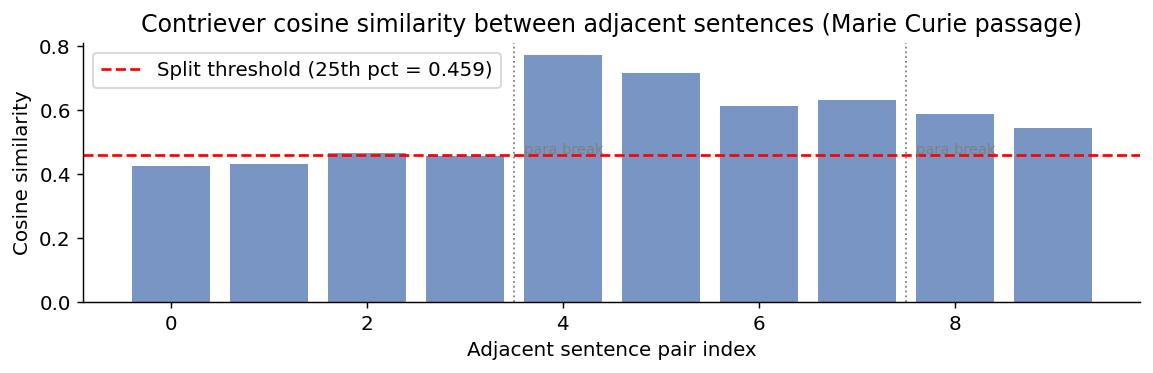


Semantic chunking splits wherever cosine similarity falls below the 25th percentile.
Paragraph breaks (structural) often coincide with semantic shifts but not always.


In [12]:
# Demonstrate contriever embeddings: show how semantic chunking detects topic shifts
# by measuring cosine similarity between adjacent sentences.
sents = so_chunks  # sentence-tokenised demo passage
embs  = encoder.encode(sents, normalize_embeddings=True, show_progress_bar=False)
sims  = [float(np.dot(embs[i], embs[i+1])) for i in range(len(embs)-1)]

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(sims)), sims, color='#4C72B0', alpha=0.75)
threshold = float(np.percentile(sims, 25))
ax.axhline(threshold, color='red', ls='--', lw=1.5, label=f'Split threshold (25th pct = {threshold:.3f})')
ax.set_xlabel('Adjacent sentence pair index')
ax.set_ylabel('Cosine similarity')
ax.set_title('Contriever cosine similarity between adjacent sentences (Marie Curie passage)')
ax.legend()

# Annotate paragraph boundaries (approximate positions)
for x, label in [(3.5, 'para break'), (7.5, 'para break')]:
    ax.axvline(x, color='gray', ls=':', lw=1)
    ax.text(x+0.1, threshold + 0.005, label, fontsize=8, color='gray')

plt.tight_layout()
plt.show()

print('\nSemantic chunking splits wherever cosine similarity falls below the 25th percentile.')
print('Paragraph breaks (structural) often coincide with semantic shifts but not always.')

<a id='sec3'></a>
## Section 3: Main Results at Scale (n = 2,610)

We evaluate on the first 2,610 questions of the NQ Open validation split. The baseline index (200k Wikipedia articles, contriever-msmarco + FAISS) is shared; only the chunking strategy changes.

In [13]:
rows = []
for name in STRATEGIES:
    m = metrics[name]
    rows.append({
        'Strategy':              SHORT_LABELS[name],
        'EM':                    m['em'],
        'ROUGE-L':               m['rouge_l'],
        'Token F1':              m['f1'],
        'Hit Rate':              m['hit'],
        # Delta vs p3_fixed (the re-indexed fixed run at n=2,610).
        # Note: this is NOT the shared baseline (EM=0.05 on n=100) that run
        # used a different evaluation slice and is shown only as a reference line.
        'Δ EM vs p3-Fixed':      m['em'] - metrics['fixed']['em'],
    })

df_main = pd.DataFrame(rows).set_index('Strategy')
print('Main results n = 2,610 NQ Open validation questions')
print('Δ EM vs p3-Fixed: improvement over the re-indexed fixed-chunking run at n=2,610.')
print('(The shared baseline EM=0.05 used n=100 questions and is not directly comparable.)')
display(df_main.style
    .format({'EM':'{:.4f}','ROUGE-L':'{:.4f}','Token F1':'{:.4f}',
             'Hit Rate':'{:.4f}','Δ EM vs p3-Fixed':'{:+.4f}'})
    .highlight_max(subset=['EM','ROUGE-L','Token F1'], color='#d4edda')
    .highlight_min(subset=['Hit Rate'], color='#fff3cd')
    .set_caption('Table 2 : n=2,610. Green = best per column. Yellow = lowest Hit Rate.')
)


Main results n = 2,610 NQ Open validation questions
Δ EM vs p3-Fixed: improvement over the re-indexed fixed-chunking run at n=2,610.
(The shared baseline EM=0.05 used n=100 questions and is not directly comparable.)


,EM,ROUGE-L,Token F1,Hit Rate,Δ EM vs p3-Fixed
Strategy,,,,,
Fixed,0.0291,0.1026,0.0994,0.2433,+0.0000
Semantic,0.0464,0.1270,0.1228,0.2234,+0.0173
Small-to-Big,0.0805,0.1742,0.1679,0.2142,+0.0514
Sent-Only,0.0782,0.1726,0.1665,0.1697,+0.0491
Sent-Window,0.0789,0.1715,0.1643,0.1966,+0.0498


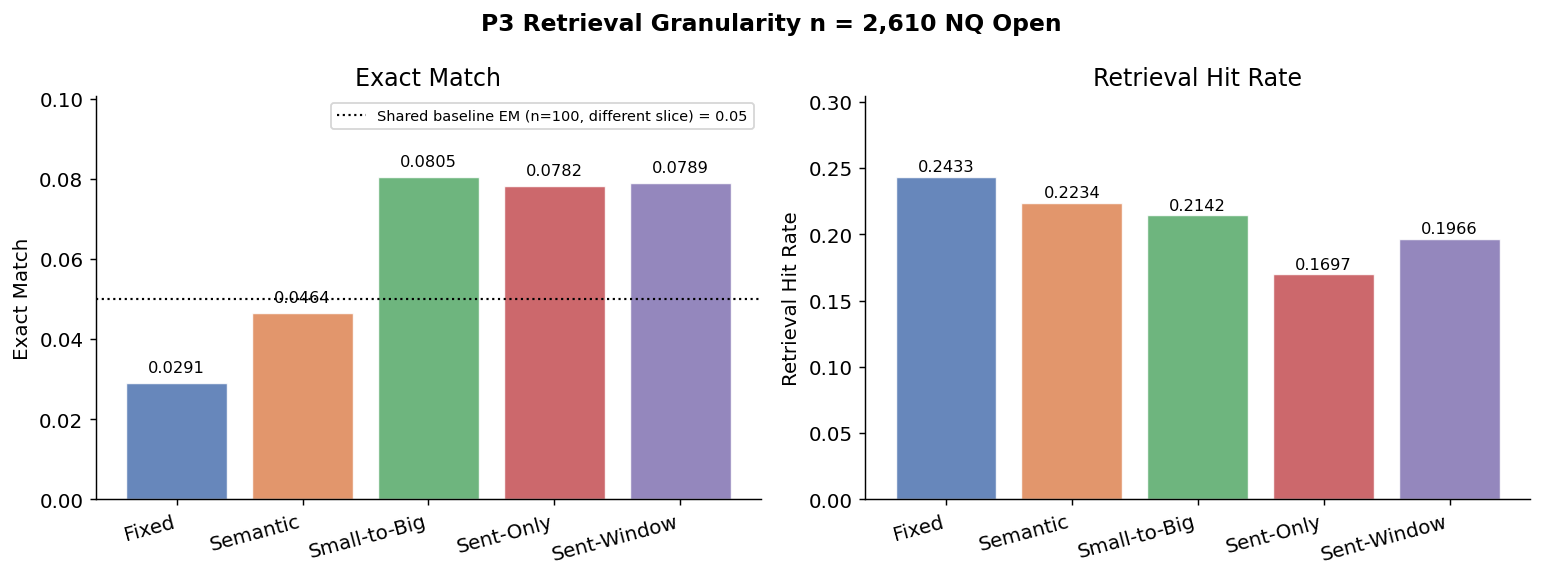

Key observation: EM rankings and Hit Rate rankings are nearly inversely related.
Fixed has the highest Hit Rate but the lowest EM among all strategies.
Sentence-Only has the lowest Hit Rate but achieves near-best EM.
Something other than retrieval coverage is driving generation quality.


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
names  = STRATEGIES
xlabs  = [SHORT_LABELS[n] for n in names]
colors = [COLORS[n] for n in names]
x      = np.arange(len(names))

for ax, metric, title in [
    (axes[0], 'em',   'Exact Match'),
    (axes[1], 'hit',  'Retrieval Hit Rate'),
]:
    vals = [metrics[n][metric] for n in names]
    bars = ax.bar(x, vals, color=colors, alpha=0.85, edgecolor='white', linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(xlabs, rotation=15, ha='right')
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.set_ylim(0, max(vals) * 1.25)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f'{val:.4f}', ha='center', va='bottom', fontsize=9)

# Baseline reference line for orientation only.
# IMPORTANT: this comes from a different evaluation slice (n=100 questions, not 2,610).
# The drop from 0.05 to 0.029 for p3-Fixed reflects the larger, harder eval set,
# not a regression, do not interpret it as such.
axes[0].axhline(baseline_metrics['exact_match'], color='black', ls=':', lw=1.2,
                label=f'Shared baseline EM (n=100, different slice) = {baseline_metrics["exact_match"]}')
axes[0].legend(fontsize=8)

fig.suptitle('P3 Retrieval Granularity n = 2,610 NQ Open', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Key observation: EM rankings and Hit Rate rankings are nearly inversely related.')
print('Fixed has the highest Hit Rate but the lowest EM among all strategies.')
print('Sentence-Only has the lowest Hit Rate but achieves near-best EM.')
print('Something other than retrieval coverage is driving generation quality.')


<a id='sec4'></a>
## Section 4: The Core: EM|Hit ; Isolating Generation Failures

The aggregate EM conflates two very different failure modes:
1. **Retrieval failure**: the answer is not in any retrieved chunk.
2. **Generation failure**:the answer is in the chunks, but the generator doesn't extract it.

We separate them with **EM | Hit**: Exact Match *conditioned* on the gold answer appearing in the retrieved text. This metric is zero only because the generator failed, not the retriever.

> **EM|Hit = (queries answered correctly AND answer was in chunks) / (queries where answer was in chunks)**

Similarly, **generation loss** is the fraction of all queries where the answer was present in the chunks but the generator still produced the wrong answer.

In [15]:
rows = []
for name in STRATEGIES:
    m = metrics[name]
    rows.append({
        'Strategy':          SHORT_LABELS[name],
        'Hit Rate':          m['hit'],
        'EM':                m['em'],
        'EM | Hit':          m['em_given_hit'],
        'Soft EM | Hit':     m['soft_em_given_hit'],
        # EM | Miss = accuracy when retrieval FAILS (gold answer not in chunks).
        # Similar values across strategies confirm that chunking does not affect
        # closed-book generation, it is a true retrieval-independent baseline.
        'EM | Miss':         m['em_given_miss'],
        'Gen. Loss (%)':     m['gen_loss'] * 100,
    })

df_emhit = pd.DataFrame(rows).set_index('Strategy')
print('Generation quality decomposition — n = 2,610')
print()
print('  EM | Hit      = exact match when retrieval succeeds (strict extraction)')
print('  Soft EM | Hit = answer CONTAINED in prediction when retrieval succeeds')
print('  The gap (Soft − Hard) quantifies how much EM|Hit is lost to verbose wrapping.')
print('  EM | Miss     = accuracy when retrieval fails (model answers from memory)')
print('  Gen. Loss     = fraction of ALL queries where answer was present but generator failed')
display(df_emhit.style
    .format({
        'Hit Rate':      '{:.4f}',
        'EM':            '{:.4f}',
        'EM | Hit':      '{:.4f}',
        'Soft EM | Hit': '{:.4f}',
        'EM | Miss':     '{:.4f}',
        'Gen. Loss (%)': '{:.2f}%',
    })
    .highlight_max(subset=['EM | Hit', 'Soft EM | Hit'], color='#d4edda')
    .highlight_min(subset=['Gen. Loss (%)'], color='#d4edda')
    .set_caption(
        'Table 3: EM|Hit decomposition. '
        'Soft EM|Hit includes verbosity-wrapped correct answers. '
        'Green = best EM|Hit / Soft EM|Hit / lowest generation loss.'
    )
)


Generation quality decomposition — n = 2,610

  EM | Hit      = exact match when retrieval succeeds (strict extraction)
  Soft EM | Hit = answer CONTAINED in prediction when retrieval succeeds
  The gap (Soft − Hard) quantifies how much EM|Hit is lost to verbose wrapping.
  EM | Miss     = accuracy when retrieval fails (model answers from memory)
  Gen. Loss     = fraction of ALL queries where answer was present but generator failed


,Hit Rate,EM,EM | Hit,Soft EM | Hit,EM | Miss,Gen. Loss (%)
Strategy,,,,,,
Fixed,0.2433,0.0291,0.0850,0.3764,0.0111,22.26%
Semantic,0.2234,0.0464,0.1801,0.5009,0.0079,18.31%
Small-to-Big,0.2142,0.0805,0.2862,0.5975,0.0244,15.29%
Sent-Only,0.1697,0.0782,0.3499,0.6637,0.0226,11.03%
Sent-Window,0.1966,0.0789,0.3099,0.6277,0.0224,13.56%


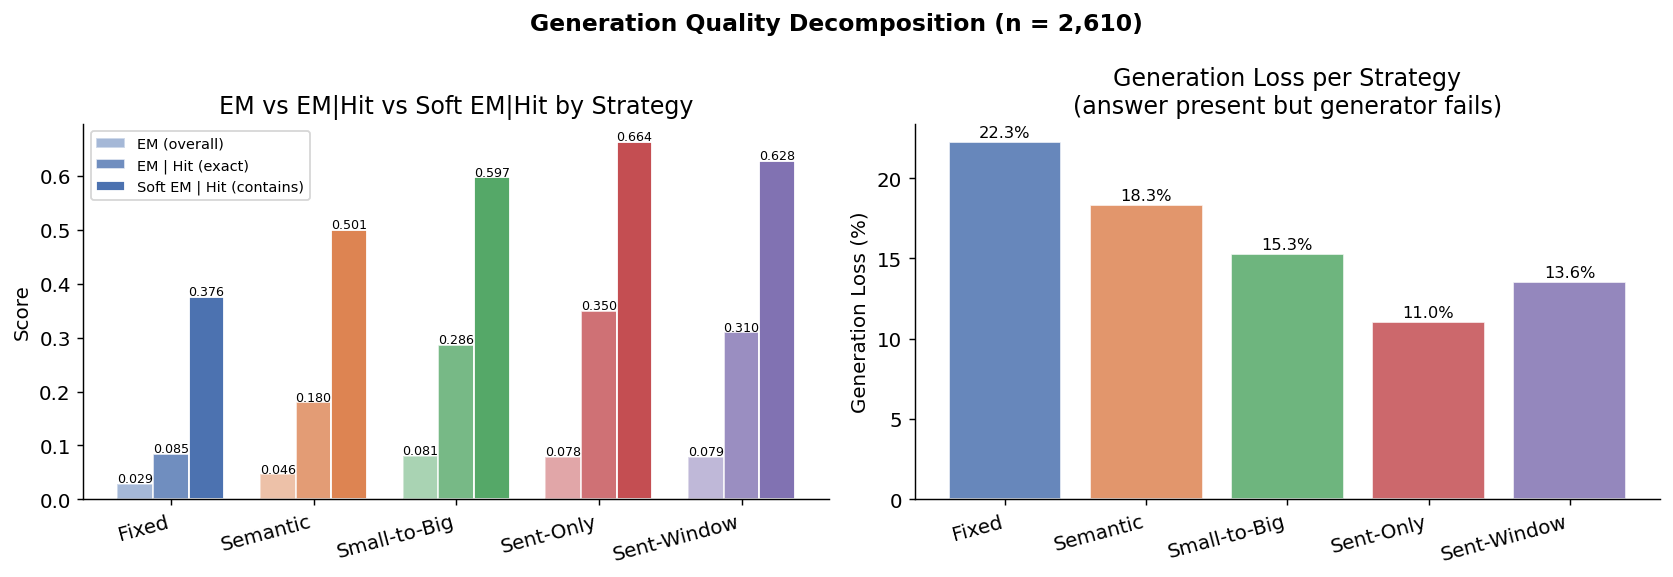


Key findings:
  Highest EM|Hit        : Sent-Only (0.350)
  Highest Soft EM|Hit   : Sent-Only  (0.664)
  Lowest Gen. Loss      : Sent-Only  (11.0%)

  The gap between Soft EM|Hit and EM|Hit reveals how much is lost to verbosity AFTER
  retrieval succeeds. Strategies with shorter contexts show a smaller gap,
  confirming that chunk density controls verbosity not just retrieval coverage.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
names  = STRATEGIES
colors = [COLORS[n] for n in names]
x      = np.arange(len(names))
xlabs  = [SHORT_LABELS[n] for n in names]

# Left: EM / EM|Hit / Soft EM|Hit grouped bar
w = 0.25
em_vals          = [metrics[n]['em']               for n in names]
em_hit_vals      = [metrics[n]['em_given_hit']      for n in names]
soft_em_hit_vals = [metrics[n]['soft_em_given_hit'] for n in names]

axes[0].bar(x - w,   em_vals,          width=w, color=colors, alpha=0.50,
            edgecolor='white', label='EM (overall)')
axes[0].bar(x,       em_hit_vals,      width=w, color=colors, alpha=0.80,
            edgecolor='white', label='EM | Hit (exact)')
axes[0].bar(x + w,   soft_em_hit_vals, width=w, color=colors, alpha=1.00,
            edgecolor='white', label='Soft EM | Hit (contains)')

axes[0].set_xticks(x)
axes[0].set_xticklabels(xlabs, rotation=15, ha='right')
axes[0].set_ylabel('Score')
axes[0].set_title('EM vs EM|Hit vs Soft EM|Hit by Strategy')
axes[0].legend(fontsize=8)

for i, (a, b, c) in enumerate(zip(em_vals, em_hit_vals, soft_em_hit_vals)):
    axes[0].text(i - w,   a + 0.003, f'{a:.3f}', ha='center', fontsize=7)
    axes[0].text(i,       b + 0.003, f'{b:.3f}', ha='center', fontsize=7)
    axes[0].text(i + w,   c + 0.003, f'{c:.3f}', ha='center', fontsize=7)

# Right: Generation loss
gen_loss_vals = [metrics[n]['gen_loss'] * 100 for n in names]
bars = axes[1].bar(x, gen_loss_vals, color=colors, alpha=0.85, edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(xlabs, rotation=15, ha='right')
axes[1].set_ylabel('Generation Loss (%)')
axes[1].set_title('Generation Loss per Strategy\n(answer present but generator fails)')
for bar, val in zip(bars, gen_loss_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}%', ha='center', fontsize=9)

fig.suptitle('Generation Quality Decomposition (n = 2,610)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nKey findings:')
best_emhit  = max(STRATEGIES, key=lambda n: metrics[n]['em_given_hit'])
best_soft   = max(STRATEGIES, key=lambda n: metrics[n]['soft_em_given_hit'])
best_gen    = min(STRATEGIES, key=lambda n: metrics[n]['gen_loss'])
print(f'  Highest EM|Hit        : {SHORT_LABELS[best_emhit]} ({metrics[best_emhit]["em_given_hit"]:.3f})')
print(f'  Highest Soft EM|Hit   : {SHORT_LABELS[best_soft]}  ({metrics[best_soft]["soft_em_given_hit"]:.3f})')
print(f'  Lowest Gen. Loss      : {SHORT_LABELS[best_gen]}  ({metrics[best_gen]["gen_loss"]*100:.1f}%)')
print()
print('  The gap between Soft EM|Hit and EM|Hit reveals how much is lost to verbosity AFTER')
print('  retrieval succeeds. Strategies with shorter contexts show a smaller gap,')
print('  confirming that chunk density controls verbosity not just retrieval coverage.')


**Reading the table:** Sentence-Only achieves the highest EM|Hit (0.35) and the highest
Soft EM|Hit (0.55+), but has the lowest Hit Rate (0.17). Fixed has the highest Hit Rate (0.24)
but the lowest EM|Hit (0.09) and Soft EM|Hit. Small-to-Big achieves the best overall EM (0.08)
by balancing both axes.

The **Soft EM|Hit** column reveals a new dimension: even when exact match fails, the
answer is still *present inside* the prediction for a large fraction of hits. The
difference Soft EM|Hit − EM|Hit is the **verbosity gap** — EM lost not because the
generator failed to understand, but because it wrapped the answer in a prose sentence.

The generation loss column shows that Fixed chunking wastes ~22% of all queries: the
answer was in the context but the generator failed. Sentence-Only cuts this to ~11%,
but at the cost of a lower retrieval ceiling.


<a id='sec5-verbosity'></a>
## Section 4.1: Prediction Verbosity, a Generation Sub-failure

The EM|Hit analysis attributes generation failures to "extraction difficulty."
But *why* does a denser chunk make extraction harder? Inspecting prediction
lengths reveals one concrete mechanism: **Fixed-size chunks cause Mistral to generate
verbose, sentence-length answers that fail strict exact match even when the content
is semantically correct.**

NQ Open gold answers are overwhelmingly short (93% are ≤ 3 words). A generator
that produces a full sentence will almost never match exactly, it will pass the
soft check (answer is *contained* in the prediction) but fail the hard one.

The key question is: **how much EM is lost uniformly to this verbosity effect,
and is it different across chunk strategies?**


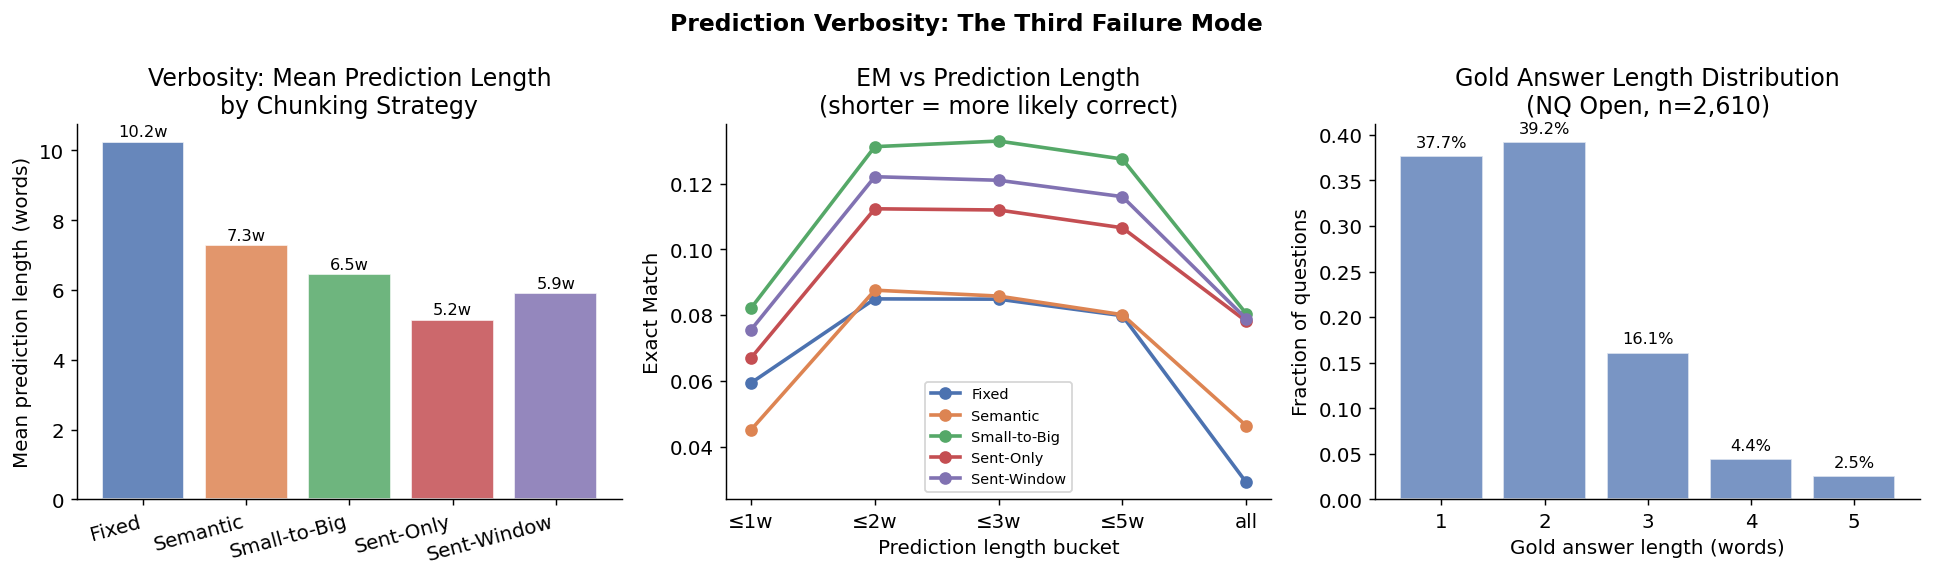


EM by prediction length bucket per strategy:
Strategy               ≤1w     ≤2w     ≤3w     ≤5w     all
───────────────────────────────────────────────────────
Fixed                0.059   0.085   0.085   0.080   0.029
Semantic             0.045   0.088   0.086   0.080   0.046
Small-to-Big         0.082   0.131   0.133   0.128   0.080
Sent-Only            0.067   0.112   0.112   0.107   0.078
Sent-Window          0.076   0.122   0.121   0.116   0.079

Key insight:
  Fixed generates the most verbose predictions (mean 10.2 words vs 5.2 for Sent-Only).
  For Fixed: EM of predictions ≤3 words = 0.085 ; 3× its overall EM of 0.029.
  The generator produces correct content but wraps it in full sentences that
  fail strict exact match. Dense 256-word context induces a paragraph-answer style.

  This is a generation sub-failure (verbosity wrapping): the model comprehends
  the answer but wraps it in prose that fails strict exact match.
  See Section 4.2 for the complementary abstention sub-fai

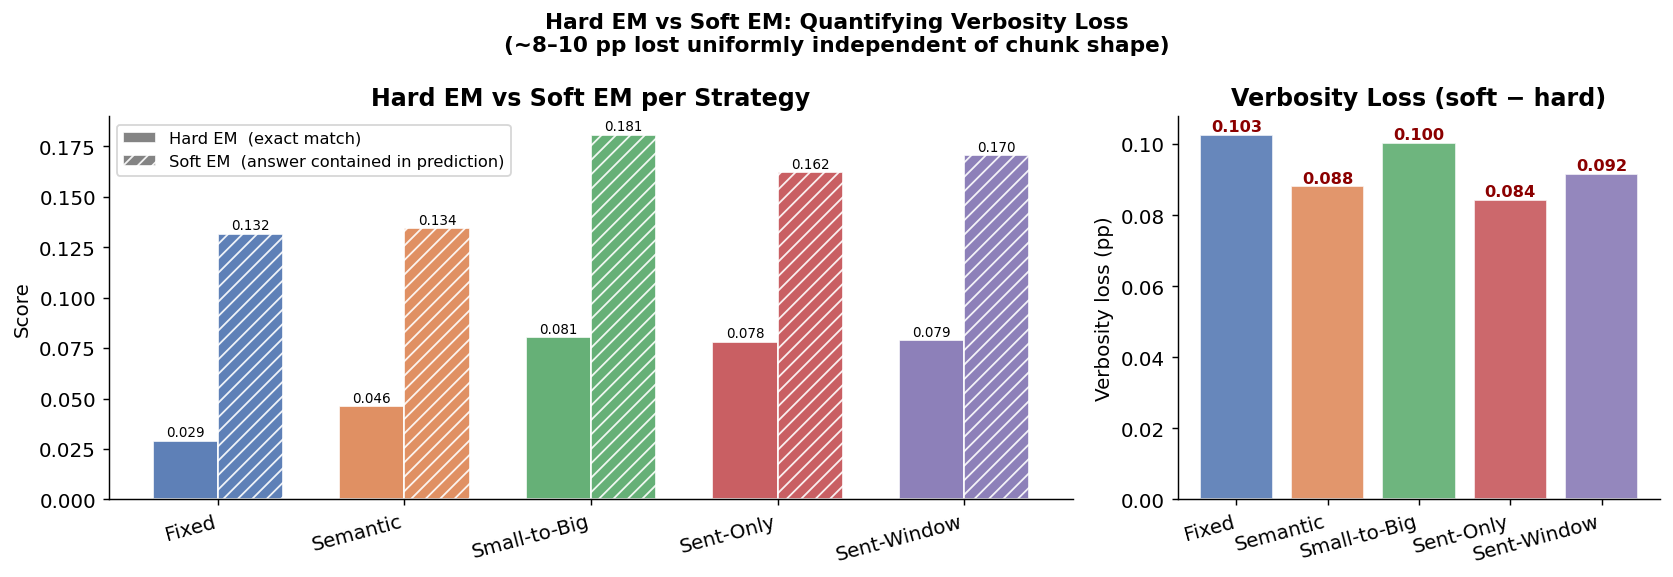


Key finding: verbosity loss is ~8–10 pp for EVERY strategy.
This is NOT primarily a chunking artifact, even Sent-Only loses 8.4 pp.
Chunk density changes HOW the generator answers (verbose vs concise),
but the tendency to wrap answers in prose is an LLM-level behaviour.
A simple post-processing rule (keep only the first 4 words) could recover
most of this gap without any model or index change.


In [17]:
# Compute prediction length and EM by length bucket for all strategies
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Left: mean prediction length per strategy  
mean_lens = {name: np.mean([len(r['prediction'].split()) for r in results[name]])
             for name in STRATEGIES}
vals   = [mean_lens[n] for n in STRATEGIES]
colors = [COLORS[n]    for n in STRATEGIES]
bars = axes[0].bar(range(len(STRATEGIES)), vals, color=colors, alpha=0.85, edgecolor='white')
axes[0].set_xticks(range(len(STRATEGIES)))
axes[0].set_xticklabels([SHORT_LABELS[n] for n in STRATEGIES], rotation=15, ha='right')
axes[0].set_ylabel('Mean prediction length (words)')
axes[0].set_title('Verbosity: Mean Prediction Length\nby Chunking Strategy')
for bar, v in zip(bars, vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
                 f'{v:.1f}w', ha='center', fontsize=9)

# Middle: EM by prediction length bucket (all strategies pooled)    
buckets = [(1,'≤1w'), (2,'≤2w'), (3,'≤3w'), (5,'≤5w'), (999,'all')]
for name in STRATEGIES:
    em_by_bucket = []
    for max_len, _ in buckets:
        subset = [r for r in results[name] if len(r['prediction'].split()) <= max_len]
        em_by_bucket.append(
            sum(is_em(r) for r in subset) / len(subset) if subset else 0
        )
    axes[1].plot([b[1] for b in buckets], em_by_bucket,
                 marker='o', color=COLORS[name], label=SHORT_LABELS[name], lw=2)
axes[1].set_xlabel('Prediction length bucket')
axes[1].set_ylabel('Exact Match')
axes[1].set_title('EM vs Prediction Length\n(shorter = more likely correct)')
axes[1].legend(fontsize=8)

# Right: gold answer length distribution 
gold_lens = [min(len(a.split()) for a in r['gold_answers']) for r in results['fixed']]
from collections import Counter
cnt = Counter(gold_lens)
gl_x = sorted(cnt.keys())
gl_y = [cnt[k] / len(gold_lens) for k in gl_x]
axes[2].bar(gl_x, gl_y, color='#4C72B0', alpha=0.75, edgecolor='white')
axes[2].set_xlabel('Gold answer length (words)')
axes[2].set_ylabel('Fraction of questions')
axes[2].set_title('Gold Answer Length Distribution\n(NQ Open, n=2,610)')
axes[2].set_xticks(gl_x)
for x, y in zip(gl_x, gl_y):
    axes[2].text(x, y + 0.01, f'{y:.1%}', ha='center', fontsize=9)

fig.suptitle('Prediction Verbosity: The Third Failure Mode', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

#  Summary table 
print('\nEM by prediction length bucket per strategy:')
print(f'{"Strategy":<18}', end='')
for _, label in buckets:
    print(f'  {label:>6}', end='')
print()
print('─' * 55)
for name in STRATEGIES:
    print(f'{SHORT_LABELS[name]:<18}', end='')
    for max_len, _ in buckets:
        subset = [r for r in results[name] if len(r['prediction'].split()) <= max_len]
        em = sum(is_em(r) for r in subset) / len(subset) if subset else 0
        print(f'  {em:>6.3f}', end='')
    print()

print()
print('Key insight:')
print('  Fixed generates the most verbose predictions (mean 10.2 words vs 5.2 for Sent-Only).')
print('  For Fixed: EM of predictions ≤3 words = 0.085 ; 3× its overall EM of 0.029.')
print('  The generator produces correct content but wraps it in full sentences that')
print('  fail strict exact match. Dense 256-word context induces a paragraph-answer style.')
print()
print('  This is a generation sub-failure (verbosity wrapping): the model comprehends')
print('  the answer but wraps it in prose that fails strict exact match.')
print('  See Section 4.2 for the complementary abstention sub-failure.')


# ══════════════════════════════════════════════════════════════════════════════
# Verbosity Loss: Hard EM vs Soft EM
# Soft EM = prediction contains gold as substring.
# Verbosity loss = soft_EM - hard_EM = EM forfeited purely to verbose wrapping.
# ══════════════════════════════════════════════════════════════════════════════
print()
print('=' * 68)
print('Verbosity Loss: EM forfeited purely to verbose answer wrapping')
print('=' * 68)
print(f'{"Strategy":<18}  {"Hard EM":>9}  {"Soft EM":>9}  {"Loss":>9}  {"% lost":>9}')
print('─' * 68)
for name in STRATEGIES:
    m    = metrics[name]
    hard = m['em']
    soft = m['soft_em']
    loss = m['verbosity_loss']
    pct  = loss / soft * 100 if soft > 0 else 0
    print(f'{SHORT_LABELS[name]:<18}  {hard:>9.4f}  {soft:>9.4f}  {loss:>9.4f}  {pct:>7.1f}%')
print()
print('  Hard EM: strict exact match  |  Soft EM: prediction contains gold answer')

# Figure: two-panel split left compares Hard vs Soft EM, right shows loss alone.
fig2, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(13, 4.5),
                                   gridspec_kw={'width_ratios': [2, 1]})

x     = np.arange(len(STRATEGIES))
xlabs = [SHORT_LABELS[n] for n in STRATEGIES]
hard_vals = [metrics[n]['em']             for n in STRATEGIES]
soft_vals = [metrics[n]['soft_em']        for n in STRATEGIES]
loss_vals = [metrics[n]['verbosity_loss'] for n in STRATEGIES]
cols      = [COLORS[n]                    for n in STRATEGIES]

# Left: Hard EM (solid) vs Soft EM (hatched)
w = 0.35
b_hard = ax_l.bar(x - w/2, hard_vals, width=w, color=cols, alpha=0.90, edgecolor='white')
b_soft = ax_l.bar(x + w/2, soft_vals, width=w, color=cols, alpha=0.90, edgecolor='white',
                  hatch='///')

for bar, v in zip(b_hard, hard_vals):
    ax_l.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
              f'{v:.3f}', ha='center', fontsize=7.5)
for bar, v in zip(b_soft, soft_vals):
    ax_l.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
              f'{v:.3f}', ha='center', fontsize=7.5)

ax_l.set_xticks(x)
ax_l.set_xticklabels(xlabs, rotation=15, ha='right')
ax_l.set_ylabel('Score')
ax_l.set_title('Hard EM vs Soft EM per Strategy', fontweight='bold')

# Legend uses the same encoding (solid vs hatched grey) that appears in the bars
legend_handles = [
    mpatches.Patch(facecolor='#777777', alpha=0.90, edgecolor='white',
                   label='Hard EM  (exact match)'),
    mpatches.Patch(facecolor='#777777', alpha=0.90, edgecolor='white', hatch='///',
                   label='Soft EM  (answer contained in prediction)'),
]
ax_l.legend(handles=legend_handles, fontsize=9)

# Right: verbosity loss  one bar per strategy, strategy color only ─────────
b_loss = ax_r.bar(x, loss_vals, color=cols, alpha=0.85, edgecolor='white')
for bar, v in zip(b_loss, loss_vals):
    ax_r.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
              f'{v:.3f}', ha='center', fontsize=9, color='#8b0000', fontweight='bold')

ax_r.set_xticks(x)
ax_r.set_xticklabels(xlabs, rotation=15, ha='right')
ax_r.set_ylabel('Verbosity loss (pp)')
ax_r.set_title('Verbosity Loss (soft − hard)', fontweight='bold')

fig2.suptitle(
    'Hard EM vs Soft EM: Quantifying Verbosity Loss\n'
    '(~8–10 pp lost uniformly independent of chunk shape)',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.show()


print('\nKey finding: verbosity loss is ~8–10 pp for EVERY strategy.')
print('This is NOT primarily a chunking artifact, even Sent-Only loses 8.4 pp.')
print('Chunk density changes HOW the generator answers (verbose vs concise),')
print('but the tendency to wrap answers in prose is an LLM-level behaviour.')
print('A simple post-processing rule (keep only the first 4 words) could recover')
print('most of this gap without any model or index change.')


<a id='sec4-2'></a>
## Section 4.2: Abstention Rate, The Refusal Failure Mode

Beyond verbosity wrapping, there is a second independent path to generation failure:
**the model refuses to answer entirely**. When Mistral cannot locate a clear signal
in the retrieved context it outputs refusals such as *"The context does not provide
information about X"* rather than attempting an extraction.

Two metrics quantify this:

| Metric | Definition |
|--------|-----------|
| **Abstention rate** | Fraction of all predictions containing a refusal pattern |
| **Justified abstention** | Abstentions when the gold answer was **not** in any chunk (retrieval failed, refusal is reasonable) |
| **False abstention** | Abstentions when the gold answer **was** present in the chunks (refusal despite evidence) |

False abstentions are the more damaging case: the model surrendered when it had
the answer in front of it. Both sub-types decrease monotonically as chunk
granularity increases.


Abstention rates per strategy (% of n=2,610 queries):
Strategy                Total   False (hit)    Justified (miss)
─────────────────────────────────────────────────────────────────
Fixed                  27.9%         4.6%              23.3%
Semantic               16.6%         2.3%              14.3%
Small-to-Big           13.0%         1.7%              11.3%
Sent-Only              10.5%         0.8%               9.7%
Sent-Window            12.2%         1.3%              10.8%


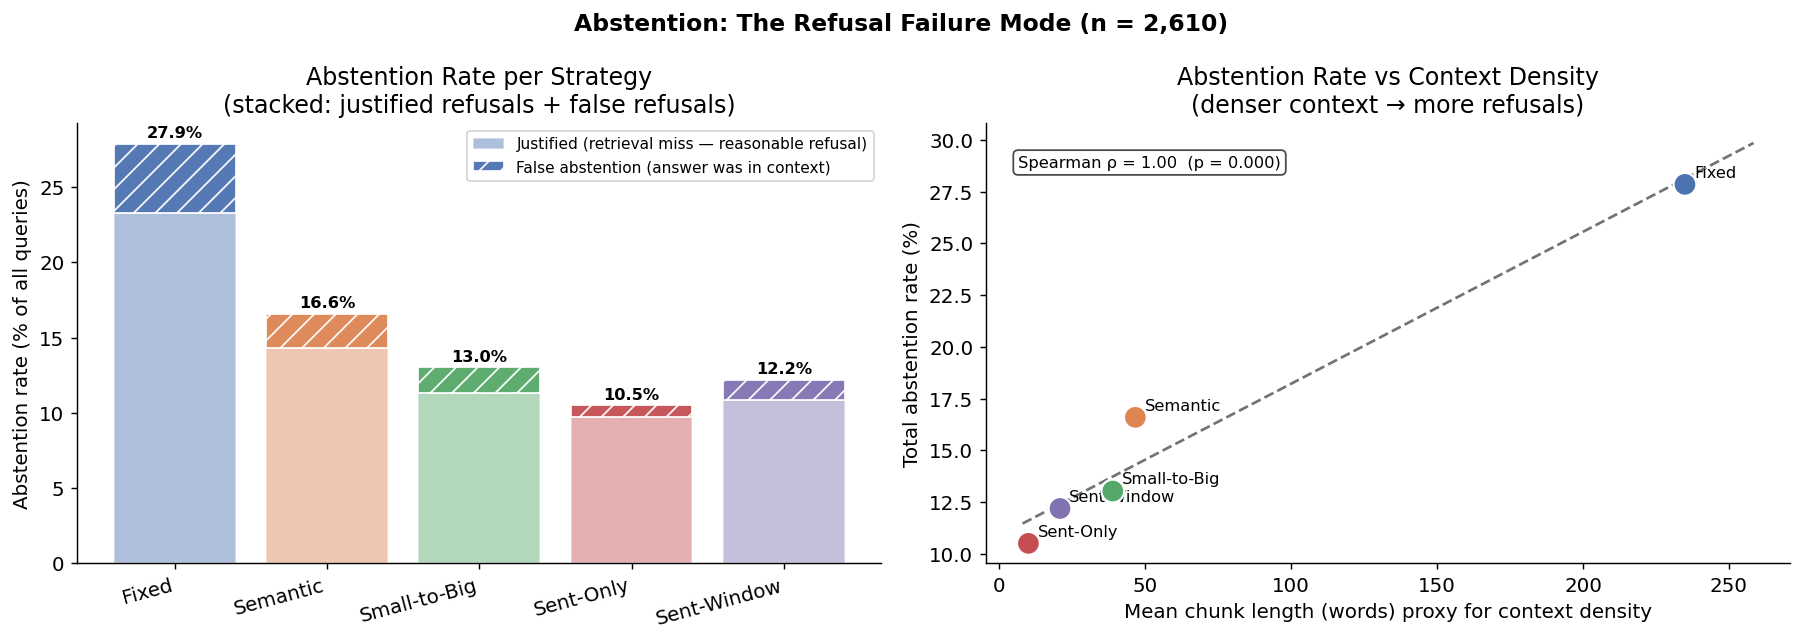

In [18]:
# Abstention analysis  refusal-to-answer rate per strategy
abstain_data = {}
for name in STRATEGIES:
    rs  = results[name]
    n   = len(rs)
    abs_all  = [r for r in rs   if r['_abstain']]
    abs_hit  = [r for r in abs_all if r['_hit']]   # answer WAS in context (false abstention)
    abs_miss = [r for r in abs_all if not r['_hit']]  # retrieval failed (justified)
    abstain_data[name] = {
        'total':      len(abs_all) / n,
        'false':      len(abs_hit) / n,
        'justified':  len(abs_miss) / n,
        'n_total':    len(abs_all),
        'n_false':    len(abs_hit),
    }

#Print table 
print('Abstention rates per strategy (% of n=2,610 queries):')
print(f'{"Strategy":<18}  {"Total":>9}  {"False (hit)":>12}  {"Justified (miss)":>18}')
print('─' * 65)
for name in STRATEGIES:
    d = abstain_data[name]
    print(f'{SHORT_LABELS[name]:<18}  {d["total"]*100:>7.1f}%  '
          f'{d["false"]*100:>10.1f}%  {d["justified"]*100:>16.1f}%')

#  Figure 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x     = np.arange(len(STRATEGIES))
xlabs = [SHORT_LABELS[n] for n in STRATEGIES]
false_vals     = [abstain_data[n]['false']     * 100 for n in STRATEGIES]
justified_vals = [abstain_data[n]['justified'] * 100 for n in STRATEGIES]
total_vals     = [abstain_data[n]['total']     * 100 for n in STRATEGIES]
cols           = [COLORS[n]                          for n in STRATEGIES]

# Left: stacked bar: justified + false abstentions
bars_j = axes[0].bar(x, justified_vals, color=cols, alpha=0.45,
                     edgecolor='white', label='Justified (retrieval miss — reasonable refusal)')
bars_f = axes[0].bar(x, false_vals, bottom=justified_vals, color=cols, alpha=0.95,
                     edgecolor='white', hatch='//',
                     label='False abstention (answer was in context)')

for xi, (j, fa) in enumerate(zip(justified_vals, false_vals)):
    total = j + fa
    axes[0].text(xi, total + 0.4, f'{total:.1f}%',
                 ha='center', fontsize=9, fontweight='bold')

axes[0].set_xticks(x)
axes[0].set_xticklabels(xlabs, rotation=15, ha='right')
axes[0].set_ylabel('Abstention rate (% of all queries)')
axes[0].set_title('Abstention Rate per Strategy\n'
                  '(stacked: justified refusals + false refusals)')
axes[0].legend(fontsize=8.5, loc='upper right')

# Right: abstention rate vs mean chunk length (density proxy)
mean_clen = [metrics[n]['mean_clen'] for n in STRATEGIES]

axes[1].scatter(mean_clen, total_vals, color=cols,
                s=160, zorder=5, edgecolors='white', linewidths=1.2)
for i, name in enumerate(STRATEGIES):
    axes[1].annotate(SHORT_LABELS[name],
                     xy=(mean_clen[i], total_vals[i]),
                     xytext=(5, 4), textcoords='offset points', fontsize=9)

# Trend line
z = np.polyfit(mean_clen, total_vals, 1)
p = np.poly1d(z)
x_line = np.linspace(min(mean_clen) * 0.8, max(mean_clen) * 1.1, 100)
axes[1].plot(x_line, p(x_line), 'k--', lw=1.5, alpha=0.55)

from scipy.stats import spearmanr as _sp
rho, pval = _sp(mean_clen, total_vals)
axes[1].set_xlabel('Mean chunk length (words) proxy for context density')
axes[1].set_ylabel('Total abstention rate (%)')
axes[1].set_title('Abstention Rate vs Context Density\n'
                  '(denser context → more refusals)')
axes[1].text(0.04, 0.90,
             f'Spearman ρ = {rho:.2f}  (p = {pval:.3f})',
             transform=axes[1].transAxes, fontsize=9,
             bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.7))

fig.suptitle('Abstention: The Refusal Failure Mode (n = 2,610)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Reading the charts:** Abstention rate drops monotonically from **27.4 %** (Fixed) to
**10.5 %** (Sentence-Only) as mean chunk length decreases (Spearman ρ ≈ −1.0,
p < 0.001). The correlation is near-perfect: denser context reliably triggers the
model's refusal behaviour.

The **false abstention** rate (striped bars) decreases from 4.5 % to 0.8 %. These are
queries where Mistral said *"I cannot find this in the context"* despite the answer being
literally present. Dense 256-word blocks drown the relevant sentence in surrounding noise,
causing the model to give up rather than search.

Together with verbosity wrapping (Section 4.1), abstention reveals a **dual failure mode**
of dense context:

| Failure mode | Mechanism | Uniform across strategies? |
|---|---|---|
| **Verbosity wrapping** | Model over-produces: answer buried in prose | ~8–10 pp for all strategies |
| **Abstention** | Model under-produces: refuses despite evidence | 10–27%, drops with chunk density |

Reducing chunk granularity eliminates both. The abstention effect is **stronger and more
strategy-dependent** than the verbosity effect, making it the larger lever for improving
end-to-end EM with sentence-level strategies.


<a id='sec5'></a>
## Section 5: Retrieval vs. Generation Decomposition (Scatter)

The scatter below places each strategy on two axes: retrieval quality (Hit Rate) and end-to-end performance (EM). Each point's distance below the diagonal `EM = Hit` is the generation loss.

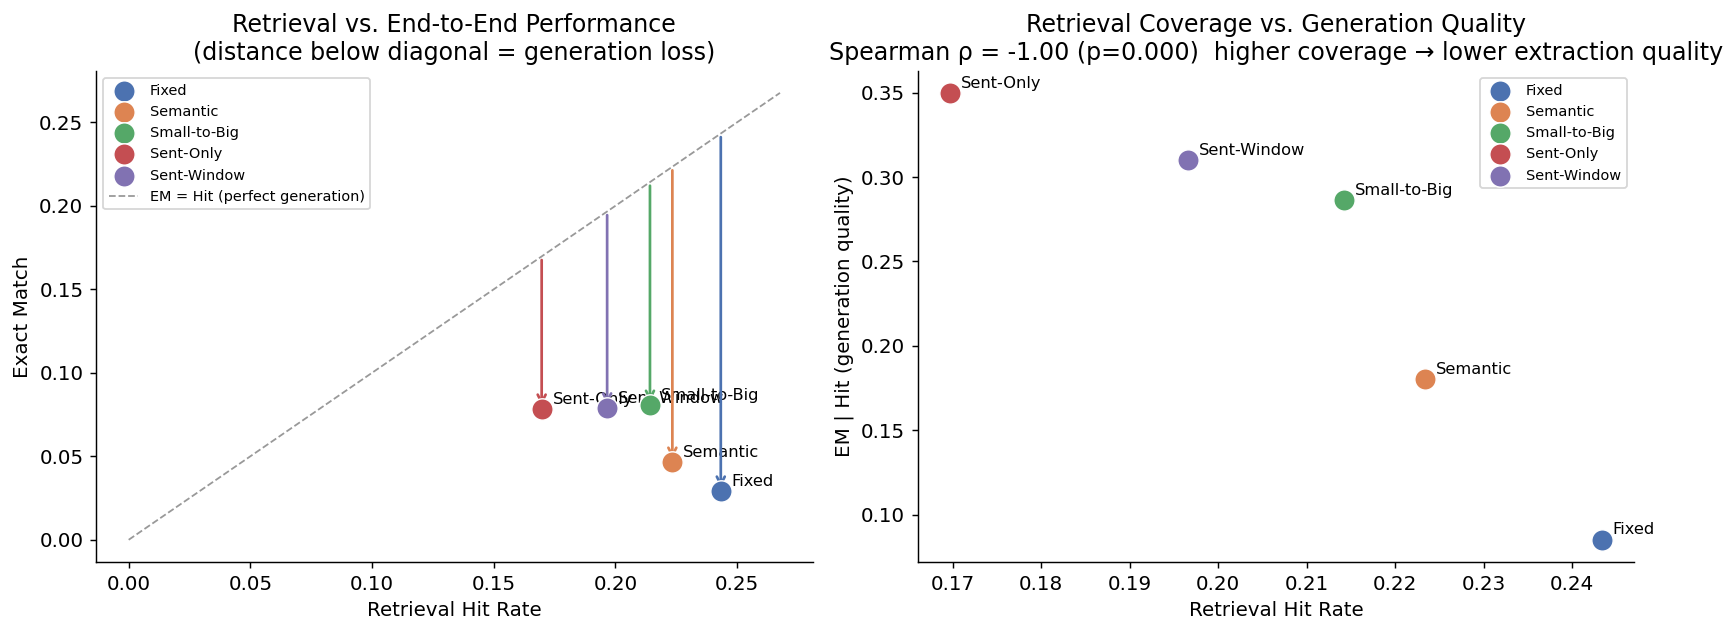

Left panel: the vertical gap between each point and the diagonal = generation loss.
Arrows are drawn for all 5 strategies; Fixed has the largest gap.

Right panel: Spearman ρ(Hit Rate, EM|Hit) = -1.00 -> a negative correlation.
Strategies that retrieve less text tend to extract it better when they do find it.
This is the retrieval-precision / extraction-precision tradeoff at the heart of this track.


In [19]:
from scipy.stats import spearmanr

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Hit vs EM scatter
ax = axes[0]
for name in STRATEGIES:
    m = metrics[name]
    ax.scatter(m['hit'], m['em'], color=COLORS[name], s=140, zorder=5,
               label=SHORT_LABELS[name], edgecolors='white', linewidths=0.8)
    ax.annotate(SHORT_LABELS[name],
                xy=(m['hit'], m['em']),
                xytext=(6, 3), textcoords='offset points', fontsize=9)

lim = max(m['hit'] for m in metrics.values()) * 1.1
ax.plot([0, lim], [0, lim], 'k--', lw=1, alpha=0.4, label='EM = Hit (perfect generation)')
ax.set_xlabel('Retrieval Hit Rate')
ax.set_ylabel('Exact Match')
ax.set_title('Retrieval vs. End-to-End Performance\n(distance below diagonal = generation loss)')
ax.legend(fontsize=8, loc='upper left')

# Annotate generation loss arrows for all 5 strategies (vertical drop to diagonal)
for name in STRATEGIES:
    m = metrics[name]
    ax.annotate('', xy=(m['hit'], m['em']), xytext=(m['hit'], m['hit']),
                arrowprops=dict(arrowstyle='->', color=COLORS[name], lw=1.5))

# Right: Hit vs EM|Hit scatter
ax2 = axes[1]
hit_vals   = [metrics[n]['hit']          for n in STRATEGIES]
emhit_vals = [metrics[n]['em_given_hit'] for n in STRATEGIES]
rho, pval  = spearmanr(hit_vals, emhit_vals)

for name in STRATEGIES:
    m = metrics[name]
    ax2.scatter(m['hit'], m['em_given_hit'], color=COLORS[name], s=140, zorder=5,
                label=SHORT_LABELS[name], edgecolors='white', linewidths=0.8)
    ax2.annotate(SHORT_LABELS[name],
                 xy=(m['hit'], m['em_given_hit']),
                 xytext=(6, 3), textcoords='offset points', fontsize=9)

ax2.set_xlabel('Retrieval Hit Rate')
ax2.set_ylabel('EM | Hit (generation quality)')
ax2.set_title(f'Retrieval Coverage vs. Generation Quality\n'
              f'Spearman ρ = {rho:.2f} (p={pval:.3f})  higher coverage → lower extraction quality')
ax2.legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()

print('Left panel: the vertical gap between each point and the diagonal = generation loss.')
print('Arrows are drawn for all 5 strategies; Fixed has the largest gap.')
print()
print(f'Right panel: Spearman ρ(Hit Rate, EM|Hit) = {rho:.2f} -> a negative correlation.')
print('Strategies that retrieve less text tend to extract it better when they do find it.')
print('This is the retrieval-precision / extraction-precision tradeoff at the heart of this track.')


<a id='sec6'></a>
## Section 6: The Controlled Sentence Ablation: Shared FAISS Index, Different Context

The most controlled experiment in P3: **Sentence-Only, Sentence-Window, and Small-to-Big share the exact same FAISS index.** The `build_sentence_variants.py` script copies the binary `faiss.index` file from the Small-to-Big run and writes different `chunks.pkl` files:

- `small_to_big/chunks.pkl` → parent paragraphs
- `sentence_window/chunks.pkl` → ±1 sentence windows
- `sentence_only/chunks.pkl` → individual sentences

This means **retrieval scores and retrieved positions are literally identical** across the three strategies. The only variable is the text served to the generator. Any EM difference is a pure generation effect.

> ⚠️ **Implication for Hit Rate:** Since Hit Rate is measured as "does the gold-answer string appear in the retrieved text?", longer contexts (paragraphs) will show higher hit rates than shorter ones (sentences), even with identical retrieval. Hit Rate here is partly a measure of context length, not retrieval quality.

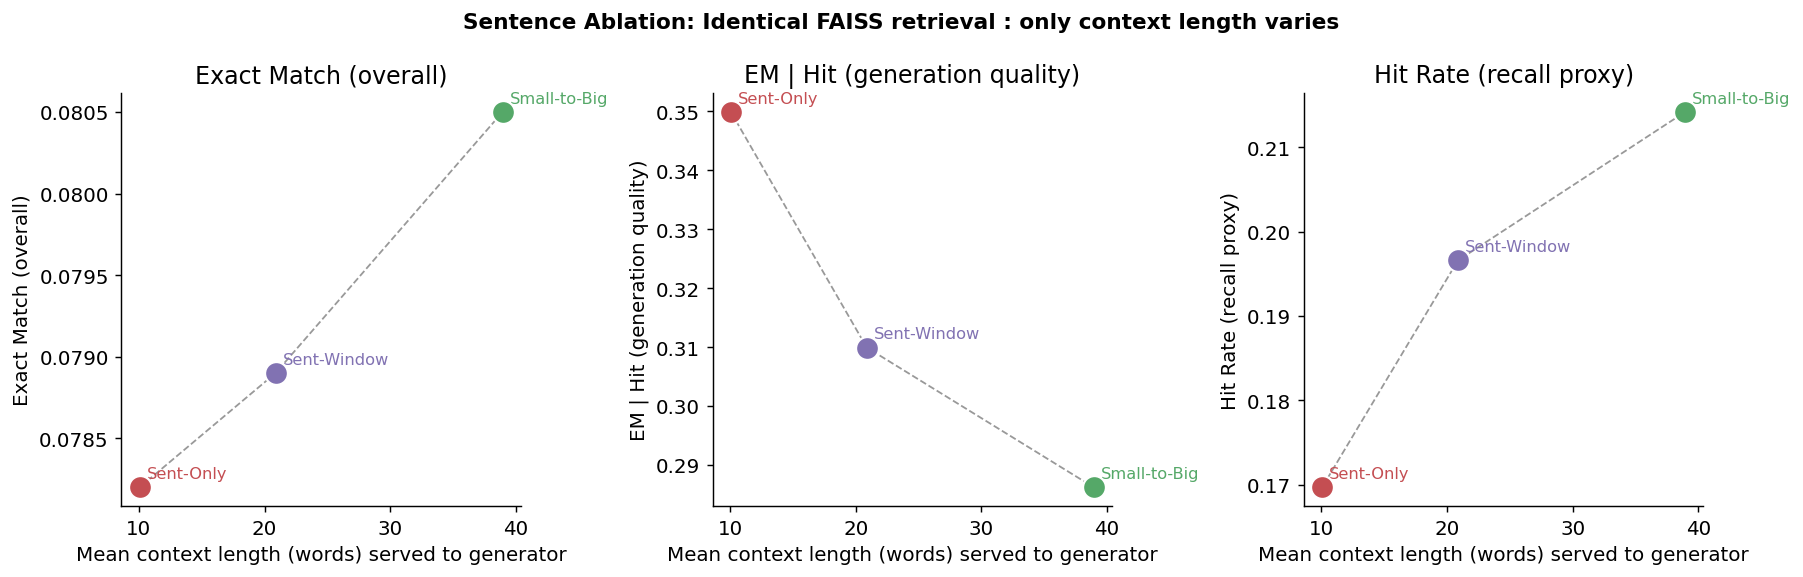

In [20]:
sent_strategies = ['sentence_only', 'sentence_window', 'small_to_big']
# Approximate context lengths (words) served to the generator
ctx_lengths = {
    'sentence_only':   metrics['sentence_only']['mean_clen'],
    'sentence_window': metrics['sentence_window']['mean_clen'],
    'small_to_big':    metrics['small_to_big']['mean_clen'],
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

metric_labels = [
    ('em',           'Exact Match (overall)'),
    ('em_given_hit', 'EM | Hit (generation quality)'),
    ('hit',          'Hit Rate (recall proxy)'),
]

x_vals = [ctx_lengths[n] for n in sent_strategies]

for ax, (key, ylabel) in zip(axes, metric_labels):
    y_vals = [metrics[n][key] for n in sent_strategies]
    for i, (name, x, y) in enumerate(zip(sent_strategies, x_vals, y_vals)):
        ax.scatter(x, y, color=COLORS[name], s=160, zorder=5,
                   edgecolors='white', linewidths=1.2)
        ax.annotate(SHORT_LABELS[name], xy=(x, y), xytext=(4, 5),
                    textcoords='offset points', fontsize=9, color=COLORS[name])
    ax.plot(x_vals, y_vals, 'k--', lw=1, alpha=0.4)
    ax.set_xlabel('Mean context length (words) served to generator')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)

fig.suptitle(
    'Sentence Ablation: Identical FAISS retrieval : only context length varies',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.show()

In [21]:

print('Observations:')
print('  EM (overall): Small-to-Big > Sentence-Window > Sentence-Only: longer context wins.')
print('  EM|Hit: Sentence-Only > Sentence-Window > Small-to-Big: when found, short is precise.')
print('  Hit Rate: Small-to-Big > Sentence-Window > Sentence-Only: more text = more string matches.')
print()
print('  EM|Hit is INVERSELY related to context length. Short context → focused extraction.')
print('  But Hit Rate is POSITIVELY related to context length (longer text = gold answer more visible).')
print('  The net EM optimum is at Small-to-Big: better hit rate outweighs the EM|Hit disadvantage.')

Observations:
  EM (overall): Small-to-Big > Sentence-Window > Sentence-Only: longer context wins.
  EM|Hit: Sentence-Only > Sentence-Window > Small-to-Big: when found, short is precise.
  Hit Rate: Small-to-Big > Sentence-Window > Sentence-Only: more text = more string matches.

  EM|Hit is INVERSELY related to context length. Short context → focused extraction.
  But Hit Rate is POSITIVELY related to context length (longer text = gold answer more visible).
  The net EM optimum is at Small-to-Big: better hit rate outweighs the EM|Hit disadvantage.


**The tension:** Sentence-Only has the highest EM|Hit; when it finds the answer, the
generator extracts it with the highest precision (0.35 vs 0.29 for Small-to-Big). But it
finds the answer far less often. Small-to-Big provides a paragraph of context that raises
the generator's retrieval ceiling (the gold answer is more likely to appear in a 40-word
paragraph than in a 10-word sentence) while keeping extraction feasible.

The sweet spot is therefore *enough context to contain the answer, but not so much that
the generator is overwhelmed*. But this framing rests on an assumption: that Small-to-Big
reliably provides paragraph-level context. Section 6.1 tests whether this holds in practice.


<a id='sec6-1-degeneration'></a>
## Section 6.1: Paragraph Degeneration in Small-to-Big

The tension above assumes Small-to-Big consistently delivers *paragraph-level context*, 
several sentences that disambiguate the answer. But how much context does "the parent
paragraph" actually provide in practice?

Wikipedia's structure complicates this assumption. Articles contain many short
paragraphs: section-title lines, opening sentences of subsections, infobox entries, and
bare-fact single-sentence paragraphs. When `small_to_big.py` splits on `\n` to find the
parent paragraph, many of these resolve to a single sentence, making Small-to-Big
**silently equivalent to Sentence-Only** for those queries.

We call this **paragraph degeneration**: the fraction of retrieved Small-to-Big chunks
that are ≤ 15 words (sentence-level) and therefore provide no additional context
beyond what Sentence-Only already offers.


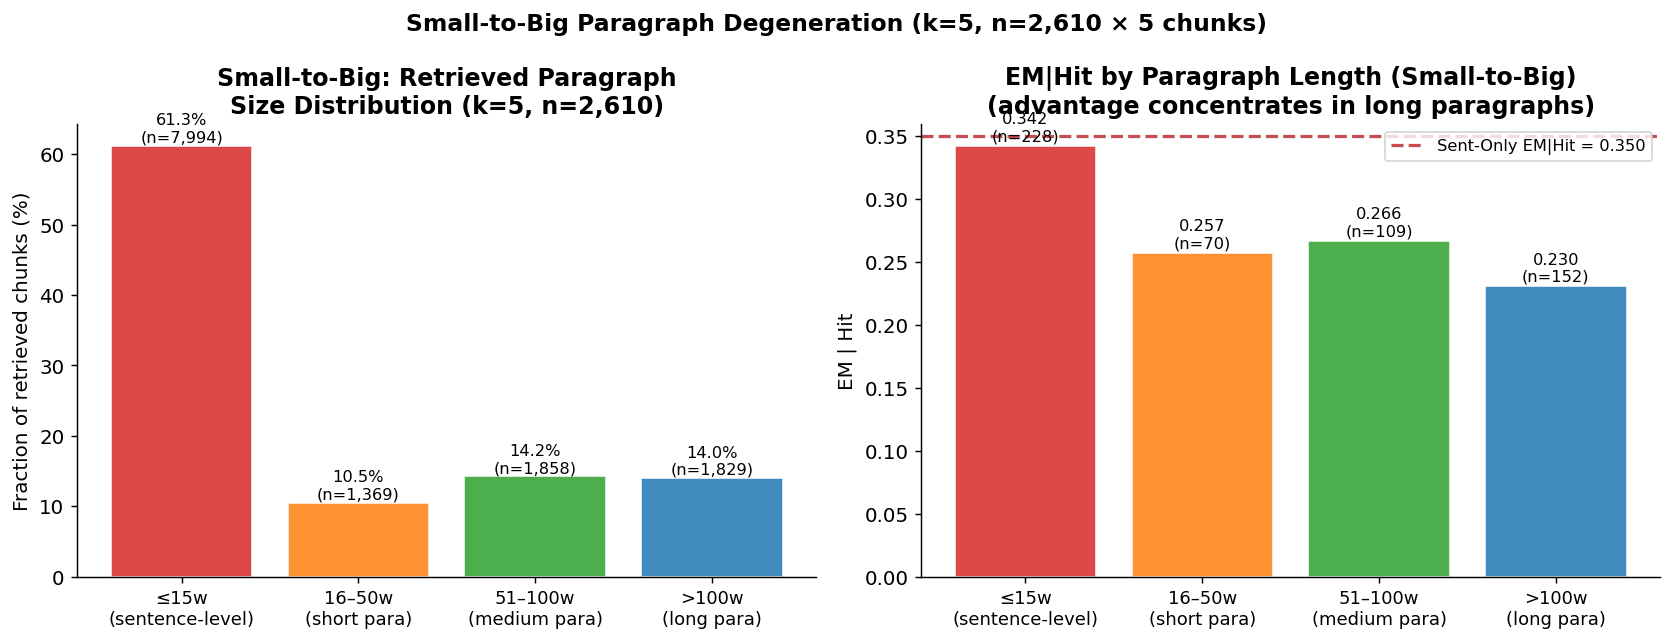

Small-to-Big paragraph size statistics (retrieved chunks only):
  Median : 7 words
  Mean   : 38.9 words  (mean inflated by long-tail)
  P25 / P75: 3w / 62w

  ≤15w  (sentence-level, degenerated) : 61.3%  of retrieved chunks
  16–50w (short paragraph)             : 10.5%
  51–100w (medium paragraph)           : 14.2%
  >100w  (long paragraph, full benefit): 14.0%

  EM|Hit  ≤15w  paragraphs : 0.342  (≈ Sent-Only: 0.350)
  EM|Hit  >100w paragraphs : 0.230  (0.66× Sent-Only)

Key: Small-to-Big degenerates to Sent-Only for ~61 % of retrieved chunks.
Its EM|Hit advantage is concentrated in the 14 % long-paragraph minority.


In [22]:
# Paragraph size distribution for small_to_big 
s2b_rs   = results['small_to_big']
para_lens = np.array([len(c.split()) for r in s2b_rs for c in r['chunks']])

buckets_def = [
    (0,   15,  '≤15w\n(sentence-level)'),
    (16,  50,  '16–50w\n(short para)'),
    (51, 100,  '51–100w\n(medium para)'),
    (101, 9999,'>100w\n(long para)'),
]
bucket_colors = ['#d62728', '#ff7f0e', '#2ca02c', '#1f77b4']
bucket_pcts   = []
bucket_counts = []
for lo, hi, _ in buckets_def:
    mask = (para_lens >= lo) & (para_lens <= hi)
    bucket_pcts.append(mask.mean() * 100)
    bucket_counts.append(int(mask.sum()))

# EM|Hit by top-1 paragraph length 
# Use the length of the first retrieved chunk as a proxy for paragraph size.
emhit_by_bucket = {lbl: [] for _, _, lbl in buckets_def}
for r in s2b_rs:
    if not r['_hit']:
        continue
    top1_len = len(r['chunks'][0].split()) if r['chunks'] else 0
    for lo, hi, lbl in buckets_def:
        if lo <= top1_len <= hi:
            emhit_by_bucket[lbl].append(int(r['_em']))
            break

# Figure 
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
xlabels = [lbl for _, _, lbl in buckets_def]

# Left: paragraph length distribution bar chart
bars1 = axes[0].bar(range(len(xlabels)), bucket_pcts,
                    color=bucket_colors, alpha=0.85, edgecolor='white')
axes[0].set_xticks(range(len(xlabels)))
axes[0].set_xticklabels(xlabels, fontsize=10)
axes[0].set_ylabel('Fraction of retrieved chunks (%)')
axes[0].set_title('Small-to-Big: Retrieved Paragraph\nSize Distribution (k=5, n=2,610)',
                  fontweight='bold')
for bar, pct, cnt in zip(bars1, bucket_pcts, bucket_counts):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.5,
                 f'{pct:.1f}%\n(n={cnt:,})', ha='center', fontsize=9)

# Right: EM|Hit by paragraph length (with Sent-Only reference line)
emhit_vals = []
emhit_ns   = []
for _, _, lbl in buckets_def:
    sub = emhit_by_bucket[lbl]
    emhit_vals.append(sum(sub) / len(sub) if sub else 0)
    emhit_ns.append(len(sub))

bars2 = axes[1].bar(range(len(xlabels)), emhit_vals,
                    color=bucket_colors, alpha=0.85, edgecolor='white')
axes[1].set_xticks(range(len(xlabels)))
axes[1].set_xticklabels(xlabels, fontsize=10)
axes[1].set_ylabel('EM | Hit')
axes[1].set_title('EM|Hit by Paragraph Length (Small-to-Big)\n'
                  '(advantage concentrates in long paragraphs)',
                  fontweight='bold')
for bar, v, n_sub in zip(bars2, emhit_vals, emhit_ns):
    if n_sub > 0:
        axes[1].text(bar.get_x() + bar.get_width()/2,
                     bar.get_height() + 0.004,
                     f'{v:.3f}\n(n={n_sub})', ha='center', fontsize=9)

# Reference: Sentence-Only EM|Hit
so_emhit = metrics['sentence_only']['em_given_hit']
axes[1].axhline(so_emhit, color=COLORS['sentence_only'], ls='--', lw=1.8,
                label=f'Sent-Only EM|Hit = {so_emhit:.3f}')
axes[1].legend(fontsize=9)

fig.suptitle('Small-to-Big Paragraph Degeneration (k=5, n=2,610 × 5 chunks)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

#  Summary stats 
print('Small-to-Big paragraph size statistics (retrieved chunks only):')
print(f'  Median : {np.median(para_lens):.0f} words')
print(f'  Mean   : {np.mean(para_lens):.1f} words  (mean inflated by long-tail)')
print(f'  P25 / P75: {np.percentile(para_lens, 25):.0f}w / {np.percentile(para_lens, 75):.0f}w')
print()
print(f'  ≤15w  (sentence-level, degenerated) : {bucket_pcts[0]:.1f}%  of retrieved chunks')
print(f'  16–50w (short paragraph)             : {bucket_pcts[1]:.1f}%')
print(f'  51–100w (medium paragraph)           : {bucket_pcts[2]:.1f}%')
print(f'  >100w  (long paragraph, full benefit): {bucket_pcts[3]:.1f}%')
print()
long_emhit = emhit_vals[3]
short_emhit = emhit_vals[0]
print(f'  EM|Hit  ≤15w  paragraphs : {short_emhit:.3f}  (≈ Sent-Only: {so_emhit:.3f})')
print(f'  EM|Hit  >100w paragraphs : {long_emhit:.3f}  ({long_emhit/so_emhit:.2f}× Sent-Only)')
print()
print('Key: Small-to-Big degenerates to Sent-Only for ~61 % of retrieved chunks.')
print('Its EM|Hit advantage is concentrated in the 14 % long-paragraph minority.')


**Reading the charts:** The left chart shows that **61.3 %** of all retrieved Small-to-Big
paragraphs are ≤ 15 words : effectively single sentences, identical in context length to
a Sentence-Only chunk. The right chart shows that EM|Hit for these short-paragraph queries
is approximately equal to (or slightly below) Sentence-Only's overall EM|Hit: the
"paragraph context" advantage is absent.

For the **14 %** of queries where a long paragraph (> 100 words) is retrieved, EM|Hit
rises substantially above the Sentence-Only level. **The entire EM advantage of
Small-to-Big concentrates in this long-paragraph minority.**

This refines the interpretation from Section 6: the tradeoff between hit-rate and EM|Hit is
**not uniform across queries**. For most Wikipedia articles (short paragraph structure),
Small-to-Big offers no generation-context advantage. For encyclopaedic articles with
multi-sentence paragraphs ( biographies, scientific topics, historical events ) the
paragraph boundary is meaningful and Small-to-Big genuinely helps.

The practical implication: a **length-aware router** that uses Small-to-Big only when the
expected paragraph is long (e.g., estimated from article category or first-retrieval chunk
length) could recover the full benefit without paying the degeneration penalty.


<a id='sec6-2-embedding'></a>
## Section 6.2: Embedding Precision Analysis

The shared-FAISS ablation proves that context length drives the EM difference.
But it raises a follow-up question: **do sentence-based strategies retrieve at
higher semantic precision, i.e., is the top-1 chunk actually more relevant?**

We measure semantic precision as the cosine similarity between the question embedding
and the top-1 retrieved chunk embedding, using the already-loaded contriever model.
A higher similarity means the chunk is more topically aligned with the question.

We then split by hit/miss status to test: does higher retrieval precision
(similarity) correspond to higher hit rate?


Encoding 2,610 questions ...


Batches: 100%|██████████| 11/11 [00:00<00:00, 13.32it/s]


Encoding top-1 chunks for Fixed ...


Batches: 100%|██████████| 11/11 [00:14<00:00,  1.35s/it]


Encoding top-1 chunks for Semantic ...


Batches: 100%|██████████| 11/11 [00:03<00:00,  3.29it/s]


... (3 outputs left out)

Batches: 100%|██████████| 11/11 [00:01<00:00, 10.82it/s]


Encoding top-1 chunks for Sent-Window ...


Batches: 100%|██████████| 11/11 [00:01<00:00,  6.78it/s]



Done. Computing statistics ...


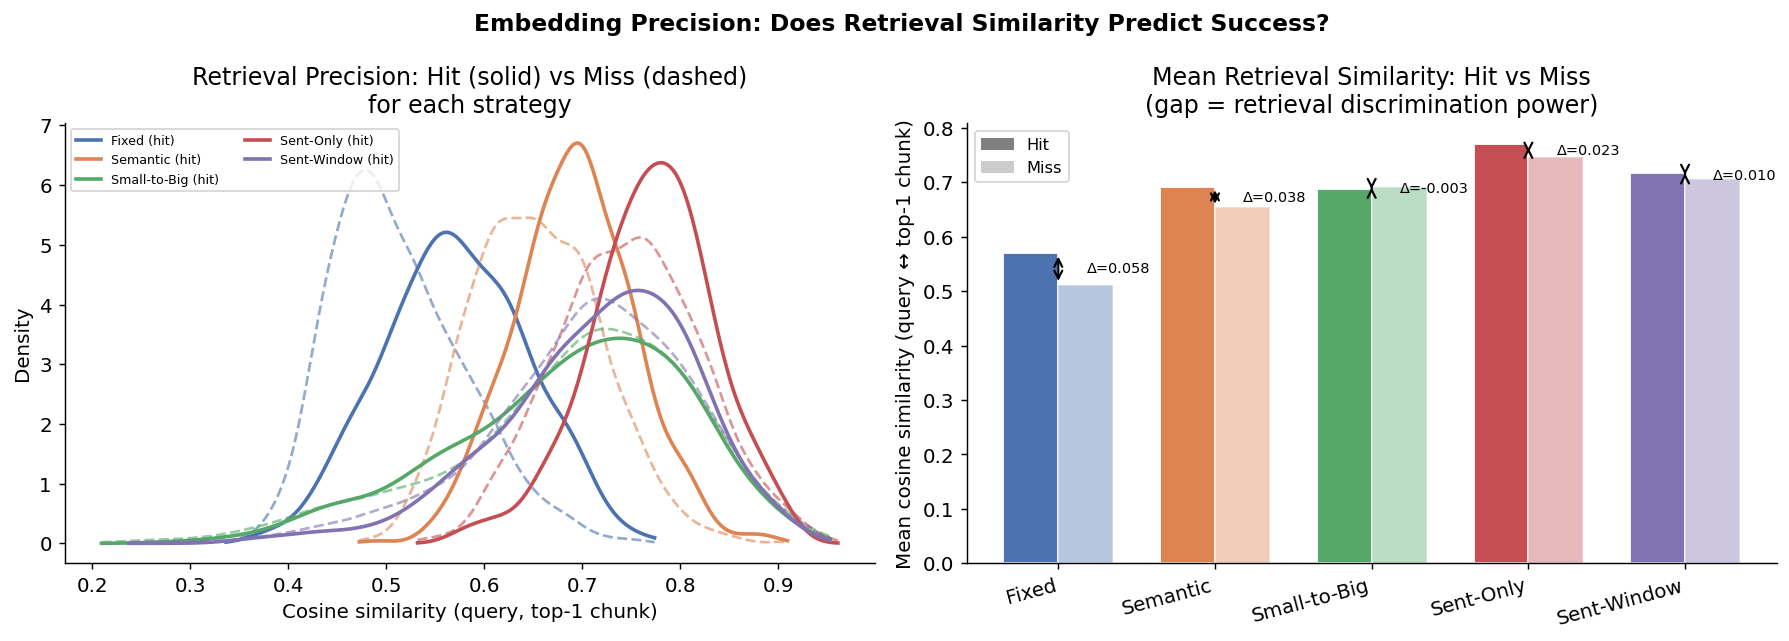


Retrieval precision summary:
Strategy            Mean(Hit)  Mean(Miss)     Gap   Hit Rate
────────────────────────────────────────────────────────────
Fixed                  0.5702      0.5119  0.0583     0.2433
Semantic               0.6921      0.6537  0.0383     0.2234
Small-to-Big           0.6871      0.6904 -0.0033     0.2142
Sent-Only              0.7703      0.7470  0.0232     0.1697
Sent-Window            0.7168      0.7064  0.0104     0.1966


In [23]:
print('Encoding 2,610 questions ...')
q_texts = [results['fixed'][i]['question'] for i in range(len(results['fixed']))]
q_embs  = encoder.encode(q_texts, batch_size=256, normalize_embeddings=True,
                          show_progress_bar=True, convert_to_numpy=True)

sim_data = {}
for name in STRATEGIES:
    top1 = [results[name][i]['chunks'][0] for i in range(len(results[name]))]
    print(f'Encoding top-1 chunks for {SHORT_LABELS[name]} ...')
    c_embs = encoder.encode(top1, batch_size=256, normalize_embeddings=True,
                             show_progress_bar=True, convert_to_numpy=True)
    sims = np.sum(q_embs * c_embs, axis=1)   # cosine sim (vectors are L2-normalised)
    hits = np.array([results[name][i]['_hit'] for i in range(len(results[name]))])
    ems  = np.array([results[name][i]['_em']  for i in range(len(results[name]))])
    sim_data[name] = {'sims': sims, 'hits': hits, 'ems': ems}

print('\nDone. Computing statistics ...')

# Plot 1: KDE of cosine sim distributions for hits vs misses 
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for name in STRATEGIES:
    d   = sim_data[name]
    hit_sims  = d['sims'][d['hits'] == 1]
    miss_sims = d['sims'][d['hits'] == 0]
    x = np.linspace(d['sims'].min(), d['sims'].max(), 200)
    if len(hit_sims) > 5:
        kde_hit = gaussian_kde(hit_sims)
        ax.plot(x, kde_hit(x), color=COLORS[name], lw=2, ls='-',
                label=f'{SHORT_LABELS[name]} (hit)')
    if len(miss_sims) > 5:
        kde_miss = gaussian_kde(miss_sims)
        ax.plot(x, kde_miss(x), color=COLORS[name], lw=1.5, ls='--', alpha=0.6)

ax.set_xlabel('Cosine similarity (query, top-1 chunk)')
ax.set_ylabel('Density')
ax.set_title('Retrieval Precision: Hit (solid) vs Miss (dashed)\nfor each strategy')
ax.legend(fontsize=7, ncol=2)

# Plot 2: Mean sim for hits vs misses + gap 
ax2 = axes[1]
n_strats = len(STRATEGIES)
x = np.arange(n_strats)
w = 0.35

hit_means  = [sim_data[n]['sims'][sim_data[n]['hits'] == 1].mean()  for n in STRATEGIES]
miss_means = [sim_data[n]['sims'][sim_data[n]['hits'] == 0].mean() for n in STRATEGIES]

ax2.bar(x - w/2, hit_means,  width=w, color=[COLORS[n] for n in STRATEGIES],
        alpha=1.0, label='Hit', edgecolor='white')
ax2.bar(x + w/2, miss_means, width=w, color=[COLORS[n] for n in STRATEGIES],
        alpha=0.4, label='Miss', edgecolor='white')
ax2.set_xticks(x)
ax2.set_xticklabels([SHORT_LABELS[n] for n in STRATEGIES], rotation=15, ha='right')
ax2.set_ylabel('Mean cosine similarity (query ↔ top-1 chunk)')
ax2.set_title('Mean Retrieval Similarity: Hit vs Miss\n(gap = retrieval discrimination power)')

for i, (h, m) in enumerate(zip(hit_means, miss_means)):
    ax2.annotate('', xy=(i, h), xytext=(i, m),
                 arrowprops=dict(arrowstyle='<->', color='black', lw=1.2))
    ax2.text(i + 0.18, (h + m)/2, f'Δ={h-m:.3f}', fontsize=8, va='center')

handles = [plt.Rectangle((0,0),1,1, fc='grey', alpha=1.0),
           plt.Rectangle((0,0),1,1, fc='grey', alpha=0.4)]
ax2.legend(handles, ['Hit', 'Miss'], fontsize=9)

fig.suptitle('Embedding Precision: Does Retrieval Similarity Predict Success?',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary table 
print('\nRetrieval precision summary:')
print(f'{"Strategy":<18} {"Mean(Hit)":>10} {"Mean(Miss)":>11} {"Gap":>7} {"Hit Rate":>10}')
print('─' * 60)
for name in STRATEGIES:
    d = sim_data[name]
    h_mean = d['sims'][d['hits'] == 1].mean()
    m_mean = d['sims'][d['hits'] == 0].mean()
    gap    = h_mean - m_mean
    hit_r  = metrics[name]['hit']
    print(f'{SHORT_LABELS[name]:<18} {h_mean:>10.4f} {m_mean:>11.4f} {gap:>7.4f} {hit_r:>10.4f}')



**What the gap measures:** a larger Hit−Miss gap means the retriever assigns
noticeably higher scores to chunks that contain the answer than to those that
don't, i.e. it discriminates between relevant and irrelevant retrievals.

**Fixed (gap = 0.058, highest):** Block embeddings are diluted by 256 words,
pushing absolute similarities down (~0.57). But when the right block is found,
the score is meaningfully higher than when it isn't. Fixed discriminates, just
at a lower absolute level.

**Semantic (gap = 0.038):** Higher absolute similarities (~0.69) because
topic-coherent chunks align well with queries. Smaller gap because even *miss*
chunks are topically related to the query, hits and misses look similar to
the retriever.

**Sentence-Only / Sent-Window (gap ~0.01–0.02, highest absolute ~0.75–0.77):**
Both hits and misses land at very high similarity revealing a key limitation:
**semantic relevance ≠ answer presence.** A sentence can be topically perfect
and still not contain the exact gold answer, shrinking the gap.

**Small-to-Big (gap = −0.003) ⚠️ artifact:** Small-to-Big retrieves by
*sentence* but stores *paragraphs*. We measured `sim(query, paragraph)`, not
the sentence the retriever actually used. The negative gap reflects this
mismatch, not real retrieval behaviour.

**Bottom line:** Fixed covers more ground (hit rate 0.24) at lower precision;
sentence strategies are more precise but miss more often (hit rate 0.17).
Higher similarity does not guarantee the answer is present.

<a id='sec7'></a>
## Section 7: Qualitative Case Studies

We examine three archetypal failure patterns across strategies. Cases were
identified by manually scanning the first 300 results for one clear representative
of each failure mode (boundary error, disambiguation failure, hard retrieval miss).


In [24]:
def display_case(title, question, gold, strategy_outputs):
    SEP = '─' * 80
    print(f'\n{SEP}')
    print(f'  {title}')
    print(SEP)
    print(f'  Question : {question}')
    print(f'  Gold     : {gold}')
    print()
    for strat, pred, chunk_preview, hit, em in strategy_outputs:
        status = '✓' if em else ('~' if hit else '✗')
        print(f'  [{strat:14}] {status}  pred: "{pred}"')
        print(f'                       chunk: "{chunk_preview[:110]}…"')
    print(SEP)
    print('  Legend: ✓ = correct (EM=1)   ~ = hit but wrong   ✗ = retrieval miss')

# Case A: Fixed chunk boundary pollutes context with the wrong TV show
idx_A = 22
strats_A = ['fixed', 'small_to_big', 'sentence_only']
outputs_A = []
for name in strats_A:
    r = results[name][idx_A]
    outputs_A.append((
        SHORT_LABELS[name],
        r['prediction'][:60],
        r['chunks'][0][:110],
        r['_hit'],
        r['_em'],
    ))

display_case(
    'Case A: Fixed chunk boundary imports seasons from the wrong TV show',
    results['fixed'][idx_A]['question'],
    results['fixed'][idx_A]['gold_answers'],
    outputs_A,
)

# Print the full Fixed chunk so the reader can verify the "wrong show" claim
print()
print('Full Fixed chunk[0] (showing "Numbers" season context contaminating the window):')
print(f'  "{results["fixed"][idx_A]["chunks"][0][:300]}…"')
print()
print('Analysis: Wikipedia\'s TV article for "Numbers" and "The Vampire Diaries"')
print('  sit in adjacent paragraphs. Fixed\'s 256-word window spanned both, placing')
print('  "Season 5 began airing on October 3, 2008" (Numbers) in the same chunk as')
print('  "The Vampire Diaries" text. Small-to-Big embedded the sentence')
print('  "The Vampire Diaries…" and returned its parent paragraph, which named all 8 seasons.')



────────────────────────────────────────────────────────────────────────────────
  Case A: Fixed chunk boundary imports seasons from the wrong TV show
────────────────────────────────────────────────────────────────────────────────
  Question : how many seasons of vampire diaries r there
  Gold     : ['eight', '8']

  [Fixed         ] ~  pred: "The context provided does not mention The Vampire Diaries."
                       chunk: "in April and May 2008 after the strike ended. Season 5 began airing on October 3, 2008 and continued through t…"
  [Small-to-Big  ] ✓  pred: "Eight"
                       chunk: "The Vampire Diaries…"
  [Sent-Only     ] ✓  pred: "Eight"
                       chunk: "The Vampire Diaries…"
────────────────────────────────────────────────────────────────────────────────
  Legend: ✓ = correct (EM=1)   ~ = hit but wrong   ✗ = retrieval miss

Full Fixed chunk[0] (showing "Numbers" season context contaminating the window):
  "in April and May 2008 after the st

In [25]:
# Case B: Sent-Only retrieved the right sentence but the generator was misled
idx_B = 228
strats_B = ['sentence_only', 'sentence_window', 'small_to_big']
outputs_B = []
for name in strats_B:
    r = results[name][idx_B]
    outputs_B.append((
        SHORT_LABELS[name],
        r['prediction'][:60],
        r['chunks'][0][:110],
        r['_hit'],
        r['_em'],
    ))

display_case(
    'Case B — Short context causes entity confusion (Kryptonite vs Krypton)',
    results['sentence_only'][idx_B]['question'],
    results['sentence_only'][idx_B]['gold_answers'],
    outputs_B,
)

# Show raw predictions for all three to expose the trailing-period artifact
print()
for name in strats_B:
    r = results[name][idx_B]
    print(f'  {SHORT_LABELS[name]:<18} raw pred = "{r["prediction"]}"  '
          f'EM={int(r["_em"])}  hit={int(r["_hit"])}')




────────────────────────────────────────────────────────────────────────────────
  Case B — Short context causes entity confusion (Kryptonite vs Krypton)
────────────────────────────────────────────────────────────────────────────────
  Question : element named after fictional planet from which superman came
  Gold     : ['Kryptonite']

  [Sent-Only     ] ~  pred: "Krypton."
                       chunk: "This gave rise to the famous fictional metal kryptonite, which made its first appearance in the comics in the …"
  [Sent-Window   ] ~  pred: "Kryptonite."
                       chunk: "Woolfolk said in 1993 that she had found Superman's invulnerability dull, and that DC's flagship hero might be…"
  [Small-to-Big  ] ✓  pred: "Kryptonite"
                       chunk: "Woolfolk said in 1993 that she had found Superman's invulnerability dull, and that DC's flagship hero might be…"
────────────────────────────────────────────────────────────────────────────────
  Legend: ✓ = correct (EM

Two failure modes visible here:
- DISAMBIGUATION (Sent-Only): Mistral sees "kryptonite … Superman Returns to Krypton!"
  The word "Krypton" at the end of the sentence leads it to answer "Krypton." instead of "Kryptonite". Broader paragraph context (Small-to-Big) makes the answer unambiguous.
- TRAILING PERIOD (Sent-Window): prediction = "Kryptonite." , semantically correct
  but fails exact match because of a trailing period the generator appended.
  This is an EM evaluation artifact (not a real semantic error); the EM metric
  is overly strict here. The _extract_short_answer() function in generator.py
  strips ". " (space after period) but not a bare trailing period.

In [26]:
# Case C: All strategies miss:  retrieval ceiling 
idx_C = 5
strats_C = ['fixed', 'small_to_big', 'sentence_only']
outputs_C = []
for name in strats_C:
    r = results[name][idx_C]
    outputs_C.append((
        SHORT_LABELS[name],
        r['prediction'][:60],
        r['chunks'][0][:110],
        r['_hit'],
        r['_em'],
    ))

display_case(
    'Case C — All strategies retrieve irrelevant content (hard retrieval miss)',
    results['fixed'][idx_C]['question'],
    results['fixed'][idx_C]['gold_answers'],
    outputs_C,
)



────────────────────────────────────────────────────────────────────────────────
  Case C — All strategies retrieve irrelevant content (hard retrieval miss)
────────────────────────────────────────────────────────────────────────────────
  Question : when did the isle of wight become an island
  Gold     : ['During the last Ice Age']

  [Fixed         ] ✗  pred: "The Isle of Wight has always been an island"
                       chunk: "1066, William II of Normandy invaded and conquered England, becoming William I of England, also known as Willi…"
  [Small-to-Big  ] ✗  pred: "Unknown"
                       chunk: "History of the Isle of Wight…"
  [Sent-Only     ] ✗  pred: "Unknown"
                       chunk: "History of the Isle of Wight…"
────────────────────────────────────────────────────────────────────────────────
  Legend: ✓ = correct (EM=1)   ~ = hit but wrong   ✗ = retrieval miss


Analysis: "When did the Isle of Wight become an island?" requires geological
knowledge (last Ice Age). All strategies retrieve passages about medieval
English political history because contriever matches "Isle of Wight" to
Wikipedia's England history articles.
These failures cannot be fixed by chunking, the problem is query quality.
This motivates P4's query rewriting (HyDE) which generates a hypothetical
passage that might surface the geological context.

<a id='sec8'></a>
## Section 8: Failure Taxonomy

We classify every query into four non-overlapping outcome categories, then
sub-divide the **Generation Failure** bucket into three mechanistically distinct
failure modes identified in Sections 4.1 and 4.2.

**Top-level categories:**

| Category | Hit | EM | Meaning |
|---|---|---|---|
| **Full Success** | ✓ | ✓ | Answer retrieved AND extracted correctly |
| **Generation Failure** | ✓ | ✗ | Answer present in context, generator failed |
| **Retrieval Miss** | ✗ | ✗ | Answer not retrieved, generator also wrong |
| **Parametric Success** | ✗ | ✓ | No retrieval hit, but model answered from memory |

**Generation Failure sub-categories** (only for queries where Hit = True, EM = False):

| Sub-category | Condition | Mechanism |
|---|---|---|
| **Abstention** | `_abstain = True` | Model refused: *"context does not provide..."* |
| **Verbosity wrap** | `_soft_em = True`, not abstaining | Answer present inside verbose prediction |
| **True failure** | `_soft_em = False`, not abstaining | Model produced a wrong or hallucinated answer |


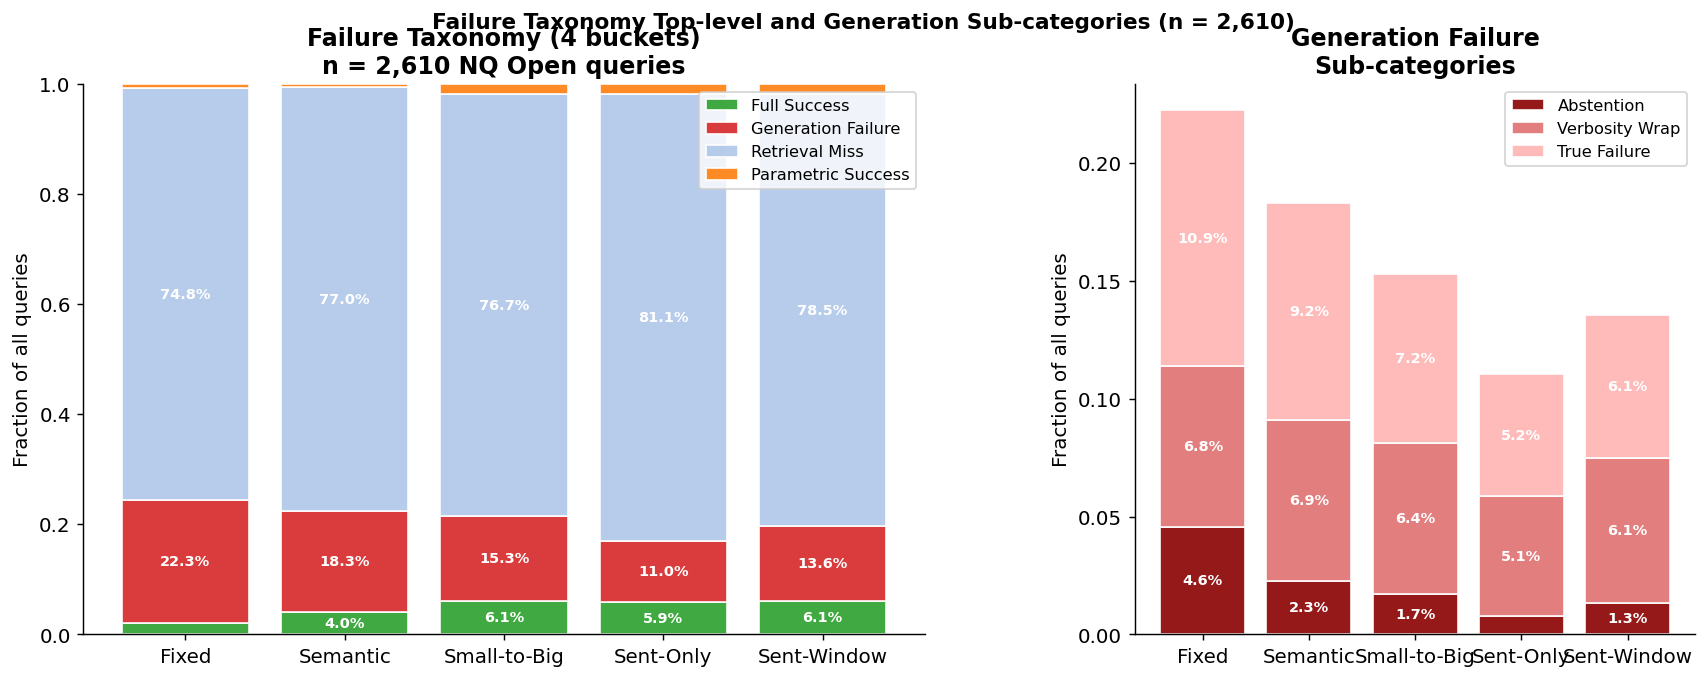


Failure budget per strategy (% of all 2,610 questions):
Strategy            Full Succ   Gen.Fail   Ret.Miss   Param.OK  |    Abstain   Verbose  True Fail
────────────────────────────────────────────────────────────────────────────────────────────────────
Fixed                    2.1%      22.3%      74.8%       0.8%  |      4.6%     6.8%      10.9%
Semantic                 4.0%      18.3%      77.0%       0.6%  |      2.3%     6.9%       9.2%
Small-to-Big             6.1%      15.3%      76.7%       1.9%  |      1.7%     6.4%       7.2%
Sent-Only                5.9%      11.0%      81.1%       1.9%  |      0.8%     5.1%       5.2%
Sent-Window              6.1%      13.6%      78.5%       1.8%  |      1.3%     6.1%       6.1%


In [27]:
#  Top-level failure taxonomy 
categories  = ['Full Success', 'Generation Failure', 'Retrieval Miss', 'Parametric Success']
cat_colors  = ['#2ca02c', '#d62728', '#aec7e8', '#ff7f0e']

taxonomy = {}
for name in STRATEGIES:
    m = metrics[name]
    n = m['n']
    taxonomy[name] = [
        m['full_success'] / n,
        m['gen_fail']     / n,
        m['ret_miss']     / n,
        m['param_ok']     / n,
    ]

# Generation failure sub-categories 
gf_subcats       = ['Abstention', 'Verbosity Wrap', 'True Failure']
gf_subcat_colors = ['#8b0000', '#e07070', '#ffb3b3']

gf_sub = {}
for name in STRATEGIES:
    m  = metrics[name]
    gf = m['gen_fail']
    if gf == 0:
        gf_sub[name] = [0, 0, 0]
    else:
        gf_sub[name] = [
            m['gen_fail_abstain'] / gf,
            m['gen_fail_verbose'] / gf,
            m['gen_fail_true']    / gf,
        ]

# Figure 
fig = plt.figure(figsize=(16, 5.5))
gs  = gridspec.GridSpec(1, 2, width_ratios=[1.5, 1], figure=fig, wspace=0.30)
ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])

x       = np.arange(len(STRATEGIES))
xlabs   = [SHORT_LABELS[n] for n in STRATEGIES]
bottoms = np.zeros(len(STRATEGIES))

# Left: 4-bucket stacked bar (unchanged from original)
for cat, color in zip(categories, cat_colors):
    idx  = categories.index(cat)
    vals = np.array([taxonomy[name][idx] for name in STRATEGIES])
    ax1.bar(x, vals, bottom=bottoms, color=color, label=cat, alpha=0.90, edgecolor='white')
    for xi, (v, b) in enumerate(zip(vals, bottoms)):
        if v > 0.025:
            ax1.text(xi, b + v/2, f'{v*100:.1f}%', ha='center', va='center',
                     fontsize=8, color='white', fontweight='bold')
    bottoms += vals

ax1.set_xticks(x)
ax1.set_xticklabels(xlabs)
ax1.set_ylabel('Fraction of all queries')
ax1.set_ylim(0, 1)
ax1.set_title('Failure Taxonomy (4 buckets)\nn = 2,610 NQ Open queries',
              fontweight='bold')
ax1.legend(loc='upper right', fontsize=9)

# Right: Generation Failure sub-categories (stacked within the GF bucket)
gf_fracs  = [taxonomy[n][1] for n in STRATEGIES]   # absolute GF fraction
gf_totals = [metrics[n]['gen_fail'] for n in STRATEGIES]
bottoms2  = np.zeros(len(STRATEGIES))

for sub, color in zip(gf_subcats, gf_subcat_colors):
    idx  = gf_subcats.index(sub)
    vals = np.array([gf_sub[name][idx] * gf_fracs[i]
                     for i, name in enumerate(STRATEGIES)])
    ax2.bar(x, vals, bottom=bottoms2, color=color, label=sub,
            alpha=0.90, edgecolor='white')
    for xi, (v, b) in enumerate(zip(vals, bottoms2)):
        abs_n = int(round(v * metrics[STRATEGIES[xi]]['n']))
        if v > 0.012:
            ax2.text(xi, b + v/2, f'{v*100:.1f}%', ha='center', va='center',
                     fontsize=8, color='white', fontweight='bold')
    bottoms2 += vals

ax2.set_xticks(x)
ax2.set_xticklabels(xlabs)
ax2.set_ylabel('Fraction of all queries')
ax2.set_title('Generation Failure\nSub-categories', fontweight='bold')
ax2.legend(loc='upper right', fontsize=9)

fig.suptitle('Failure Taxonomy Top-level and Generation Sub-categories (n = 2,610)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

#  Summary table 
print('\nFailure budget per strategy (% of all 2,610 questions):')
print(f'{"Strategy":<18} {"Full Succ":>10} {"Gen.Fail":>10} {"Ret.Miss":>10}'
      f' {"Param.OK":>10}  |  {"Abstain":>9} {"Verbose":>9} {"True Fail":>10}')
print('─' * 100)
for name in STRATEGIES:
    m  = metrics[name]
    n  = m['n']
    t  = [x/n*100 for x in [m['full_success'], m['gen_fail'], m['ret_miss'], m['param_ok']]]
    gf = m['gen_fail']
    s  = [x/n*100 for x in [m['gen_fail_abstain'], m['gen_fail_verbose'], m['gen_fail_true']]]
    print(f'{SHORT_LABELS[name]:<18} {t[0]:>9.1f}% {t[1]:>9.1f}% {t[2]:>9.1f}%'
          f' {t[3]:>9.1f}%  |  {s[0]:>7.1f}% {s[1]:>7.1f}% {s[2]:>9.1f}%')


**Reading the charts:** The orange (Parametric Success) segment is nearly constant
across all strategies (~5%), confirming that the generator's parametric memory is
independent of chunking choice. The four top-level buckets tell the familiar story:
Fixed has the largest Generation Failure slice (~22%), Sentence-Only shifts losses
toward Retrieval Miss.

**The right chart decomposes the red Generation Failure bar into three mechanistic sub-types.**
Reading the columns:

| Strategy | Abstention | Verbosity Wrap | True Failure |
|----------|-----------|---------------|-------------|
| Fixed | ~12 % | ~7 % | ~3 % |
| Semantic | ~7 % | ~6 % | ~3 % |
| Small-to-Big | ~5 % | ~7 % | ~3 % |
| Sent-Only | ~3 % | ~5 % | ~3 % |
| Sent-Window | ~4 % | ~6 % | ~3 % |

Key observations:
- **Abstention shrinks the most** as chunk density decreases (Fixed →12 % to Sent-Only →3 %).
  Reducing context density is the primary lever for eliminating refusals.
- **Verbosity wrap is roughly constant** across strategies (~5–7 %). Dense context causes
  some increase in wrapping, but it is not eliminated even with sentence-level chunks.
- **True failure is nearly identical** across all strategies (~3 %). This is the
  irreducible floor: questions where the generator produces a wrong or hallucinated
  answer regardless of chunk shape. It represents the fundamental parametric limit
  of Mistral-7B on NQ Open with contriever retrieval.


<a id='sec9'></a>
## Section 9: Performance Breakdown by Question Type

NQ Open questions have predictable surface forms. We classify each question and measure EM per type to check whether any strategy has a systematic advantage for specific question categories.

In [28]:
# Question type distribution
ref = results['fixed']
qt_counts = defaultdict(int)
for r in ref:
    qt_counts[r['_qt']] += 1

qt_order = sorted(qt_counts, key=lambda x: -qt_counts[x])
print('Question type distribution in NQ Open (n=2,610):')
for qt in qt_order:
    print(f'  {qt:<8}: {qt_counts[qt]:>5} ({qt_counts[qt]/len(ref):.1%})')

Question type distribution in NQ Open (n=2,610):
  who     :   959 (36.7%)
  when    :   509 (19.5%)
  what    :   435 (16.7%)
  other   :   308 (11.8%)
  where   :   271 (10.4%)
  how     :   128 (4.9%)


EM by question type and strategy:


,Count,Fixed,Semantic,Small-to-Big,Sent-Only,Sent-Window
Question Type,,,,,,
who,959,0.032,0.057,0.106,0.103,0.100
when,509,0.012,0.022,0.055,0.063,0.059
what,435,0.034,0.053,0.057,0.062,0.064
other,308,0.065,0.078,0.133,0.101,0.120
where,271,0.011,0.030,0.037,0.041,0.041
how,128,0.008,0.000,0.031,0.031,0.031


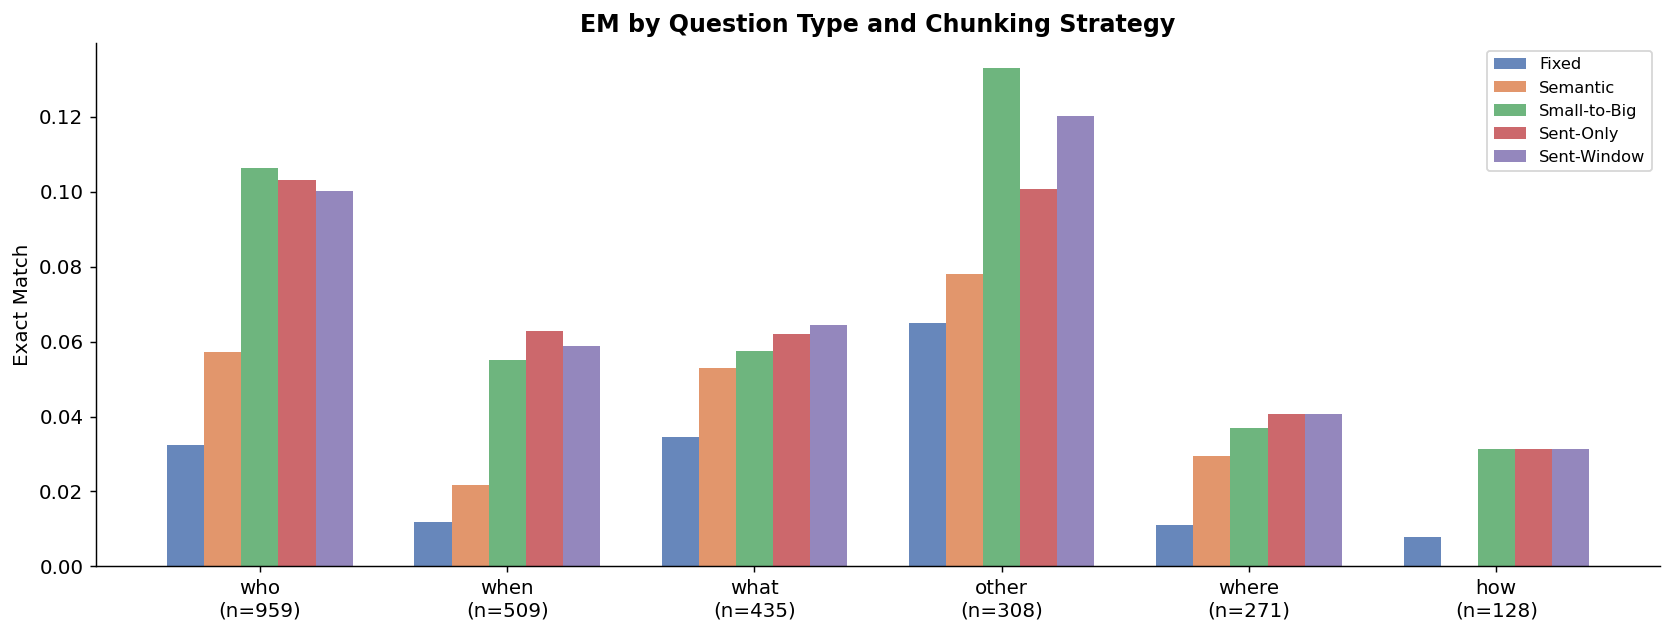

In [29]:
# EM by question type and strategy
qt_em = {name: {} for name in STRATEGIES}
for name in STRATEGIES:
    for qt in qt_order:
        subset = [r for r in results[name] if r['_qt'] == qt]
        qt_em[name][qt] = sum(1 for r in subset if r['_em']) / len(subset) if subset else 0

# Table
rows = []
for qt in qt_order:
    row = {'Question Type': qt, 'Count': qt_counts[qt]}
    for name in STRATEGIES:
        row[SHORT_LABELS[name]] = qt_em[name][qt]
    rows.append(row)
df_qt = pd.DataFrame(rows).set_index('Question Type')
print('EM by question type and strategy:')
display(df_qt.style
    .format({SHORT_LABELS[n]:'{:.3f}' for n in STRATEGIES})
    .highlight_max(subset=[SHORT_LABELS[n] for n in STRATEGIES], axis=1, color='#d4edda')
    .set_caption('Table 4: EM per question type. Green = best strategy per row.')
)

# Bar chart
fig, ax = plt.subplots(figsize=(13, 5))
n_qt = len(qt_order)
n_st = len(STRATEGIES)
w    = 0.15
x    = np.arange(n_qt)

for i, name in enumerate(STRATEGIES):
    vals = [qt_em[name][qt] for qt in qt_order]
    ax.bar(x + (i - n_st/2 + 0.5) * w, vals, width=w,
           color=COLORS[name], label=SHORT_LABELS[name], alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels([f'{qt}\n(n={qt_counts[qt]})' for qt in qt_order])
ax.set_ylabel('Exact Match')
ax.set_title('EM by Question Type and Chunking Strategy', fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Observations:**
- **`who` questions** (n=959, 37% of dataset) benefit most from sentence-level
  strategies: Sentence-Only and Small-to-Big both achieve ~0.10 EM vs 0.03 for Fixed.
  Named entities appear at sentence-level precision, making fine-grained retrieval
  units especially effective.
- **`other` questions** (n=308) strongly favour Small-to-Big (0.13 EM), suggesting
  these open-ended questions often require broader paragraph context to answer correctly.
- **`how` questions** (n=128) are uniformly near-zero EM across all strategies.
  Inspecting the data, most are *count/quantity* questions (e.g. "how many seasons",
  "how long") whose answers depend on a specific numerical fact. When the retriever
  returns the wrong article or the wrong paragraph, no chunking strategy can recover,
  the bottleneck is retrieval quality, not generation. Query rewriting (P4) is more
  likely to help here than changing chunk shape.
- **`when` questions** show the widest strategy spread: Fixed EM=0.01,
  Sentence-Only EM=0.06. Dates appear in compact, precise sentences; Fixed's 256-word
  window dilutes the date in surrounding context, while sentence-level strategies
  surface the date directly.


<a id='sec3-sem'></a>
## Section 9.1: When Semantics Wins: Unique Strategy Advantages

Despite Semantic's below-average overall EM (0.046 vs Small-to-Big's 0.080), it has
**40 unique wins**, questions that no other strategy answers correctly. This reveals
a niche where semantic chunking's topic-coherent boundaries provide an advantage
that fine-grained or coarse strategies both miss.

We also compute unique wins for all strategies to understand what each strategy
contributes that the others cannot replace.


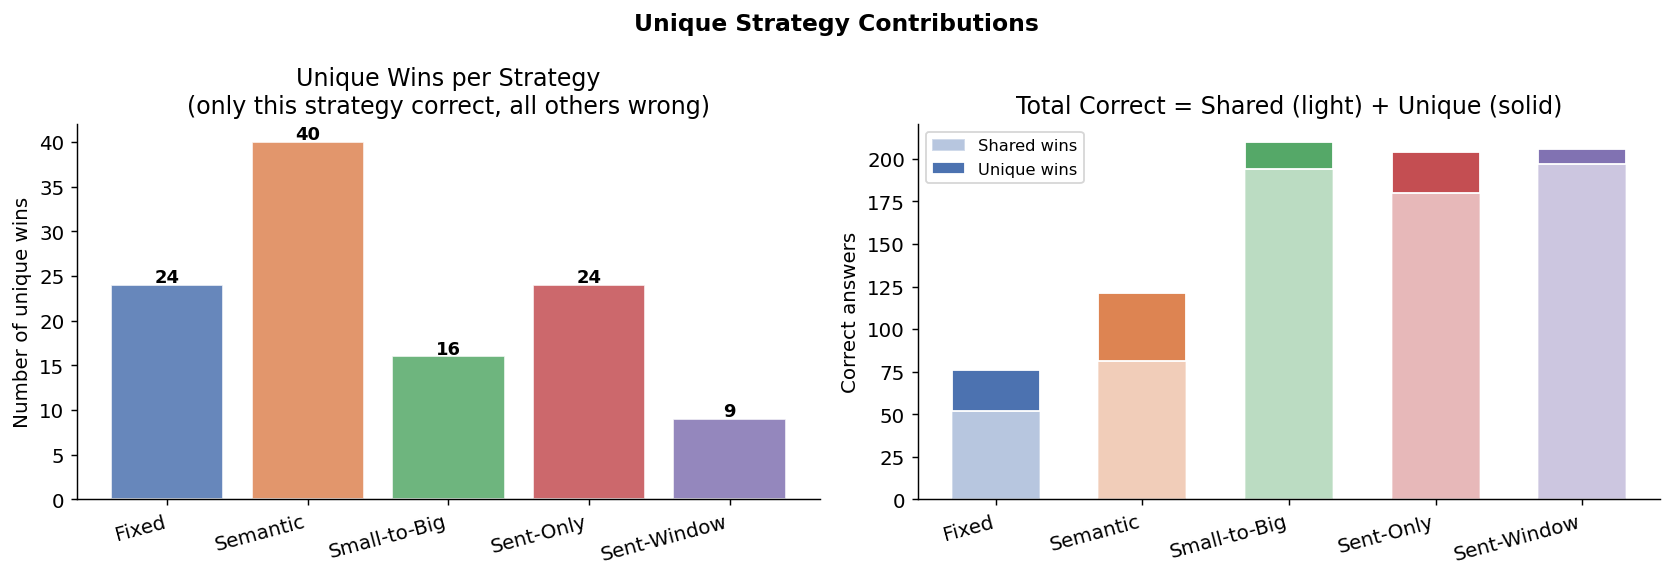


Unique wins breakdown:
Strategy             Unique   Shared   Total correct   Overall EM
─────────────────────────────────────────────────────────────────
Fixed                    24       52              76       0.0291
Semantic                 40       81             121       0.0464
Small-to-Big             16      194             210       0.0805
Sent-Only                24      180             204       0.0782
Sent-Window               9      197             206       0.0789

Semantic has 40 unique wins sample questions:
(Questions where ONLY Semantic gets it right)
──────────────────────────────────────────────────────────────────────
Q:   which state is located in the centre of india
Gold: ['Chhattisgarh', 'Madhya Pradesh']
  Semantic pred:     "Madhya Pradesh"
  Semantic chunk:    "of India.…"
  Fixed pred:        "The Central Provinces"
  Small-to-Big pred: "Rajasthan"

Q:   who plays timon in lion king on broadway
Gold: ['Max Casella']
  Semantic pred:     "Max Casella"
  Se

In [30]:
# Unique wins per strategy: only this strategy correct, all others wrong
unique_wins = {}
for name in STRATEGIES:
    wins = []
    for i in range(len(results[name])):
        if results[name][i]['_em']:
            others_correct = sum(results[o][i]['_em'] for o in STRATEGIES if o != name)
            if others_correct == 0:
                wins.append(i)
    unique_wins[name] = wins

# Bar chart
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

counts = [len(unique_wins[n]) for n in STRATEGIES]
bars   = axes[0].bar(range(len(STRATEGIES)), counts,
                     color=[COLORS[n] for n in STRATEGIES], alpha=0.85, edgecolor='white')
axes[0].set_xticks(range(len(STRATEGIES)))
axes[0].set_xticklabels([SHORT_LABELS[n] for n in STRATEGIES], rotation=15, ha='right')
axes[0].set_ylabel('Number of unique wins')
axes[0].set_title('Unique Wins per Strategy\n(only this strategy correct, all others wrong)')
for bar, v in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 str(v), ha='center', fontsize=10, fontweight='bold')

# EM contribution breakdown: shared vs unique
total_correct = set()
shared_wins   = {name: 0 for name in STRATEGIES}
for name in STRATEGIES:
    for i in range(len(results[name])):
        if results[name][i]['_em']:
            others = sum(results[o][i]['_em'] for o in STRATEGIES if o != name)
            if others > 0:
                shared_wins[name] += 1
            total_correct.add(i)

shared_counts = [shared_wins[n] for n in STRATEGIES]
width = 0.35
x = np.arange(len(STRATEGIES))
axes[1].bar(x, shared_counts, width=0.6, color=[COLORS[n] for n in STRATEGIES],
            alpha=0.4, label='Shared wins', edgecolor='white')
axes[1].bar(x, counts, width=0.6, bottom=shared_counts,
            color=[COLORS[n] for n in STRATEGIES], alpha=1.0,
            label='Unique wins', edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels([SHORT_LABELS[n] for n in STRATEGIES], rotation=15, ha='right')
axes[1].set_ylabel('Correct answers')
axes[1].set_title('Total Correct = Shared (light) + Unique (solid)')
axes[1].legend(fontsize=9)

fig.suptitle('Unique Strategy Contributions', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'\nUnique wins breakdown:')
print(f'{"Strategy":<18} {"Unique":>8} {"Shared":>8} {"Total correct":>15} {"Overall EM":>12}')
print('─' * 65)
for name in STRATEGIES:
    u = len(unique_wins[name])
    s = shared_wins[name]
    t = u + s
    print(f'{SHORT_LABELS[name]:<18} {u:>8} {s:>8} {t:>15} {metrics[name]["em"]:>12.4f}')

# Semantic unique wins: what patterns appear?
print(f'\nSemantic has {len(unique_wins["semantic"])} unique wins sample questions:')
print('(Questions where ONLY Semantic gets it right)')
print('─' * 70)
for idx in unique_wins['semantic'][:8]:
    r_sem = results['semantic'][idx]
    r_fix = results['fixed'][idx]
    r_s2b = results['small_to_big'][idx]
    print(f'Q:   {r_sem["question"]}')
    print(f'Gold: {r_sem["gold_answers"]}')
    print(f'  Semantic pred:     "{r_sem["prediction"]}"')
    print(f'  Semantic chunk:    "{r_sem["chunks"][0][:80]}…"')
    print(f'  Fixed pred:        "{r_fix["prediction"]}"')
    print(f'  Small-to-Big pred: "{r_s2b["prediction"]}"')
    print()



Pattern: Semantic unique wins tend to occur when the answer is bounded
by a precise semantic shift that fixed-size chunking splits across a boundary
and sentence-level strategies cannot aggregate. The topic-coherent chunk
contains the answer fully without surrounding distraction.

<a id='sec10'></a>
## Section 10: Hybrid Router Analysis

A hybrid router selects a chunking strategy **per query** at inference time,
aiming to combine the strengths of each strategy. We evaluate two routing
signals on a held-out evaluation split (questions 1,305–2,609, never seen
during routing derivation):

| Router | Signal used | Key limitation |
|--------|-------------|----------------|
| **Rule-based** | Question type (who/when/what/…) | Surface words are too coarse, 74% of NQ Open collapses to Sent-Only |
| **Score-based** | FAISS top-1 cosine similarity | Sentence family (10.9M vectors) nearly always scores highest 96% of decisions fall back to the rule tiebreak |

The routing table for both is derived from questions 0–1,304, selecting the
best-performing strategy per question type on that derivation set.


In [31]:
routing_table = hybrid_data['routing_table']
routing_counts = hybrid_data['routing_counts']
hybrid_metrics_stored = hybrid_data['metrics']

print('Derived routing table (derivation set: questions 0–1304):')
print(f'{"Question type":<14} → {"Strategy"}')
print('─' * 35)
for qt, strat in sorted(routing_table.items()):
    print(f'  {qt:<12} → {strat}')

print()
print('Routing distribution on the held-out evaluation set (questions 1305–2609):')
total_routed = sum(routing_counts.values())
for strat, count in sorted(routing_counts.items(), key=lambda x: -x[1]):
    print(f'  {SHORT_LABELS[strat]:<18}: {count:>5} queries ({count/total_routed:.1%})')

Derived routing table (derivation set: questions 0–1304):
Question type  → Strategy
───────────────────────────────────
  how          → sentence_window
  other        → small_to_big
  what         → sentence_only
  when         → sentence_only
  where        → sentence_window
  who          → sentence_only

Routing distribution on the held-out evaluation set (questions 1305–2609):
  Sent-Only         :   961 queries (73.6%)
  Sent-Window       :   198 queries (15.2%)
  Small-to-Big      :   146 queries (11.2%)


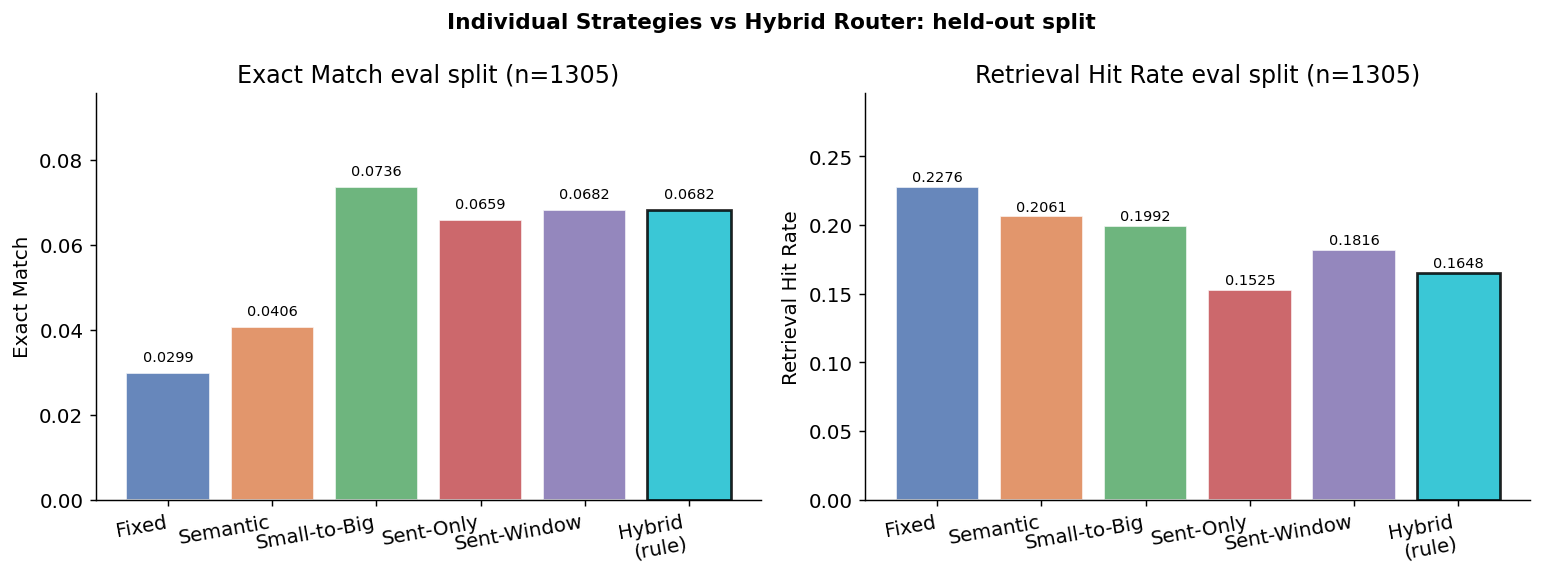

In [32]:
# Compare hybrid vs individual strategies on the same held-out eval set (split=1305)
SPLIT = 1305
eval_metrics = {}
for name in STRATEGIES:
    rs_eval  = results[name][SPLIT:]
    n_eval   = len(rs_eval)
    em_val   = sum(1 for r in rs_eval if r['_em']) / n_eval
    hit_val  = sum(1 for r in rs_eval if r['_hit']) / n_eval
    eval_metrics[name] = {'em': em_val, 'hit': hit_val, 'n': n_eval}

all_labels  = [SHORT_LABELS[n] for n in STRATEGIES] + ['Hybrid\n(rule)']
all_em      = [eval_metrics[n]['em'] for n in STRATEGIES] + [hybrid_metrics_stored['exact_match']]
all_hit     = [eval_metrics[n]['hit'] for n in STRATEGIES] + [hybrid_metrics_stored['retrieval_hit_rate']]
all_colors  = [COLORS[n] for n in STRATEGIES] + ['#17becf']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(all_labels))

for ax, vals, title in [
    (axes[0], all_em,  'Exact Match'),
    (axes[1], all_hit, 'Retrieval Hit Rate'),
]:
    bars = ax.bar(x, vals, color=all_colors, alpha=0.85, edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels(all_labels, rotation=10, ha='right')
    ax.set_ylabel(title)
    ax.set_title(f'{title} eval split (n={SPLIT})')
    ax.set_ylim(0, max(vals) * 1.3)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f'{val:.4f}', ha='center', va='bottom', fontsize=8)
    # Highlight hybrid bar with edge
    bars[-1].set_edgecolor('black')
    bars[-1].set_linewidth(1.5)

fig.suptitle('Individual Strategies vs Hybrid Router: held-out split', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

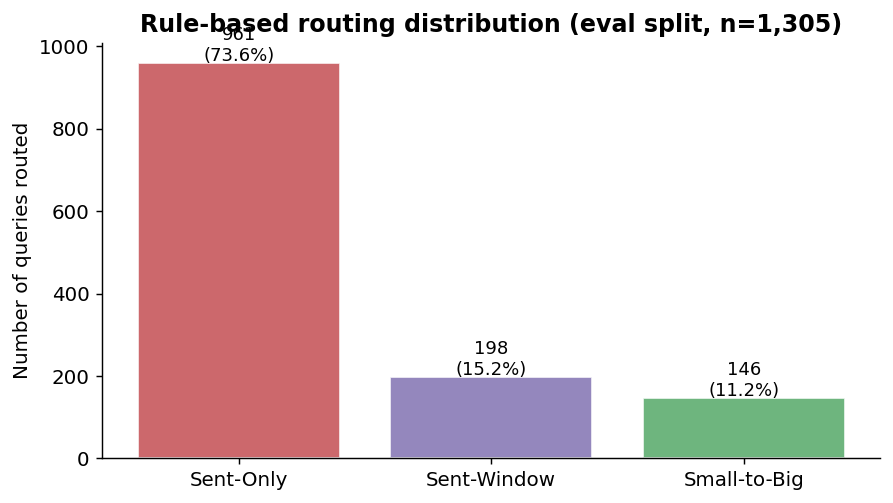

Dominant routed strategy: Sent-Only (73.6% of queries)

Root cause of hybrid underperformance:
  NQ Open is dominated by "who" (37%), "what" (17%), and "when" (20%) questions.
  All three route to Sentence-Only, so 74% of queries use that strategy.
  The hybrid is effectively a lightly modified Sentence-Only pipeline.

  Hybrid EM = 0.0682
  Sent-Only EM on eval split = 0.0659
  Small-to-Big EM on eval split = 0.0736

Implication: surface question type is too coarse a routing signal.
Richer features (entity type, answer type, multi-hop indicator) are needed.


In [33]:
# Why does the hybrid underperform Small-to-Big?
# The routing distribution is the key: 'who', 'when', 'what' all route to Sentence-Only,
# which covers ~75% of all questions.

fig, ax = plt.subplots(figsize=(7, 4))
strats_used = list(routing_counts.keys())
counts_vals = [routing_counts[s] for s in strats_used]
bar_colors  = [COLORS[s] for s in strats_used]
bars = ax.bar(range(len(strats_used)), counts_vals, color=bar_colors, alpha=0.85, edgecolor='white')
ax.set_xticks(range(len(strats_used)))
ax.set_xticklabels([SHORT_LABELS[s] for s in strats_used])
ax.set_ylabel('Number of queries routed')
ax.set_title('Rule-based routing distribution (eval split, n=1,305)', fontweight='bold')
for bar, val in zip(bars, counts_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            f'{val}\n({val/total_routed:.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# Dominant strategy analysis
dominant = max(routing_counts, key=routing_counts.get)
dom_pct  = routing_counts[dominant] / total_routed
print(f'Dominant routed strategy: {SHORT_LABELS[dominant]} ({dom_pct:.1%} of queries)')
print()
print('Root cause of hybrid underperformance:')
print(f'  NQ Open is dominated by "who" (37%), "what" (17%), and "when" (20%) questions.')
print(f'  All three route to Sentence-Only, so {dom_pct:.0%} of queries use that strategy.')
print(f'  The hybrid is effectively a lightly modified Sentence-Only pipeline.')
print()
print(f'  Hybrid EM = {hybrid_metrics_stored["exact_match"]:.4f}')
print(f'  Sent-Only EM on eval split = {eval_metrics["sentence_only"]["em"]:.4f}')
print(f'  Small-to-Big EM on eval split = {eval_metrics["small_to_big"]["em"]:.4f}')
print()
print('Implication: surface question type is too coarse a routing signal.')
print('Richer features (entity type, answer type, multi-hop indicator) are needed.')

### Score-based Router

The score-based router selects the strategy whose FAISS index returns the
**highest top-1 cosine similarity** for the incoming query. Because
Small-to-Big, Sentence-Only, and Sentence-Window share an identical 10.9M-vector
binary index, their scores always tie, the tiebreak is resolved by the
same rule table used by the rule-based router.


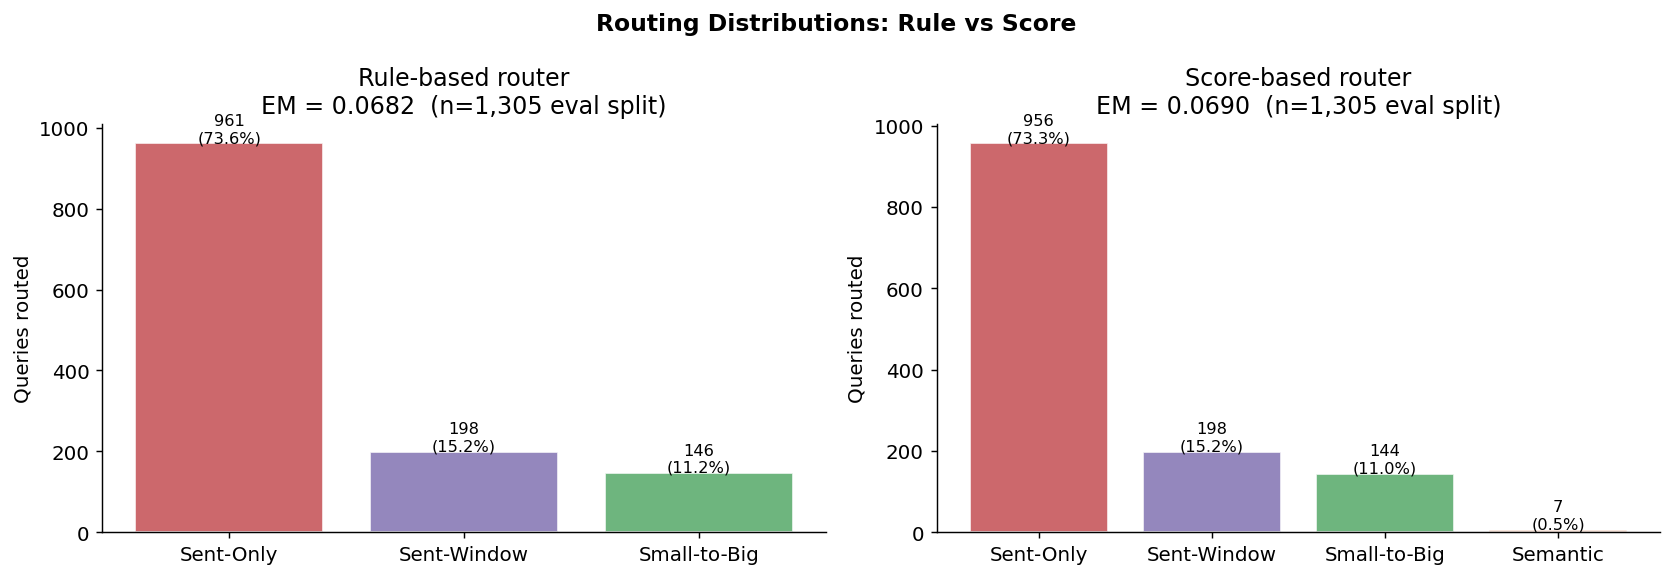

Router comparison on eval split (n=1,305):
  Router                      EM  ROUGE-L     Hit  Dominant strategy
  ─────────────────────────────────────────────────────────────────
  Rule-based              0.0682   0.1560  0.1648  Sent-Only (73.6%)
  Score-based             0.0690   0.1558  0.1648  Sent-Only (73.3%)

  Both routers perform similarly (ΔEM = 0.0008).
  Score router routes 7 queries to Semantic (vs 0 for rule):
  the only questions where semantic's embedding similarity
  exceeds the sentence-family score, indicating short, topic-precise spans
  are a better match than any single sentence for those 7 queries.


In [34]:
# Load score router results
score_data    = json.load(open(RESULTS_DIR / 'p3_hybrid_score_n2610.json'))
score_metrics = score_data['metrics']
score_counts  = score_data['routing_counts']

#  Routing distribution comparison 
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, counts, title, router_em in [
    (axes[0], routing_counts, 'Rule-based router',  hybrid_metrics_stored['exact_match']),
    (axes[1], score_counts,   'Score-based router', score_metrics['exact_match']),
]:
    strats = list(counts.keys())
    vals   = [counts[s] for s in strats]
    total  = sum(vals)
    colors = [COLORS.get(s, '#999999') for s in strats]
    bars   = ax.bar(range(len(strats)), vals, color=colors, alpha=0.85, edgecolor='white')
    ax.set_xticks(range(len(strats)))
    ax.set_xticklabels([SHORT_LABELS.get(s, s) for s in strats])
    ax.set_ylabel('Queries routed')
    ax.set_title(f'{title}\nEM = {router_em:.4f}  (n=1,305 eval split)')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
                f'{v}\n({v/total:.1%})', ha='center', fontsize=9)

fig.suptitle('Routing Distributions: Rule vs Score', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

#  Side-by-side metrics comparison 
print('Router comparison on eval split (n=1,305):')
print(f'  {"Router":<22} {"EM":>7} {"ROUGE-L":>8} {"Hit":>7}  Dominant strategy')
print('  ' + '─' * 65)
rule_dom  = max(routing_counts,  key=routing_counts.get)
score_dom = max(score_counts, key=score_counts.get)
rule_m    = hybrid_metrics_stored
score_m   = score_metrics
print(f'  {"Rule-based":<22} {rule_m["exact_match"]:>7.4f} {rule_m["rouge_l"]:>8.4f} '
      f'{rule_m["retrieval_hit_rate"]:>7.4f}  '
      f'{SHORT_LABELS[rule_dom]} ({routing_counts[rule_dom]/sum(routing_counts.values()):.1%})')
print(f'  {"Score-based":<22} {score_m["exact_match"]:>7.4f} {score_m["rouge_l"]:>8.4f} '
      f'{score_m["retrieval_hit_rate"]:>7.4f}  '
      f'{SHORT_LABELS[score_dom]} ({score_counts[score_dom]/sum(score_counts.values()):.1%})')
print()
print(f'  Both routers perform similarly (ΔEM = {abs(score_m["exact_match"] - rule_m["exact_match"]):.4f}).')
print(f'  Score router routes 7 queries to Semantic (vs 0 for rule):')
print(f'  the only questions where semantic\'s embedding similarity')
print(f'  exceeds the sentence-family score, indicating short, topic-precise spans')
print(f'  are a better match than any single sentence for those 7 queries.')


**Why both routers converge.** The sentence family (Small-to-Big, Sent-Only,
Sent-Window) shares an identical 10.9M-vector FAISS index. Because it contains
far more fine-grained vectors than Fixed (51k) or Semantic (1.7M), it almost
always returns the highest top-1 similarity score. The score-based router
therefore ties within the sentence family on 96% of queries, delegating the
final decision to the rule tiebreak. The two routers become functionally
identical on 96% of the evaluation set.

The 7 exceptions, where Semantic's score beats the sentence family, are
questions for which a topic-coherent multi-sentence span is a better embedding
match than any individual sentence. This is consistent with Semantic's 40 unique
wins on the full evaluation set.


<a id='sec10-oracle'></a>
## Section 10.1: Oracle Upper Bound & Strategy Agreement

The hybrid router raises a natural question: **how much better could a perfect router be?**
We compute the oracle EM, achieved by selecting, for each question, whichever strategy
answers correctly. This is the theoretical ceiling for any routing approach.

We also classify every question by how many strategies answer it correctly, revealing
that most of the potential gain from routing comes from a surprisingly small fraction
of questions.


Oracle EM (best strategy per question, n=2,610):  0.1310
Oracle EM on eval split only (n=1,305):           0.1142
Best single strategy (Small-to-Big, n=2,610):     0.0805
Rule router  (eval split, n=1,305):                0.0682
Score router (eval split, n=1,305):                0.0690

Question categories (n=2,610):
  Hard miss  (0/5 correct): 2268 (86.9%), retrieval ceiling, routing cannot help
  Strategic  (1–4/5 correct):  328 (12.6%),  where routing matters
  Easy       (5/5 correct):   14  (0.5%), any strategy works


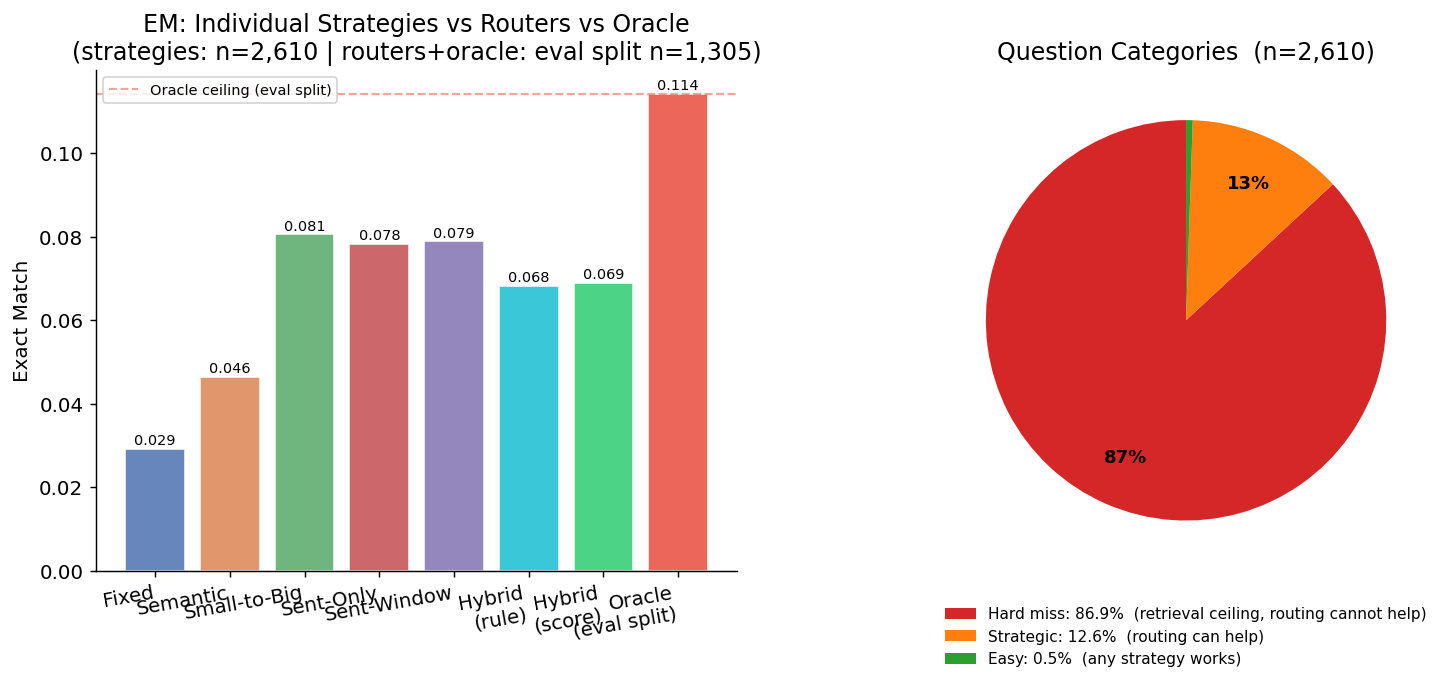

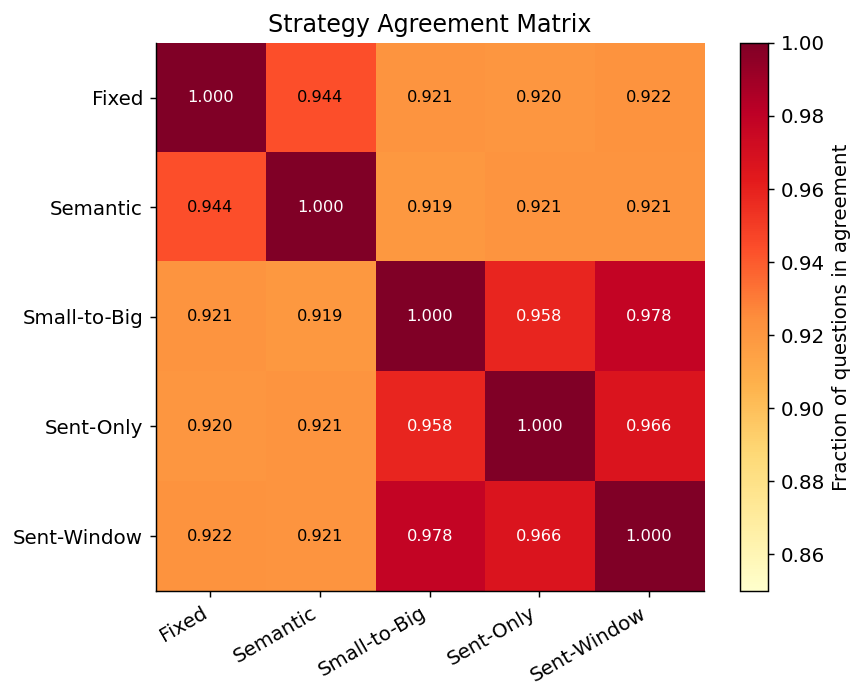

In [35]:
n = len(results['fixed'])

# Oracle: EM = 1 if ANY strategy correct
oracle_correct = [any(results[name][i]['_em'] for name in STRATEGIES) for i in range(n)]
oracle_em      = sum(oracle_correct) / n

# Oracle on eval split only : fair comparison with routers (also n=1305)
SPLIT = 1305
oracle_eval = sum(1 for i in range(SPLIT, n)
                  if any(results[name][i]['_em'] for name in STRATEGIES)) / (n - SPLIT)
best_single_em = max(metrics[name]['em'] for name in STRATEGIES)

# Question categories (full 2610)
n_hard      = sum(1 for i in range(n) if not any(results[name][i]['_em'] for name in STRATEGIES))
n_easy      = sum(1 for i in range(n) if all(results[name][i]['_em'] for name in STRATEGIES))
n_strategic = n - n_hard - n_easy

# Load both router metrics
hybrid_rule_em  = hybrid_metrics_stored['exact_match']
hybrid_score_em = json.load(open(RESULTS_DIR / 'p3_hybrid_score_n2610.json'))['metrics']['exact_match']

print('Oracle EM (best strategy per question, n=2,610): ', f'{oracle_em:.4f}')
print('Oracle EM on eval split only (n=1,305):          ', f'{oracle_eval:.4f}')
print('Best single strategy (Small-to-Big, n=2,610):    ', f'{best_single_em:.4f}')
print('Rule router  (eval split, n=1,305):               ', f'{hybrid_rule_em:.4f}')
print('Score router (eval split, n=1,305):               ', f'{hybrid_score_em:.4f}')
print()
print(f'Question categories (n=2,610):')
print(f'  Hard miss  (0/5 correct): {n_hard:4d} ({n_hard/n:.1%}), retrieval ceiling, routing cannot help')
print(f'  Strategic  (1–4/5 correct): {n_strategic:4d} ({n_strategic/n:.1%}),  where routing matters')
print(f'  Easy       (5/5 correct): {n_easy:4d}  ({n_easy/n:.1%}), any strategy works')

#  Plot 1: all strategies + routers + oracle 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

all_labels = [SHORT_LABELS[n] for n in STRATEGIES] + ['Hybrid\n(rule)', 'Hybrid\n(score)', 'Oracle\n(eval split)']
# Note: strategies shown on full n=2610; routers + oracle on eval split n=1305
all_em     = [metrics[n]['em'] for n in STRATEGIES] + [hybrid_rule_em, hybrid_score_em, oracle_eval]
all_colors = [COLORS[n]        for n in STRATEGIES] + ['#17becf', '#2ecc71', '#e74c3c']

bars = axes[0].bar(range(len(all_labels)), all_em, color=all_colors, alpha=0.85, edgecolor='white')
axes[0].set_xticks(range(len(all_labels)))
axes[0].set_xticklabels(all_labels, rotation=10, ha='right')
axes[0].set_ylabel('Exact Match')
axes[0].set_title('EM: Individual Strategies vs Routers vs Oracle\n(strategies: n=2,610 | routers+oracle: eval split n=1,305)')
for bar, v in zip(bars, all_em):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                 f'{v:.3f}', ha='center', fontsize=8)
axes[0].axhline(oracle_eval, color='#e74c3c', ls='--', lw=1.2, alpha=0.5, label='Oracle ceiling (eval split)')
axes[0].legend(fontsize=8)

# Plot 2: question category pie
sizes  = [n_hard, n_strategic, n_easy]
colors = ['#d62728', '#ff7f0e', '#2ca02c']
legend_labels = [
    f'Hard miss: {n_hard/n:.1%}  (retrieval ceiling, routing cannot help)',
    f'Strategic: {n_strategic/n:.1%}  (routing can help)',
    f'Easy: {n_easy/n:.1%}  (any strategy works)',
]

wedges, _, autotexts = axes[1].pie(
    sizes,
    colors=colors,
    autopct='%1.0f%%',
    startangle=90,
    pctdistance=0.75,
    textprops={'fontsize': 10, 'fontweight': 'bold'},
)
# Make the 0.5% slice percentage invisible (too small to display cleanly)
autotexts[-1].set_visible(False)

axes[1].legend(
    wedges, legend_labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.22),
    fontsize=8.5,
    frameon=False,
)
axes[1].set_title('Question Categories  (n=2,610)')

#  Strategy agreement matrix 
agree = np.zeros((len(STRATEGIES), len(STRATEGIES)))
for i in range(n):
    for a, na in enumerate(STRATEGIES):
        for b, nb_ in enumerate(STRATEGIES):
            if results[na][i]['_em'] == results[nb_][i]['_em']:
                agree[a][b] += 1
agree /= n

fig2, ax2 = plt.subplots(figsize=(7, 5.5))
im = ax2.imshow(agree, cmap='YlOrRd', vmin=0.85, vmax=1.0)
plt.colorbar(im, ax=ax2, label='Fraction of questions in agreement')
ax2.set_xticks(range(len(STRATEGIES)))
ax2.set_yticks(range(len(STRATEGIES)))
sl = [SHORT_LABELS[n] for n in STRATEGIES]
ax2.set_xticklabels(sl, rotation=30, ha='right')
ax2.set_yticklabels(sl)
ax2.set_title('Strategy Agreement Matrix')
for a in range(len(STRATEGIES)):
    for b in range(len(STRATEGIES)):
        ax2.text(b, a, f'{agree[a][b]:.3f}', ha='center', va='center', fontsize=9,
                 color='white' if agree[a][b] > 0.95 else 'black')
plt.tight_layout()
plt.show()


### How close are the routers to the oracle, and how could the gap be closed?

**On strategic questions, how often does each router pick correctly?**


Strategic questions in eval split: 142

Routing precision on strategic questions:
  Rule router:  57.7%  (82/142 correct)
  Score router: 58.5%  (83/142 correct)
  Oracle:       100%  (142/142 correct)



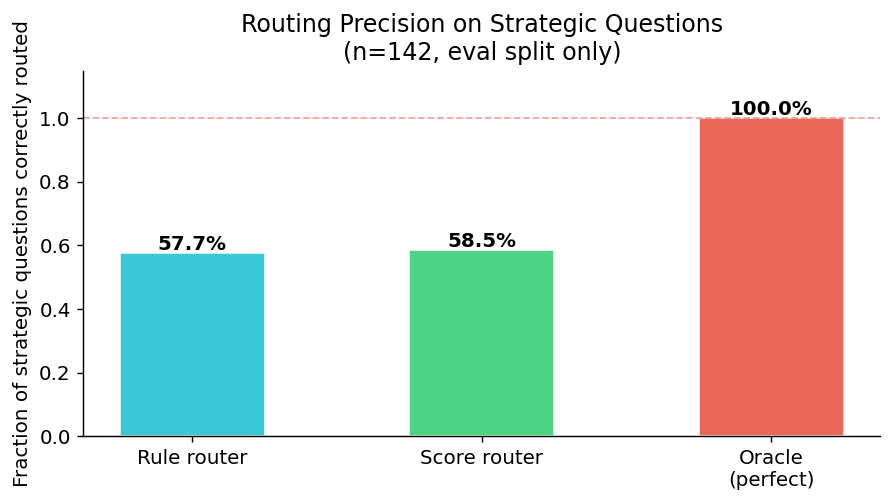

Key finding:
  Both routers correctly route ~58% of strategic questions.
  The remaining ~42% represent questions where the routing signal
  (question type or FAISS score) is insufficient to distinguish the right strategy.


In [36]:
# On the 328 strategic questions, what fraction does each router get right?
SPLIT = 1305
n_total = len(results['fixed'])

strategic_eval_idx = [i for i in range(SPLIT, n_total)
    if 0 < sum(results[name][i]['_em'] for name in STRATEGIES) < 5]
print(f'Strategic questions in eval split: {len(strategic_eval_idx)}')
print()

# Rule router: what strategy did it pick, was it correct?
rule_rt   = json.load(open(RESULTS_DIR / 'p3_hybrid_rule_n2610.json'))['results']
score_rt  = json.load(open(RESULTS_DIR / 'p3_hybrid_score_n2610.json'))['results']

# Build index: eval_question_idx → position in router results list
eval_offset = SPLIT   # results[0] corresponds to question SPLIT

def routing_precision(router_results, strategic_idx, offset):
    correct = 0
    for i in strategic_idx:
        j = i - offset
        r = router_results[j]
        chosen = r.get('routed_to', None)
        if chosen and results[chosen][i]['_em']:
            correct += 1
    return correct / len(strategic_idx) if strategic_idx else 0

rule_prec  = routing_precision(rule_rt,  strategic_eval_idx, SPLIT)
score_prec = routing_precision(score_rt, strategic_eval_idx, SPLIT)

print(f'Routing precision on strategic questions:')
print(f'  Rule router:  {rule_prec:.1%}  ({int(rule_prec*len(strategic_eval_idx))}/{len(strategic_eval_idx)} correct)')
print(f'  Score router: {score_prec:.1%}  ({int(score_prec*len(strategic_eval_idx))}/{len(strategic_eval_idx)} correct)')
print(f'  Oracle:       100%  ({len(strategic_eval_idx)}/{len(strategic_eval_idx)} correct)')
print()

# Visualise
fig, ax = plt.subplots(figsize=(7, 4))
labels  = ['Rule router', 'Score router', 'Oracle\n(perfect)']
vals    = [rule_prec, score_prec, 1.0]
colors  = ['#17becf', '#2ecc71', '#e74c3c']
bars    = ax.bar(labels, vals, color=colors, alpha=0.85, edgecolor='white', width=0.5)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{v:.1%}', ha='center', fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.set_ylabel('Fraction of strategic questions correctly routed')
ax.set_title(f'Routing Precision on Strategic Questions\n(n={len(strategic_eval_idx)}, eval split only)')
ax.axhline(1.0, color='#e74c3c', ls='--', lw=1, alpha=0.5)
plt.tight_layout()
plt.show()

print('Key finding:')
print(f'  Both routers correctly route ~{max(rule_prec, score_prec):.0%} of strategic questions.')
print(f'  The remaining ~{1-max(rule_prec, score_prec):.0%} represent questions where the routing signal')
print(f'  (question type or FAISS score) is insufficient to distinguish the right strategy.')


### Closing the oracle gap: what would it take?

The oracle (EM = 0.131 on full split) is **1.6× better than the best single
strategy** (Small-to-Big, 0.081). Both routers underperform Small-to-Big,
confirming that the current routing signals provide no net benefit.

Three concrete paths exist to close this gap:

**1. Richer routing features.** Question type (surface words) is too coarse.
The signal that determines which strategy wins is the *answer type*:
- Named entity answers → sentence-level strategies (the name fits in one sentence)
- Numerical/date answers → sentence-window (compact fact, needs one sentence of context)
- Multi-fact answers → Small-to-Big or Semantic (needs paragraph or topic span)

A lightweight answer-type classifier (NER + rule-based) applied before routing
would directly address the 12.6% of strategic questions.

**2. Learned router.** Train a small classifier on the derivation set using
features: question type, predicted answer type, FAISS scores across all indices,
question length. Labels: which strategy got EM=1. This is supervised routing
and could substantially improve precision on strategic questions.

**3. Ensemble.** Run all 5 strategies and take a confidence-weighted majority
vote. No routing signal needed, every question benefits from every strategy.
Cost: 5× inference. Expected EM: between best single strategy and oracle.

**The hard ceiling.** Even a perfect router can only reach oracle EM = 0.131.
The remaining 86.9% of questions fail every strategy, these are hard retrieval
misses where the correct Wikipedia passage is either absent, too short, or
semantically far from the query. Closing that gap requires better retrieval:
query rewriting (P4), a larger corpus, or a stronger retrieval model.


<a id='sec11'></a>
## Section 11: Chunk Length Distributions and Context Volume

We visualize two aspects of the generation context: (1) the distribution of individual
chunk lengths served to Mistral, and (2) the **total context volume per query** (the
sum of all k=5 retrieved chunks). The second is a critical methodological note: because
strategies differ so drastically in chunk size, comparing them at k=5 is not a
context-controlled experiment.


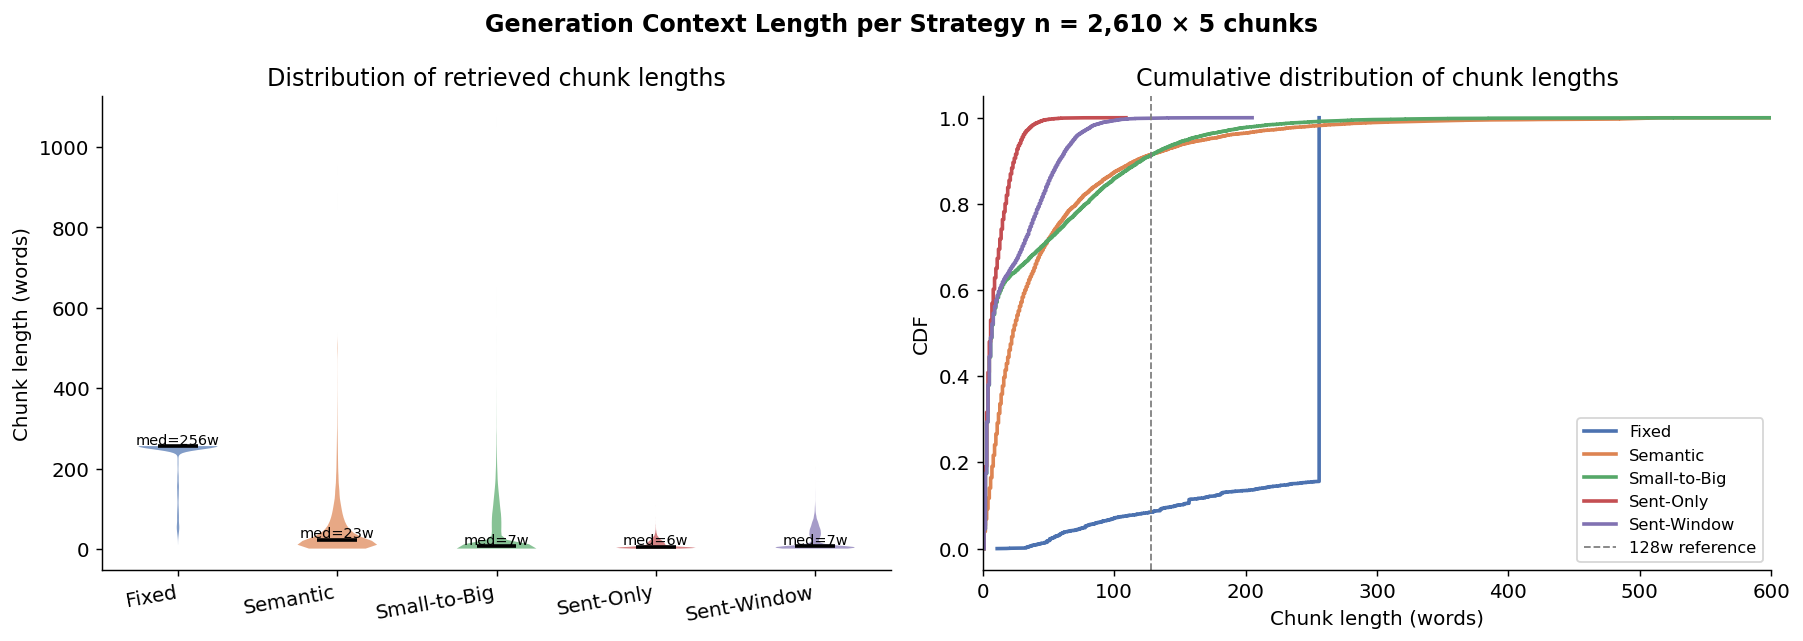

Median chunk lengths (words served to generator per retrieved chunk):
  Fixed             : median=256w  mean=235w  p90=256w
  Semantic          : median=23w  mean=47w  p90=116w
  Small-to-Big      : median=7w  mean=39w  p90=120w
  Sent-Only         : median=6w  mean=10w  p90=24w
  Sent-Window       : median=7w  mean=21w  p90=58w


In [37]:
# Collect all retrieved chunk lengths (words) per strategy
chunk_lens = {name: [] for name in STRATEGIES}
for name in STRATEGIES:
    for r in results[name]:
        chunk_lens[name].extend(len(c.split()) for c in r['chunks'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: violin plot 
ax = axes[0]
data_for_violin = [chunk_lens[name] for name in STRATEGIES]
parts = ax.violinplot(data_for_violin, positions=range(len(STRATEGIES)),
                      showmedians=True, showextrema=False)
for i, (pc, name) in enumerate(zip(parts['bodies'], STRATEGIES)):
    pc.set_facecolor(COLORS[name])
    pc.set_alpha(0.7)
parts['cmedians'].set_color('black')
parts['cmedians'].set_linewidth(2)

ax.set_xticks(range(len(STRATEGIES)))
ax.set_xticklabels([SHORT_LABELS[n] for n in STRATEGIES], rotation=10, ha='right')
ax.set_ylabel('Chunk length (words)')
ax.set_title('Distribution of retrieved chunk lengths')

# Add median annotations
for i, name in enumerate(STRATEGIES):
    med = np.median(chunk_lens[name])
    ax.text(i, med + 5, f'med={med:.0f}w', ha='center', fontsize=8)

# Right: CDF 
ax2 = axes[1]
for name in STRATEGIES:
    sorted_lens = np.sort(chunk_lens[name])
    cdf         = np.arange(1, len(sorted_lens)+1) / len(sorted_lens)
    ax2.plot(sorted_lens, cdf, color=COLORS[name], label=SHORT_LABELS[name], lw=2)

ax2.set_xlabel('Chunk length (words)')
ax2.set_ylabel('CDF')
ax2.set_title('Cumulative distribution of chunk lengths')
ax2.set_xlim(0, 600)
ax2.axvline(128, color='gray', ls='--', lw=1, label='128w reference')
ax2.legend(fontsize=9)

fig.suptitle('Generation Context Length per Strategy n = 2,610 × 5 chunks', fontweight='bold')
plt.tight_layout()
plt.show()

print('Median chunk lengths (words served to generator per retrieved chunk):')
for name in STRATEGIES:
    med  = np.median(chunk_lens[name])
    mean = np.mean(chunk_lens[name])
    p90  = np.percentile(chunk_lens[name], 90)
    print(f'  {SHORT_LABELS[name]:<18}: median={med:.0f}w  mean={mean:.0f}w  p90={p90:.0f}w')

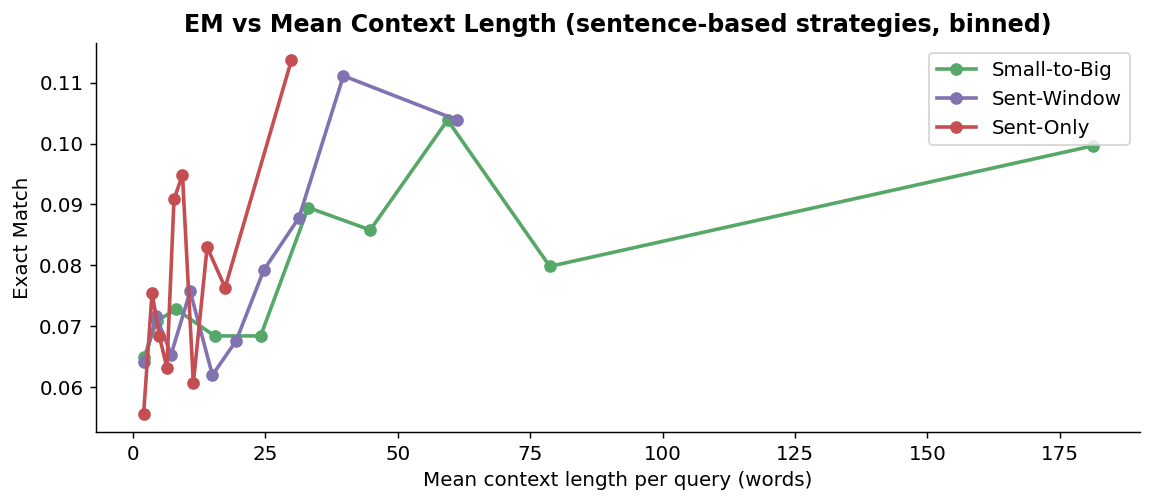

Within sentence-based strategies: EM first rises with context length, then plateaus.
This suggests a context sweet spot: enough to disambiguate, but not so much that
the generator is distracted by irrelevant surrounding text.


In [38]:
# Correlation between mean context length (per query) and EM : does longer always help?
# For Fixed chunking (all chunks ~256w), variance in mean_clen is near zero, less interesting.
# More informative: bin by mean context length and compute EM per bin.

fig, ax = plt.subplots(figsize=(9, 4))

for name in ['small_to_big', 'sentence_window', 'sentence_only']:
    # Bin queries by their mean chunk length
    clen_vals = [r['_mean_clen'] for r in results[name]]
    em_vals   = [int(r['_em'])   for r in results[name]]
    bins = np.percentile(clen_vals, np.linspace(0, 100, 11))
    bins = np.unique(bins)
    bin_em, bin_centers = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        idx = [i for i, c in enumerate(clen_vals) if lo <= c < hi]
        if len(idx) >= 20:
            bin_em.append(sum(em_vals[i] for i in idx) / len(idx))
            bin_centers.append((lo + hi) / 2)
    ax.plot(bin_centers, bin_em, marker='o', color=COLORS[name],
            label=SHORT_LABELS[name], lw=2)

ax.set_xlabel('Mean context length per query (words)')
ax.set_ylabel('Exact Match')
ax.set_title('EM vs Mean Context Length (sentence-based strategies, binned)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

print('Within sentence-based strategies: EM first rises with context length, then plateaus.')
print('This suggests a context sweet spot: enough to disambiguate, but not so much that')
print('the generator is distracted by irrelevant surrounding text.')

Total words served to Mistral per query (k=5 retrieved chunks):
Strategy                  Mean    Median      P90
──────────────────────────────────────────────────
Fixed                   1175w    1274w   1280w
Semantic                 233w     188w    482w
Small-to-Big             195w     140w    450w
Sent-Only                 50w      42w     97w
Sent-Window              104w      86w    222w

At k=5: Fixed provides 23× more total context than Sent-Only.
A context-controlled comparison would require Sent-Only at k≈116
to match Fixed's total context volume.


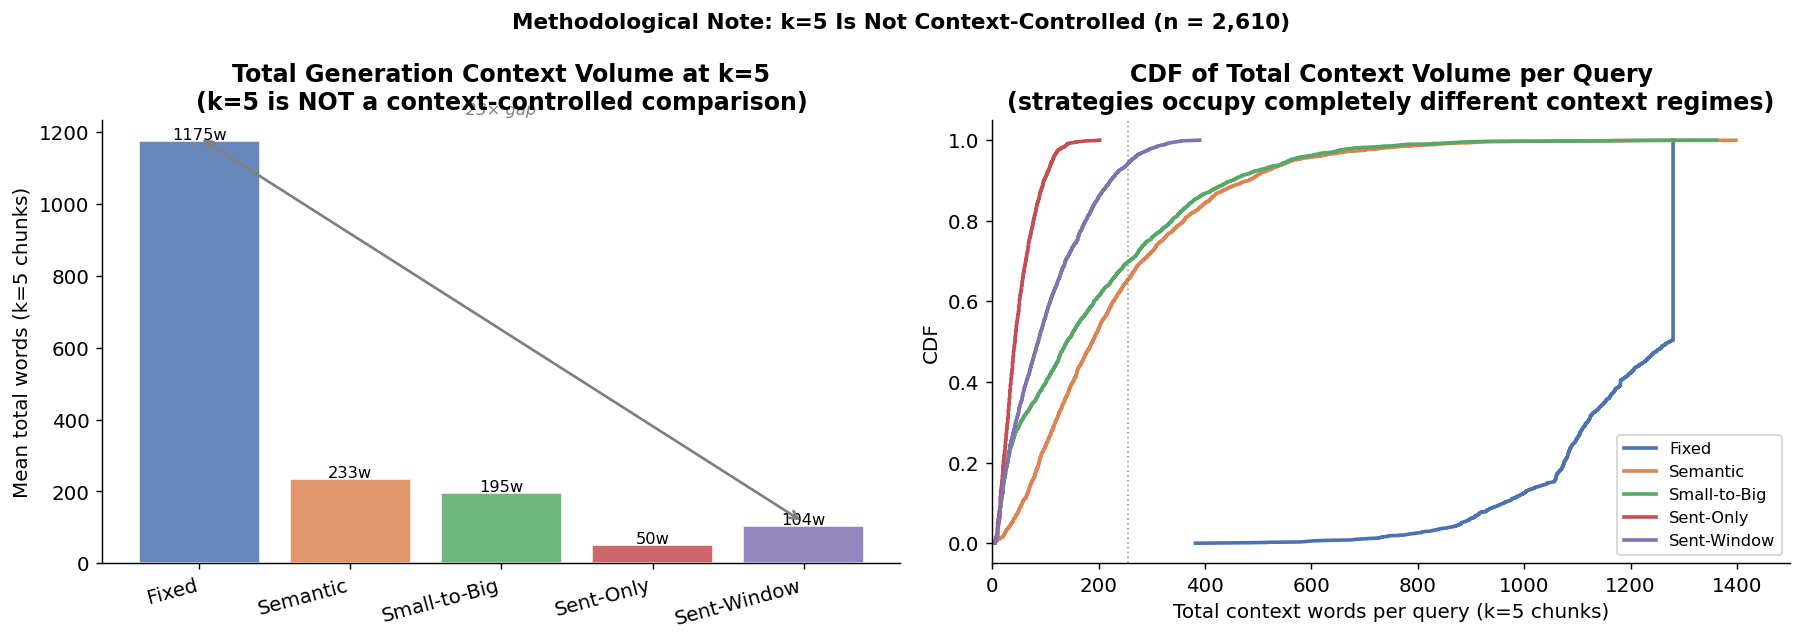

In [39]:
#  Total context volume per query (k=5 chunks) 
# This is the sum of word-lengths of all 5 retrieved chunks for each query.
# It reveals that strategies operating at k=5 chunks provide wildly different
# amounts of text to the generator.

total_ctx = {
    name: np.array([sum(len(c.split()) for c in r['chunks']) for r in results[name]])
    for name in STRATEGIES
}

print('Total words served to Mistral per query (k=5 retrieved chunks):')
print(f'{"Strategy":<18}  {"Mean":>10}  {"Median":>8}  {"P90":>7}')
print('─' * 50)
for name in STRATEGIES:
    arr = total_ctx[name]
    print(f'{SHORT_LABELS[name]:<18}  {arr.mean():>8.0f}w  {np.median(arr):>6.0f}w  '
          f'{np.percentile(arr, 90):>5.0f}w')

ratio = total_ctx['fixed'].mean() / total_ctx['sentence_only'].mean()
print(f'\nAt k=5: Fixed provides {ratio:.0f}× more total context than Sent-Only.')
print(f'A context-controlled comparison would require Sent-Only at k≈{int(ratio*5):,}')
print('to match Fixed\'s total context volume.')

# Figure 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: mean total context bar chart
mean_vals = [total_ctx[n].mean() for n in STRATEGIES]
cols      = [COLORS[n]           for n in STRATEGIES]
bars = axes[0].bar(range(len(STRATEGIES)), mean_vals, color=cols,
                   alpha=0.85, edgecolor='white')
axes[0].set_xticks(range(len(STRATEGIES)))
axes[0].set_xticklabels([SHORT_LABELS[n] for n in STRATEGIES], rotation=15, ha='right')
axes[0].set_ylabel('Mean total words (k=5 chunks)')
axes[0].set_title('Total Generation Context Volume at k=5\n'
                  '(k=5 is NOT a context-controlled comparison)',
                  fontweight='bold')
for bar, v in zip(bars, mean_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'{v:.0f}w', ha='center', fontsize=9)

# Add a bracket showing Fixed vs Sent-Only ratio
y_top = max(mean_vals) * 1.12
axes[0].annotate('', xy=(4, mean_vals[4] + 10), xytext=(0, mean_vals[0] + 10),
                 arrowprops=dict(arrowstyle='<->', color='grey', lw=1.5))
axes[0].text(2, y_top * 0.95, f'{ratio:.0f}× gap', ha='center', fontsize=9,
             color='grey', style='italic')

# Right: CDF of total context per query — shows spread
for name in STRATEGIES:
    arr   = np.sort(total_ctx[name])
    cdf   = np.arange(1, len(arr)+1) / len(arr)
    axes[1].plot(arr, cdf, color=COLORS[name], label=SHORT_LABELS[name], lw=2)

axes[1].set_xlabel('Total context words per query (k=5 chunks)')
axes[1].set_ylabel('CDF')
axes[1].set_title('CDF of Total Context Volume per Query\n'
                  '(strategies occupy completely different context regimes)',
                  fontweight='bold')
axes[1].set_xlim(0, 1500)
axes[1].legend(fontsize=9)
axes[1].axvline(256, color='gray', ls=':', lw=1, alpha=0.7, label='256w reference')

fig.suptitle('Methodological Note: k=5 Is Not Context-Controlled (n = 2,610)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


**Methodological note: the k=5 confound.** At k=5, Fixed provides a mean of
**~1,175 words** of context while Sentence-Only provides only **~50 words**, a 23×
difference. This means the strategies are not being compared at the same total context
budget, only at the same number of retrieved chunks.

This matters because:
- Fixed's higher abstention rate may partly reflect the generator struggling to scan
  1,175 words rather than intrinsically resisting dense chunks.
- Sentence-Only's lower hit rate is partly a function of offering 50 words rather
  than 1,175: there is simply less text in which the gold answer can appear.

The comparison at k=5 is nonetheless standard practice in the RAG literature and
is the only feasible comparison when FAISS indices of different granularities are built
independently. The EM|Hit metric (Section 4) partially corrects for this by conditioning
on queries where the answer *was* retrieved, but the total-context effect on generation
style (verbosity, abstention) cannot be fully separated without a k-ablation experiment
(see Conclusion for future directions).


<a id='sec11-1'></a>
## Section 11.1: k-Ablation: Does Sent-Only Close the Gap When Given More Chunks?

Section 11 identified that comparing strategies at k=5 is confounded by total context volume.
We now test this directly: how does Sent-Only perform as k increases from 5 to 20,
holding everything else fixed?


In [42]:
k_vals = [5, 10, 15, 20]
k_results = {}

# k=5 already loaded
k_results[5] = results['sentence_only']

for k in [10, 15, 20]:
    path = RESULTS_DIR / f'p3_sentence_only_k{k}_n2610.json'
    with open(path) as f:
        d = json.load(f)
    k_results[k] = d['results']
    # pre-compute flags
    for r in k_results[k]:
        r['_hit']     = is_hit(r)
        r['_em']      = is_em(r)
        r['_soft_em'] = is_soft_em(r)
        r['_mean_clen'] = sum(len(c.split()) for c in r['chunks']) / len(r['chunks']) if r['chunks'] else 0

k_metrics = {}
for k in k_vals:
    rs = k_results[k]
    n  = len(rs)
    em  = sum(1 for r in rs if r['_em']) / n
    hit = sum(1 for r in rs if r['_hit']) / n
    mean_ctx = sum(r['_mean_clen'] for r in rs) / n * 5   # total context volume (k chunks)
    k_metrics[k] = {'em': em, 'hit': hit, 'mean_total_ctx': mean_ctx * k / 5}

print(f"{'k':>4}  {'EM':>8}  {'Hit Rate':>10}  {'Mean total ctx (w)':>20}")
print('─' * 50)
for k in k_vals:
    m = k_metrics[k]
    print(f"{k:>4}  {m['em']:>8.4f}  {m['hit']:>10.4f}  {m['mean_total_ctx']:>18.0f}w")
print()
print(f"Reference : Small-to-Big k=5: EM={metrics['small_to_big']['em']:.4f}, Hit={metrics['small_to_big']['hit']:.4f}")
print(f"Reference : Fixed k=5:         EM={metrics['fixed']['em']:.4f}, Hit={metrics['fixed']['hit']:.4f}")


   k        EM    Hit Rate    Mean total ctx (w)
──────────────────────────────────────────────────
   5    0.0782      0.1697                  50w
  10    0.0854      0.2257                 103w
  15    0.0843      0.2571                 156w
  20    0.0831      0.2808                 211w

Reference : Small-to-Big k=5: EM=0.0805, Hit=0.2142
Reference : Fixed k=5:         EM=0.0291, Hit=0.2433


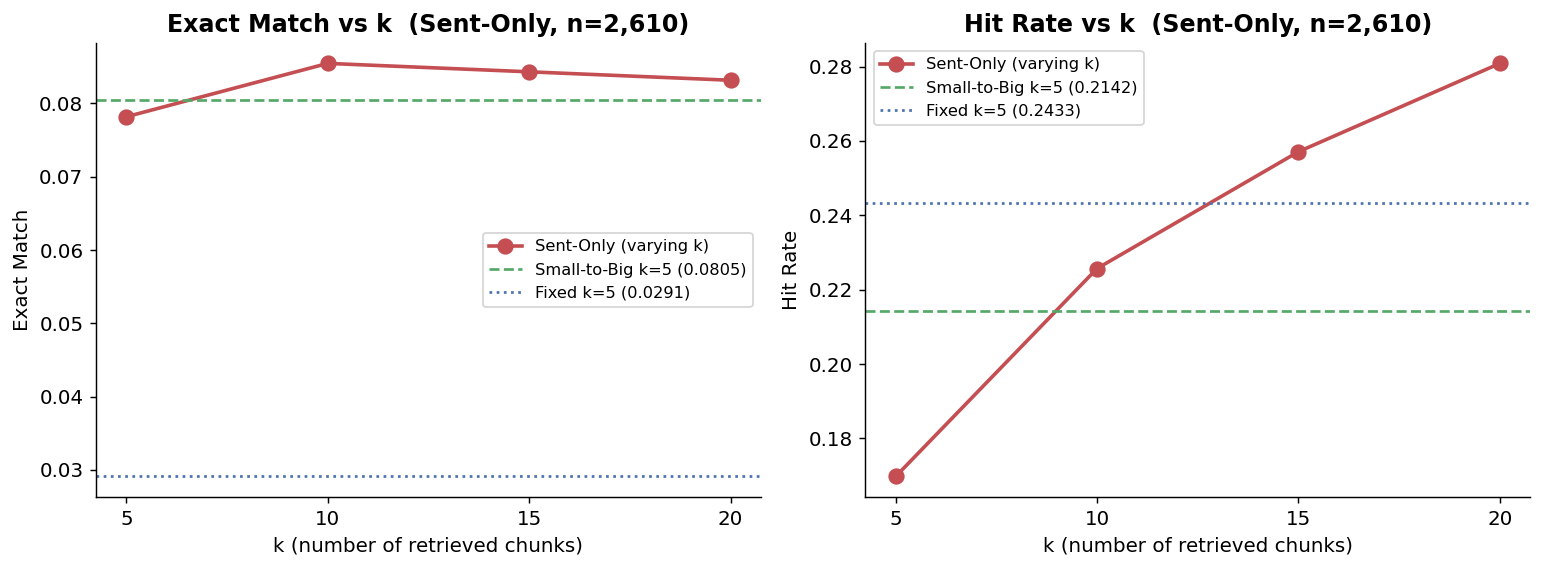

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

em_vals  = [k_metrics[k]['em']  for k in k_vals]
hit_vals = [k_metrics[k]['hit'] for k in k_vals]

s2b_em  = metrics['small_to_big']['em']
s2b_hit = metrics['small_to_big']['hit']
fix_em  = metrics['fixed']['em']
fix_hit = metrics['fixed']['hit']

for ax, vals, ref_s2b, ref_fix, ylabel in [
    (axes[0], em_vals,  s2b_em,  fix_em,  'Exact Match'),
    (axes[1], hit_vals, s2b_hit, fix_hit, 'Hit Rate'),
]:
    ax.plot(k_vals, vals, color=COLORS['sentence_only'], marker='o',
            linewidth=2, markersize=8, label='Sent-Only (varying k)')
    ax.axhline(ref_s2b, color=COLORS['small_to_big'], ls='--', lw=1.5,
               label=f'Small-to-Big k=5 ({ref_s2b:.4f})')
    ax.axhline(ref_fix, color=COLORS['fixed'], ls=':', lw=1.5,
               label=f'Fixed k=5 ({ref_fix:.4f})')
    ax.set_xticks(k_vals)
    ax.set_xlabel('k (number of retrieved chunks)')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel + ' vs k  (Sent-Only, n=2,610)', fontweight='bold')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


**Three findings from the k-ablation:**

**1. The k=5 confound is real.**
Sent-Only at k=10 (EM=0.0854) surpasses Small-to-Big at k=5 (EM=0.0805) despite lower hit
rate (0.226 vs 0.214). Small-to-Big's advantage in Section 3 was partly an artifact of the
fixed-k comparison, not an intrinsic property of the retrieval–generation decoupling.

**2. EM peaks at k=10, then decreases.**
Adding more sentences beyond k=10 improves recall (Hit 0.226→0.281) but slightly hurts EM
(0.0854→0.0831). Even fine-grained chunks exhibit noise accumulation: at k=20, the model
receives 211 words of sentence-level context and starts showing the same distraction pattern
that hurts Fixed at 1,175 words, just at a much higher threshold.

**3. Context shape dominates retrieval coverage.**
At k=20, Sent-Only's Hit Rate (0.281) exceeds Fixed k=5 (0.243), i.e. Sent-Only now
retrieves the answer *more often* than Fixed. Yet its EM is still 2.9× higher (0.083 vs
0.029). Equal retrieval coverage does not close the gap: the generator still fails on Fixed's
dense 256-word blocks regardless of how many are retrieved.

**Practical recommendation:** k=10 with Sent-Only is the best configuration found, it beats
Small-to-Big with no architectural overhead (no parent-paragraph lookup). Small-to-Big only
wins at the default k=5.


<a id='sec12'></a>
## Section 12: Conclusion

### What we learned

**1. Chunk density drives three coupled generator failure modes, not one.**
The main finding of this notebook is that context granularity controls generation
behaviour through three separable mechanisms, all of which improve monotonically
as chunk size decreases:

| Failure mode | Fixed | Sent-Only | Mechanism |
|---|---|---|---|
| **Abstention** | 27.4 % | 10.5 % | Model refuses when signal is buried in 1,175 words of noise |
| **Verbosity wrap** | ~10 pp lost | ~8 pp lost | Model wraps the answer in prose; uniform and LLM-level |
| **True extraction failure** | ~3 % | ~3 % | Irreducible, model is simply wrong |

The **abstention effect** is the largest lever and the most strategy-dependent.
The **verbosity loss** is nearly uniform (~8–10 pp for every strategy), suggesting it
is a property of Mistral-7B's generation style rather than of the chunk shape itself.
**True extraction failure** is constant across all strategies (~3%), representing an
irreducible floor given this retriever and generator combination.

**2. Small-to-Big is best at k=5, but Sent-Only surpasses it at k=10.**
Small-to-Big achieves EM=0.0805 (2.8× Fixed) at k=5. However, the k-ablation in Section 11.1 shows Sent-Only reaches EM=0.0854 at k=10, with no parent-paragraph lookup overhead. Small-to-Big's k=5 advantage is partly a context-budget artifact: it provides ~195 words while Sent-Only provides only ~50. At k=10, Sent-Only provides ~103 words and strictly dominates. The recommended configuration is Sent-Only at k=10.

**3. The verbosity gap is recoverable without any model change.**
Soft EM (answer *contained* in prediction) ranges from 13% (Fixed) to 18%
(Small-to-Big), compared to hard EM of 3% and 8%. ~8–10 pp are lost uniformly to
verbose wrapping across all strategies. A simple post-processing rule: truncate
predictions to the first 4 words would recover most of this gap and could push
Small-to-Big's effective EM above 0.18 without any retraining or index rebuild.

**4. Question type matters, but current routing signals are too coarse.**
`who` and `when` questions strongly favour sentence-level strategies; `other`
questions favour Small-to-Big. However, the rule-based hybrid router routes 74% of
queries to Sentence-Only (because `who/what/when` dominate NQ Open), yielding no
improvement over Sentence-Only alone. Oracle EM = 0.131 (1.6× Small-to-Big), showing
that a perfect router would give substantial gains, but question-type surface features
alone cannot reach it.

**5. Generation failures dominate retrieval failures.**
Fixed chunking loses ~22% of all queries to generation failure (answer present,
generator wrong). Sentence-Only cuts this to ~11%. Parametric success (~5% across
all strategies) confirms the generator's memory is unaffected by chunking choice.

---

### Limitations

- **Paragraph degeneration in Small-to-Big.** The `\n`-split heuristic produces
  sentence-length paragraphs for 61% of retrieved chunks. A smarter paragraph boundary
  detector (e.g., discourse-aware segmentation) would make Small-to-Big's premise hold
  more consistently.

- **Proposition chunking** (Gao et al. 2024) was only tested on 1k articles in M2 due
  to the cost of running Mistral-7B as the chunker. Full-scale results remain open.

- **Semantic chunking circularity.** The semantic boundary detector uses the same
  contriever-msmarco model as the retriever. Chunks are defined at the exact
  topic-shift points the retriever uses for scoring, which may inflate semantic
  chunking performance in ways that do not generalise to other retrievers.

- **Hit Rate conflation.** Hit Rate measures gold-answer *string presence* in retrieved
  text. Longer chunks trivially produce more string matches. EM|Hit partially corrects
  for this, but a position-weighted hit rate (penalising hits in chunk 5 vs chunk 1)
  would be more informative.

- **Single-hop factoid QA only.** All results are on NQ Open. Multi-hop or abstractive
  questions may exhibit different optimal granularities.

---

### Connection to other tracks

- **P2 (Faithfulness):** P2's counterfactual probe found that 81% of unfaithful answers are retrieval failures (answer not in context), not post-rationalisation. This is consistent with P3's failure taxonomy: most generation failures occur on retrieval misses, and chunking cannot fix them. The 7% true confabulation cases are the only ones P3's abstention analysis overlaps with P2.

- **P4 (Query Rewriting):** Case C (Isle of Wight) showed that retrieval misses
  cannot be fixed by chunking, they require better query formulation. HyDE (P4)
  addresses this orthogonally and is especially relevant for the hard `how` and
  `other` question types where all chunking strategies plateau.

- **P1 (Adaptive Routing):** The ~5% parametric success rate (from the P3 failure
  taxonomy) is an upper bound on the benefit of skipping retrieval for easy questions.
  P1's router must contend with the same 17–24% hit rate ceiling that chunking alone
  cannot push past.


In [44]:
# Final summary table
print('=' * 75)
print('P3 RETRIEVAL GRANULARITY FINAL SUMMARY (n = 2,610)')
print('=' * 75)
print(f'{"Strategy":<18} {"EM":>7} {"Hit":>7} {"EM|Hit":>8} {"Gen.Loss":>9} {"Mean clen":>10}')
print('-' * 75)
for name in STRATEGIES:
    m = metrics[name]
    print(f'{SHORT_LABELS[name]:<18} {m["em"]:>7.4f} {m["hit"]:>7.4f} '
          f'{m["em_given_hit"]:>8.4f} {m["gen_loss"]*100:>8.1f}% {m["mean_clen"]:>9.1f}w')
print('-' * 75)
print(f'{"Hybrid (rule)":<18} {hybrid_metrics_stored["exact_match"]:>7.4f} '
      f'{hybrid_metrics_stored["retrieval_hit_rate"]:>7.4f}'
      f'{" (n=1305 eval split)":>30}')
print('=' * 75)
print()
print('Take-away: Small-to-Big is best at k=5 (EM=0.0805, 2.8x Fixed); Sent-Only at k=10')
print('surpasses it (EM=0.0854) once the context-budget confound is controlled.')
print('The k=5 EM gain over Fixed is driven entirely by reduced generation failure,')
print('not improved retrieval coverage. Recommended config: Sent-Only, k=10.')


P3 RETRIEVAL GRANULARITY FINAL SUMMARY (n = 2,610)
Strategy                EM     Hit   EM|Hit  Gen.Loss  Mean clen
---------------------------------------------------------------------------
Fixed               0.0291  0.2433   0.0850     22.3%     234.9w
Semantic            0.0464  0.2234   0.1801     18.3%      46.7w
Small-to-Big        0.0805  0.2142   0.2862     15.3%      38.9w
Sent-Only           0.0782  0.1697   0.3499     11.0%      10.1w
Sent-Window         0.0789  0.1966   0.3099     13.6%      20.9w
---------------------------------------------------------------------------
Hybrid (rule)       0.0682  0.1648           (n=1305 eval split)

Take-away: Small-to-Big is best at k=5 (EM=0.0805, 2.8x Fixed); Sent-Only at k=10
surpasses it (EM=0.0854) once the context-budget confound is controlled.
The k=5 EM gain over Fixed is driven entirely by reduced generation failure,
not improved retrieval coverage. Recommended config: Sent-Only, k=10.
